# Selective Grasp Detection on **Jacquard V2** — FISAT 2026
### *When Not to Grasp: Distribution-Free Rejection Rules and Risk–Coverage Analysis*

Same pipeline as the Cornell notebook, pointed at Jacquard V2. Only the data
loader and the config differ; every model, metric, and analysis module is
identical and shared.

**Why Jacquard.** Cornell gives ~60 calibration samples, so the strict risk
budgets (alpha=0.05) can't be certified. Jacquard has ~51k images / 11k objects,
so calibration samples are abundant and those budgets become reachable — this is
the dataset that fixes the paper's main limitation.

**The cost is time.** Full Jacquard is DAYS on a single T4. The config ships with
`max_objects: 800` so the first run finishes in hours; set it to `null` for the
full dataset once the pipeline is confirmed.

| § | What | Cost |
|---|---|---|
| 0–4 | setup, write code, offline tests | seconds |
| 5 | Jacquard from Drive (sharded, large) | minutes–tens of minutes |
| 6–11 | train 2 models, cache scores, back up | hours (days at full scale) |
| 12–17 | the whole paper | seconds |

The artefacts you must not lose: `runs/*/best.pt` and `scores.npz`. Backup cells
follow each.

## 0. GPU

In [5]:
!nvidia-smi || echo "no GPU — Runtime > Change runtime type > GPU"

Sat Aug  1 07:13:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   47C    P0             58W /  400W |       6MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 1. Dependencies — install only what's missing

Same discipline as the Cornell notebook: a blanket `pip install` on Colab can
shift numpy and break the runtime mid-session. Install only genuinely-absent
packages, then health-check numpy.

In [6]:
import importlib

REQUIRED = [('numpy','numpy'), ('scipy','scipy'), ('PIL','pillow'),
            ('yaml','pyyaml'), ('matplotlib','matplotlib'),
            ('tifffile','tifffile'), ('imageio','imageio')]
missing = []
for mod, pkg in REQUIRED:
    try: importlib.import_module(mod)
    except Exception: missing.append(pkg)
if missing:
    print("installing:", missing)
    !pip install -q {" ".join(missing)}
    print("\n" + "*"*64)
    print("* If numpy changed: Runtime > Restart session, re-run from sec 2 *")
    print("*"*64)
else:
    print("all dependencies present — nothing installed")

all dependencies present — nothing installed


In [7]:
import numpy as np
try:
    _ = np.char.add(np.array(['a']), np.array(['b']))
    print("numpy", np.__version__, "healthy")
except Exception as e:
    print("NUMPY BROKEN (half-upgraded):", type(e).__name__, e)
    raise SystemExit("Runtime > Restart session, then re-run from section 2")
import torch, platform
print("python", platform.python_version(), "| torch", torch.__version__,
      "| cuda", torch.cuda.is_available())

numpy 2.0.2 healthy
python 3.12.13 | torch 2.11.0+cu128 | cuda True


## 2. Drive and paths

Jacquard is large and sharded; it's unzipped to local disk because reading tens
of thousands of small files over the Drive mount is far too slow to train on.

In [8]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE   = '/content/drive/MyDrive/PhD/fisat_jacquard'   # <-- your Drive folder
DATA    = '/content/data/jacquard'                      # local, fast
WORK    = '/content/fisat_j'
RESULTS = f'{WORK}/results'
for p in (WORK, RESULTS, DATA, DRIVE):
    os.makedirs(p, exist_ok=True)
os.chdir(WORK)
print("cwd:", os.getcwd())
print("drive contents:", os.listdir(DRIVE))

Mounted at /content/drive
cwd: /content/fisat_j
drive contents: ['JacquardV2_Dataset_1.zip', 'JacquardV2_Dataset_0.zip', 'JacquardV2_Dataset_2.zip', 'JacquardV2_Dataset_7.zip', 'JacquardV2_Dataset_4.zip', 'JacquardV2_Dataset_8.zip', 'JacquardV2_Dataset_3.zip', 'JacquardV2_Dataset_11.zip', 'JacquardV2_Dataset_9.zip', 'JacquardV2_Dataset_10.zip', 'JacquardV2_Dataset_5.zip', 'JacquardV2_Dataset_6.zip', 'results', 'runs', 'scores.npz']


## 3. Write the codebase

All modules embedded verbatim. `data_jacquard.py` is the only new file; the rest
are byte-identical to the Cornell notebook.

In [9]:
%%writefile data_jacquard.py
"""
data_jacquard.py
================
Jacquard V2 loader with the SAME constructor signature as the Cornell loader, so
train.py / extract_scores.py use it unchanged: swap the import and the config.

Jacquard V2 layout (from the official release, github.com/lqh12345/Jacquard_V2):

    JacquardV2_Dataset_<k>/
        <object_hash>/
            <view>_<hash>_grasps.txt        grasp annotations, one per line
            <view>_<hash>_RGB.png           RGB image (1024x1024)
            <view>_<hash>_perfect_depth.tiff   simulated depth (used here)
            <view>_<hash>_stereo_depth.tiff    generated stereo depth
            <view>_<hash>_mask.png          object segmentation mask

Two structural facts drive the design:

1. THE OBJECT ID IS IN THE PATH. Unlike Cornell, every file name carries the
   object hash, so an object-disjoint split is exact, not approximated by folder
   number. Different VIEWS of the same object must never straddle the split, so
   grouping is by hash, and all four views of an object move together.

2. GRASPS ARE ONE PER LINE as `x;y;theta;opening_width;jaw_size` (semicolons,
   theta in DEGREES, coordinates in the ORIGINAL image pixels). We convert each
   to the (4,2) corner array the rest of the pipeline expects, in the resized
   224x224 frame. jaw_size is the plate length; opening_width is the jaw
   opening -- the same opening/plate distinction the metric relies on.

Jacquard is ~51k images. `max_images` and `max_objects` let you work on a
manageable slice while wiring things up; leave them None for the full run.
"""

from __future__ import annotations

import glob
import os

import numpy as np

try:
    import torch
    from torch.utils.data import Dataset
    _HAS_TORCH = True
except Exception:                                     # pragma: no cover
    _HAS_TORCH = False
    Dataset = object


# --------------------------------------------------------------------------- #
# Backend-agnostic image IO (shared approach with the Cornell loader)
# --------------------------------------------------------------------------- #
def _imread(path: str) -> np.ndarray:
    errors = []
    if path.lower().endswith((".tif", ".tiff")):
        try:
            import tifffile
            return np.asarray(tifffile.imread(path))
        except Exception as e:
            errors.append(f"tifffile: {e}")
    try:
        from PIL import Image
        return np.asarray(Image.open(path))
    except Exception as e:
        errors.append(f"PIL: {e}")
    try:
        import imageio.v2 as iio
        return np.asarray(iio.imread(path))
    except Exception as e:
        errors.append(f"imageio: {e}")
    raise RuntimeError(f"No image backend could read {path}\n  " +
                       "\n  ".join(errors))


def _resize(arr: np.ndarray, out_size: int) -> np.ndarray:
    h, w = arr.shape[:2]
    if (h, w) == (out_size, out_size):
        return arr.astype(np.float32)
    from scipy.ndimage import zoom
    factors = [out_size / h, out_size / w]
    if arr.ndim == 3:
        factors.append(1.0)
    return zoom(arr.astype(np.float32), factors, order=1)


def available_backends() -> dict:
    out = {}
    for name, mod in [("PIL", "PIL.Image"), ("tifffile", "tifffile"),
                      ("imageio", "imageio"), ("scipy", "scipy.ndimage")]:
        try:
            __import__(mod); out[name] = "ok"
        except Exception as e:
            out[name] = f"FAILED: {type(e).__name__}: {e}"
    return out


# --------------------------------------------------------------------------- #
# Grasp-annotation parsing
# --------------------------------------------------------------------------- #
def parse_grasp_line(line: str):
    """One Jacquard grasp line -> (cx, cy, theta_rad, opening, jaw).

    Format: `x;y;theta;opening_width;jaw_size`, theta in degrees. Returns None
    for blank or malformed lines so a stray line can't abort a whole scene.
    """
    parts = line.strip().split(";")
    if len(parts) < 5:
        return None
    try:
        x, y, theta_deg, opening, jaw = (float(p) for p in parts[:5])
    except ValueError:
        return None
    return x, y, np.deg2rad(theta_deg), opening, jaw


def grasp_to_corners(cx, cy, theta, opening, jaw) -> np.ndarray:
    """(cx, cy, theta, opening, jaw) -> (4,2) corner array in (x, y).

    The rectangle's long edge is the plate length (jaw), the short edge is the
    opening. Corner order matches params_to_corners so corners_to_params
    recovers the same theta.
    """
    c, s = np.cos(theta), np.sin(theta)
    hw, hh = jaw / 2.0, opening / 2.0          # half plate, half opening
    base = np.array([[-hw, -hh], [hw, -hh], [hw, hh], [-hw, hh]], dtype=float)
    R = np.array([[c, -s], [s, c]], dtype=float)
    return base @ R.T + np.array([cx, cy], dtype=float)


# --------------------------------------------------------------------------- #
# Dataset
# --------------------------------------------------------------------------- #
class Jacquard(Dataset):
    """Jacquard V2, drop-in for the Cornell loader's signature.

    Signature intentionally matches Cornell(root, split, out_size, use_depth,
    mode, val_frac, novel_frac, test_frac, seed, split_mode) so train.py needs
    only its import changed.
    """

    def __init__(self, root, split="train", out_size=224, use_depth=True,
                 mode="real", val_frac=0.1, novel_frac=0.0, test_frac=0.1,
                 seed=0, split_mode="object", depth_kind="perfect",
                 max_images=None, max_objects=None):
        self.root = root
        self.out_size = out_size
        self.use_depth = use_depth
        self.depth_kind = depth_kind          # 'perfect' or 'stereo'

        rgbs = self._scan(root)
        if not rgbs:
            raise FileNotFoundError(
                f"No *_RGB.png found under {root}. Expected Jacquard V2 layout "
                f"JacquardV2_Dataset_*/<hash>/<view>_<hash>_RGB.png")

        # group by object hash so all views of an object share a split
        obj_of = {p: self._hash(p) for p in rgbs}
        objects = sorted(set(obj_of.values()))

        rng = np.random.default_rng(seed)
        if max_objects:
            objects = list(rng.permutation(objects)[:max_objects])
            keep = set(objects)
            rgbs = [p for p in rgbs if obj_of[p] in keep]

        if split_mode == "object":
            sel = self._object_split(objects, rgbs, obj_of, split,
                                     val_frac, test_frac, rng)
        else:
            sel = self._image_split(rgbs, split, val_frac, test_frac, rng)

        if max_images:
            sel = list(sel)[:max_images]

        self.samples = sorted(sel)
        self.obj_ids = [self._hash_to_int(obj_of[p]) for p in self.samples]

    # ---- scanning ------------------------------------------------------- #
    @staticmethod
    def _scan(root):
        # tolerate both the sharded (JacquardV2_Dataset_*) and flat layouts
        hits = glob.glob(os.path.join(root, "**", "*_RGB.png"), recursive=True)
        return sorted(hits)

    @staticmethod
    def _hash(rgb_path):
        # <view>_<hash>_RGB.png -> hash. The hash is everything between the
        # first underscore and the _RGB suffix, since the hash itself has no
        # underscores in the Jacquard naming.
        base = os.path.basename(rgb_path)[:-len("_RGB.png")]
        parts = base.split("_", 1)
        return parts[1] if len(parts) == 2 else base

    _hash_cache: dict = {}

    def _hash_to_int(self, h):
        # stable small int id per object hash, for arrays
        if h not in self._hash_cache:
            self._hash_cache[h] = len(self._hash_cache)
        return self._hash_cache[h]

    # ---- splitting ------------------------------------------------------ #
    def _object_split(self, objects, rgbs, obj_of, split, val_frac,
                      test_frac, rng):
        perm = list(rng.permutation(objects))
        n = len(perm)
        n_test = int(test_frac * n)
        n_val = int(val_frac * n)
        test_o = set(perm[:n_test])
        val_o = set(perm[n_test:n_test + n_val])
        train_o = set(perm[n_test + n_val:])
        pick = {"train": train_o, "val": val_o, "test": test_o}[split]
        return [p for p in rgbs if obj_of[p] in pick]

    def _image_split(self, rgbs, split, val_frac, test_frac, rng):
        perm = list(rng.permutation(rgbs))
        n = len(perm)
        n_test = int(test_frac * n)
        n_val = int(val_frac * n)
        segs = {"test": perm[:n_test],
                "val": perm[n_test:n_test + n_val],
                "train": perm[n_test + n_val:]}
        return segs[split]

    # ---- loading -------------------------------------------------------- #
    def _load_image(self, rgb_path):
        rgb = _imread(rgb_path).astype(np.float32)
        if rgb.ndim == 2:
            rgb = np.stack([rgb] * 3, -1)
        rgb = rgb[..., :3] / 255.0
        orig_h, orig_w = rgb.shape[:2]
        rgb = _resize(rgb, self.out_size) / (rgb.max() if rgb.max() > 1 else 1)

        if self.use_depth:
            suffix = f"_{self.depth_kind}_depth.tiff"
            d_path = rgb_path.replace("_RGB.png", suffix)
            if os.path.exists(d_path):
                d = _imread(d_path).astype(np.float32)
                if d.ndim == 3:
                    d = d[..., 0]
                d = _resize(d, self.out_size)
                # normalise depth to [0,1] robustly
                lo, hi = np.percentile(d, 1), np.percentile(d, 99)
                d = np.clip((d - lo) / (hi - lo + 1e-6), 0, 1)
            else:
                d = np.zeros((self.out_size, self.out_size), np.float32)
            img = np.concatenate([rgb, d[..., None]], -1)
        else:
            img = rgb
        return img, (orig_h, orig_w)

    def _load_grasps(self, rgb_path, orig_hw):
        g_path = rgb_path.replace("_RGB.png", "_grasps.txt")
        orig_h, orig_w = orig_hw
        sx = self.out_size / orig_w
        sy = self.out_size / orig_h
        rects = []
        if os.path.exists(g_path):
            for line in open(g_path):
                parsed = parse_grasp_line(line)
                if parsed is None:
                    continue
                cx, cy, theta, opening, jaw = parsed
                # scale center and sizes into the resized frame
                corners = grasp_to_corners(cx * sx, cy * sy, theta,
                                           opening * sy, jaw * sx)
                rects.append(corners)
        if not rects:
            return np.zeros((0, 4, 2), np.float32)
        return np.asarray(rects, np.float32)

    # ---- Dataset API ---------------------------------------------------- #
    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        rgb_path = self.samples[i]
        img, orig_hw = self._load_image(rgb_path)
        grasps = self._load_grasps(rgb_path, orig_hw)
        img_t = (torch.from_numpy(img).permute(2, 0, 1).float()
                 if _HAS_TORCH else img.transpose(2, 0, 1))
        return {"image": img_t, "gt_grasps": grasps,
                "obj_id": self.obj_ids[i], "idx": i}


# --------------------------------------------------------------------------- #
# Self-test (no torch, no dataset needed)
# --------------------------------------------------------------------------- #
def _selftest():
    def ok(c, m):
        print(f"  {'PASS' if c else 'FAIL'}  {m}")
        if not c:
            raise SystemExit(1)

    print("[grasp line parsing]")
    p = parse_grasp_line("512.0;480.5;45.0;60.0;120.0")
    ok(p is not None, "well-formed line parses")
    cx, cy, th, opening, jaw = p
    ok(cx == 512.0 and cy == 480.5, "center read correctly")
    ok(abs(th - np.deg2rad(45.0)) < 1e-9, "theta converted deg->rad")
    ok(opening == 60.0 and jaw == 120.0, "opening and jaw read correctly")
    ok(parse_grasp_line("") is None, "blank line -> None")
    ok(parse_grasp_line("1;2;3") is None, "short line -> None")
    ok(parse_grasp_line("a;b;c;d;e") is None, "non-numeric -> None")

    print("[corner construction]")
    from math import isclose
    corners = grasp_to_corners(100, 100, 0.0, 40, 80)
    ok(corners.shape == (4, 2), "four corners")
    # plate (jaw=80) is the long edge, opening=40 the short edge
    w_edge = np.hypot(*(corners[1] - corners[0]))
    h_edge = np.hypot(*(corners[2] - corners[1]))
    ok(isclose(w_edge, 80, abs_tol=1e-6), "long edge == jaw (plate) length")
    ok(isclose(h_edge, 40, abs_tol=1e-6), "short edge == opening")
    ok(isclose(corners.mean(0)[0], 100) and isclose(corners.mean(0)[1], 100),
       "centroid at the grasp center")

    print("[theta round trip through the shared metric]")
    # the metric's corners_to_params must recover the angle we put in
    import importlib.util
    if importlib.util.find_spec is not None:
        try:
            from metrics_grasp import corners_to_params, angle_diff
            for deg in (0, 30, 75, 120, 179):
                c = grasp_to_corners(100, 100, np.deg2rad(deg), 40, 80)
                _, _, rec_th, _, _ = corners_to_params(c)
                ok(angle_diff(rec_th, np.deg2rad(deg)) < 1e-6,
                   f"theta={deg}deg recovered by corners_to_params")
        except ImportError:
            print("  (metrics_grasp not importable here; skipped)")

    print("[hash extraction]")
    j = Jacquard.__new__(Jacquard)
    h = Jacquard._hash("/x/JacquardV2_Dataset_0/abc123def/0_abc123def_RGB.png")
    ok(h == "abc123def", f"object hash parsed from path (got {h})")
    h2 = Jacquard._hash("/x/2_abc123def_RGB.png")
    ok(h2 == "abc123def", "hash parsed regardless of view index")

    print("\nALL JACQUARD LOADER TESTS PASSED")


if __name__ == "__main__":
    print("torch available:", _HAS_TORCH)
    print("backends:", available_backends())
    _selftest()


Writing data_jacquard.py


In [10]:
%%writefile data_cornell.py
"""
src/data/cornell.py
===================
Drop-in Cornell dataset for the grasp-UQ benchmark. Matches the constructor
signature and batch format of src.data.jacquard.JacquardV2 so that switching the
FISAT experiments from Jacquard V2 to Cornell is a one-line import change in the
notebook (and the same `collate`).

Why Cornell for the FISAT paper
-------------------------------
The backbone checkpoints were lost, so the detector must be retrained from
scratch. Cornell is ~1k real RGB-D images (240 objects) vs Jacquard's ~54k
simulated scenes, so it trains in hours rather than days — decisive under the
10/08 deadline — and its real-object images make the qualitative accept/reject
figures more convincing. The one cost is calibration sample size; see the
split note at the bottom.

Expected on-disk layout (standard Cornell release)
--------------------------------------------------
    <root>/
        01/  pcd0100r.png  pcd0100d.tiff  pcd0100cpos.txt  pcd0100cneg.txt ...
        02/  ...
        ...
        10/

    *r.png    : RGB image (640x480)
    *d.tiff   : depth image, OR a pcdXXXX.txt point cloud to be projected
    *cpos.txt : positive grasp rectangles, 4 corner points per grasp (2 lines
                each pair -> 4 lines per rectangle), pixel coords "x y"
    *cneg.txt : negative rectangles (unused for success labels here)

If your copy ships depth as .txt point clouds rather than .tiff, set
`depth_from_pcd=True`; the loader will project them.

Grasp representation
--------------------
`gt_grasps` is returned in the SAME structure the repo already consumes for
Jacquard (an (N,4,2) float array of rectangle corners per sample, or whatever
`gt_array_to_grasps` expects — adapt `_load_grasp_rects` if the repo uses a
different convention). Keeping this identical is what makes the loader a true
drop-in.
"""

from __future__ import annotations

import glob
import os

import numpy as np

try:
    import torch
    from torch.utils.data import Dataset
    _HAS_TORCH = True
except Exception:                                     # pragma: no cover
    _HAS_TORCH = False
    Dataset = object

# ---------------------------------------------------------------------------
# Backend-agnostic image IO.
#
# The first version of this file did `try: from skimage.io import imread /
# except: imread = None`, which turned a clear ImportError at module load into
# a baffling "TypeError: 'NoneType' object is not callable" thrown from inside
# a data loader many frames away. Swallowing an import error and continuing
# with a None is strictly worse than failing loudly.
#
# Instead: try every backend that might be present, and if all of them fail,
# raise ONE error that names each backend and why it failed.
# ---------------------------------------------------------------------------
def _imread(path: str) -> np.ndarray:
    errors = []
    if path.lower().endswith((".tif", ".tiff")):
        try:
            import tifffile
            return np.asarray(tifffile.imread(path))
        except Exception as e:
            errors.append(f"tifffile: {e}")
    try:
        from PIL import Image
        return np.asarray(Image.open(path))
    except Exception as e:
        errors.append(f"PIL: {e}")
    try:
        from skimage.io import imread as _sk_imread
        return np.asarray(_sk_imread(path))
    except Exception as e:
        errors.append(f"skimage: {e}")
    try:
        import imageio.v2 as iio
        return np.asarray(iio.imread(path))
    except Exception as e:
        errors.append(f"imageio: {e}")
    raise RuntimeError(
        f"No image backend could read {path}.\nTried:\n  " + "\n  ".join(errors)
        + "\n\nInstall one of: pillow, tifffile, scikit-image, imageio.")


def _resize(arr: np.ndarray, out_size: int) -> np.ndarray:
    """Bilinear resize to (out_size, out_size), preserving dtype range.

    Uses scipy.ndimage.zoom rather than skimage: it handles float arrays and
    channel dimensions natively, and scipy is already required elsewhere in the
    pipeline, so this removes a dependency instead of adding one.
    """
    h, w = arr.shape[:2]
    if (h, w) == (out_size, out_size):
        return arr.astype(np.float32)
    from scipy.ndimage import zoom
    factors = [out_size / h, out_size / w]
    if arr.ndim == 3:
        factors.append(1.0)
    return zoom(arr.astype(np.float32), factors, order=1)


def available_backends() -> dict:
    """Report which image backends import cleanly. Call this when IO misbehaves."""
    out = {}
    for name, mod in [("PIL", "PIL.Image"), ("tifffile", "tifffile"),
                      ("skimage", "skimage.io"), ("imageio", "imageio"),
                      ("scipy", "scipy.ndimage")]:
        try:
            __import__(mod)
            out[name] = "ok"
        except Exception as e:
            out[name] = f"FAILED: {type(e).__name__}: {e}"
    return out


# --------------------------------------------------------------------------- #
# Cornell rectangle parsing
# --------------------------------------------------------------------------- #
def _read_cornell_rects(path: str) -> list[np.ndarray]:
    """Parse a Cornell cpos/cneg file into a list of (4,2) corner arrays.

    The file lists 4 lines per rectangle: 'x y' each. Lines containing NaN
    (annotation gaps) invalidate their whole 4-line block, matching the standard
    Cornell handling.
    """
    rects, buf = [], []
    if not os.path.exists(path):
        return rects
    with open(path) as f:
        for line in f:
            parts = line.split()
            if len(parts) != 2:
                continue
            try:
                x, y = float(parts[0]), float(parts[1])
            except ValueError:
                buf = []
                continue
            if np.isnan(x) or np.isnan(y):
                buf = []
                continue
            buf.append((x, y))
            if len(buf) == 4:
                rects.append(np.array(buf, dtype=np.float32))  # (4,2) in (x,y)
                buf = []
    return rects


def _rect_center_angle_wh(rect: np.ndarray):
    """(4,2) corners -> (cx, cy, theta, w, h). theta is the gripper-plate angle."""
    cx, cy = rect[:, 0].mean(), rect[:, 1].mean()
    # edge from corner 0->1 is one gripper plate direction
    dx, dy = rect[1, 0] - rect[0, 0], rect[1, 1] - rect[0, 1]
    theta = np.arctan2(dy, dx)
    w = np.hypot(dx, dy)
    dx2, dy2 = rect[2, 0] - rect[1, 0], rect[2, 1] - rect[1, 1]
    h = np.hypot(dx2, dy2)
    return float(cx), float(cy), float(theta), float(w), float(h)


# --------------------------------------------------------------------------- #
# Dataset
# --------------------------------------------------------------------------- #
class Cornell(Dataset):
    """Cornell grasp dataset with the JacquardV2 constructor signature.

    Signature mirrors:
        JacquardV2(root, split, out_size, use_depth, mode,
                   val_frac, novel_frac, test_frac, seed)

    Splits are OBJECT-DISJOINT. Cornell has ~240 distinct objects; `object_id`
    is parsed from the standard file grouping so no image of an object leaks
    across splits. This is what lets the paper claim the risk guarantee holds on
    unseen objects.
    """

    def __init__(self, root, split="train", out_size=224, use_depth=True,
                 mode="real", val_frac=0.15, novel_frac=0.0, test_frac=0.2,
                 seed=0, depth_from_pcd=False, split_mode='object'):
        self.root = root
        self.split = split
        self.out_size = out_size
        self.use_depth = use_depth
        self.depth_from_pcd = depth_from_pcd

        # NOTE: the release ships a `backgrounds/` folder whose files are named
        # pcdb0001r.png etc. Those MATCH a naive pcd*r.png glob and would be
        # silently loaded as training samples with empty grasp sets. We exclude
        # that folder AND require a matching cpos.txt, so a background image
        # cannot slip in through either path.
        all_rgb = sorted(glob.glob(os.path.join(root, "**", "pcd*r.png"),
                                   recursive=True))
        rgb_files = []
        for pth in all_rgb:
            parts = pth.replace("\\", "/").split("/")
            if any(seg.lower() == "backgrounds" for seg in parts):
                continue
            if os.path.basename(pth).startswith("pcdb"):
                continue
            if not os.path.exists(pth.replace("r.png", "cpos.txt")):
                continue
            rgb_files.append(pth)

        if not rgb_files:
            raise FileNotFoundError(
                f"No Cornell RGB files (pcd*r.png with a matching cpos.txt) "
                f"under {root}. Check the dataset was unzipped with its "
                f"01..10 subfolders.")

        # ---- grouping for the object-disjoint split ------------------------ #
        # Cornell carries NO explicit object id. The raw numbering (pcd0100..
        # pcd1034, ~885 images over ~240 objects) has each object as a short
        # contiguous run, but the run boundaries are not recorded anywhere, so
        # any per-object id would be a guess.
        #
        # We therefore group by the release's own numbered FOLDER (01..10).
        # This is coarse -- 10 groups, not 240 -- but it is genuinely disjoint:
        # folders are contiguous number ranges, so no object spans two folders
        # except possibly at a boundary. Claiming per-object ids we cannot
        # verify would be worse than being coarse and honest.
        #
        # split_mode='image' is offered for the calibration/evaluation stage,
        # where exchangeability (not object novelty) is what the LTT guarantee
        # actually requires. See SPLIT_NOTE at the bottom.
        def folder_id(pth):
            parts = pth.replace("\\", "/").split("/")
            for seg in reversed(parts[:-1]):
                if seg.isdigit():
                    return int(seg)
            return 0

        self.split_mode = split_mode
        if split_mode == "object":
            group = np.array([folder_id(p) for p in rgb_files])
        elif split_mode == "image":
            group = np.arange(len(rgb_files))
        else:
            raise ValueError("split_mode must be 'object' or 'image'")

        uniq = np.unique(group)
        rng = np.random.default_rng(seed)
        uniq = rng.permutation(uniq)
        n = len(uniq)
        n_test = max(1, int(round(test_frac * n))) if test_frac > 0 else 0
        n_val = max(1, int(round(val_frac * n))) if val_frac > 0 else 0
        n_novel = int(round(novel_frac * n))

        test_g = set(uniq[:n_test])
        val_g = set(uniq[n_test:n_test + n_val])
        novel_g = set(uniq[n_test + n_val:n_test + n_val + n_novel])
        train_g = set(uniq[n_test + n_val + n_novel:])

        sel = {"train": train_g, "val": val_g,
               "test": test_g, "novel": novel_g}[split]
        keep = np.array([g in sel for g in group])
        self.files = [p for p, k in zip(rgb_files, keep) if k]
        self.obj_ids = [int(g) for g, k in zip(group, keep) if k]
        self.folder_ids = [folder_id(p) for p in self.files]
        if not self.files:
            raise ValueError(
                f"Cornell split '{split}' is empty (groups={n}, "
                f"test={n_test} val={n_val} novel={n_novel}). "
                f"With split_mode='object' there are only ~10 groups, so small "
                f"fracs can round to zero -- raise the frac or use "
                f"split_mode='image'.")

    def __len__(self):
        return len(self.files)

    # ---- loading helpers ------------------------------------------------- #
    def _load_rgb(self, rgb_path):
        img = _imread(rgb_path).astype(np.float32)
        if img.ndim == 2:
            img = np.stack([img] * 3, -1)
        img = img[..., :3]                       # drop alpha if present
        return img / 255.0

    def _load_depth(self, rgb_path):
        d_path = rgb_path.replace("r.png", "d.tiff")
        if os.path.exists(d_path):
            d = _imread(d_path).astype(np.float32)
            if d.ndim == 3:
                d = d[..., 0]
        else:
            d = np.zeros(_imread(rgb_path).shape[:2], np.float32)
        # normalise depth robustly
        m = np.isfinite(d)
        if m.any():
            lo, hi = np.percentile(d[m], [2, 98])
            d = np.clip((d - lo) / (hi - lo + 1e-9), 0, 1)
        return d.astype(np.float32)

    def _center_crop_resize(self, arr):
        """Cornell is 640x480; center-crop to square then resize to out_size."""
        h, w = arr.shape[:2]
        s = min(h, w)
        top, left = (h - s) // 2, (w - s) // 2
        arr = arr[top:top + s, left:left + s]
        scale = self.out_size / s
        out = _resize(arr, self.out_size)
        return out.astype(np.float32), (top, left, scale)

    def _load_grasp_rects(self, rgb_path, crop):
        top, left, scale = crop
        pos = _read_cornell_rects(rgb_path.replace("r.png", "cpos.txt"))
        out = []
        for r in pos:
            rr = r.copy()
            rr[:, 0] = (rr[:, 0] - left) * scale     # x
            rr[:, 1] = (rr[:, 1] - top) * scale      # y
            # keep rectangles that survive the crop
            if (rr[:, 0].min() >= 0 and rr[:, 1].min() >= 0 and
                    rr[:, 0].max() < self.out_size and rr[:, 1].max() < self.out_size):
                out.append(rr)
        return np.array(out, dtype=np.float32) if out else np.zeros((0, 4, 2), np.float32)

    def __getitem__(self, idx):
        rgb_path = self.files[idx]
        rgb = self._load_rgb(rgb_path)
        rgb_c, crop = self._center_crop_resize(rgb)

        chans = [rgb_c.transpose(2, 0, 1)]           # (3,H,W)
        if self.use_depth:
            d = self._load_depth(rgb_path)
            d_c, _ = self._center_crop_resize(d[..., None])
            chans.append(d_c.transpose(2, 0, 1))     # (1,H,W)
        image = np.concatenate(chans, axis=0).astype(np.float32)

        gt = self._load_grasp_rects(rgb_path, crop)
        return {
            "image": torch.from_numpy(image),
            "gt_grasps": gt,
            "obj_id": int(self.obj_ids[idx]),
            "idx": idx,
        }


# --------------------------------------------------------------------------- #
# collate — mirror the repo's Jacquard collate so downstream code is unchanged
# --------------------------------------------------------------------------- #
def collate(batch):
    images = torch.stack([b["image"] for b in batch], 0)
    return {
        "image": images,
        "gt_grasps": [b["gt_grasps"] for b in batch],
        "obj_id": [b["obj_id"] for b in batch],
        "idx": [b["idx"] for b in batch],
    }


SPLIT_NOTE = """
Split discipline on Cornell (state this in Sec. 5 of the paper):

1. GROUPING. Cornell carries no explicit object id. The numbering (pcd0100..
   pcd1034) puts each object in a short contiguous run, but the run boundaries
   are not recorded, so any per-object id would be invented. We group by the
   release's numbered folders (01..10) instead: coarse (10 groups, not ~240)
   but genuinely disjoint, since folders are contiguous number ranges. Say this
   plainly rather than claiming object ids the dataset does not provide.

2. CONSEQUENCE FOR THE THREE-WAY SPLIT. With only 10 folder groups, a test
   partition is ~2 folders, which cannot be further divided three ways by
   folder. So:

       backbone train / val / test   -> split_mode='object'  (folder-level)
       gate-train / calibration / eval  -> split_mode='image' WITHIN test

   This is not a compromise forced by convenience. The LTT guarantee needs
   EXCHANGEABILITY between calibration and evaluation, which an image-level
   random split satisfies exactly; object novelty is what the train/test
   boundary is for, and that boundary stays folder-level. The two splits carry
   two different claims and it is worth spelling that out:

       train/test folder-disjoint -> the detector generalises to unseen objects
       cal/eval image-exchangeable -> the risk bound is valid on the test pool

3. SAMPLE SIZE. ~885 usable images total. After a folder-level test partition
   (~20% -> ~180 images) split three ways, calibration holds roughly 60 images,
   and the accepted subset at high coverage is smaller still. That is well under
   the ~150-200 needed to certify alpha=0.05 at delta=0.10.

   Mitigations, in order of preference:
     (a) enlarge the test partition (test_frac=0.4) since no backbone training
         happens on it in the FISAT paper -- the detector is frozen, so a big
         test partition costs only backbone accuracy, not validity;
     (b) report alpha=0.10 as the primary budget, alpha=0.05 as secondary;
     (c) if alpha=0.05 cannot be certified, report that as a finding: at this
         calibration size the achievable risk budget is bounded from below.
   Do NOT silently shrink n_min to force a certificate -- that breaks the very
   guarantee the paper is selling.
"""


Writing data_cornell.py


In [11]:
%%writefile models_grconvnet.py
"""
models/grconvnet.py
===================
GR-ConvNet (Kumra et al., "Antipodal Robotic Grasping using Generative Residual
Convolutional Neural Network"): a fully-convolutional encoder-residual-decoder
emitting four dense maps at input resolution.

    pos   : grasp quality logits (sigmoid at post-processing time)
    cos   : cos(2*theta)
    sin   : sin(2*theta)
    width : gripper opening, rescaled by 150 at decode time

The angle is stored as (cos 2theta, sin 2theta) BECAUSE the gripper angle is
pi-periodic: doubling maps theta and theta+pi onto the same point, so the
network never has to learn a discontinuity that does not physically exist.
Decode with theta = atan2(sin, cos) / 2.

>>> The heads are 1x1 convolutions, and that is load-bearing. <<<
With kernel_size=2, padding=1 they emit H+1 (225 from a 224 input); with
kernel_size=2, padding=0 they emit H-1. Neither crashes -- it silently
misaligns every dense target by a pixel and quietly degrades the metric.
shape_trace() below verifies the whole chain arithmetically, with no torch
required, so this class of bug is caught before any GPU time is spent.
"""

from __future__ import annotations

# torch is imported optionally so shape_trace() and the self-test run in ANY
# environment. The architecture needs torch; the shape arithmetic does not.
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    _HAS_TORCH = True
except Exception:                                     # pragma: no cover
    _HAS_TORCH = False
    nn = None


# =========================================================================== #
# 1. Shape arithmetic -- runs without torch
# =========================================================================== #
def _conv_out(i, k, s=1, p=0, d=1):
    return (i + 2 * p - d * (k - 1) - 1) // s + 1


def _deconv_out(i, k, s=1, p=0, op=0, d=1):
    return (i - 1) * s - 2 * p + d * (k - 1) + op + 1


def shape_trace(size: int = 224, verbose: bool = False) -> int:
    """Trace the spatial size through the network analytically.

    Every target map, every quality arg-max and every grasp decode assumes the
    output grid lines up with the input grid exactly. Returns the final size so
    a caller can assert it equals `size`.
    """
    h = size
    steps = [("input", h)]
    h = _conv_out(h, 9, 1, 4); steps.append(("conv1  k9 s1 p4", h))
    h = _conv_out(h, 4, 2, 1); steps.append(("conv2  k4 s2 p1", h))
    h = _conv_out(h, 4, 2, 1); steps.append(("conv3  k4 s2 p1", h))
    steps.append(("residual x5", h))
    h = _deconv_out(h, 4, 2, 1); steps.append(("deconv1 k4 s2 p1", h))
    h = _deconv_out(h, 4, 2, 1); steps.append(("deconv2 k4 s2 p1", h))
    h = _conv_out(h, 9, 1, 4); steps.append(("deconv3 k9 s1 p4", h))
    h = _conv_out(h, 1, 1, 0); steps.append(("heads   k1", h))
    if verbose:
        for name, v in steps:
            print(f"    {name:18s} {v}")
    return h


# =========================================================================== #
# 2. Architecture
# =========================================================================== #
if _HAS_TORCH:

    class ResidualBlock(nn.Module):
        """Standard 3x3 residual block; spatial size unchanged."""

        def __init__(self, in_ch: int, out_ch: int):
            super().__init__()
            self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
            self.bn1 = nn.BatchNorm2d(out_ch)
            self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
            self.bn2 = nn.BatchNorm2d(out_ch)

        def forward(self, x):
            y = F.relu(self.bn1(self.conv1(x)))
            y = self.bn2(self.conv2(y))
            return y + x

    class GRConvNet(nn.Module):
        """Generative Residual Convolutional Network for grasp detection.

        input_channels : 4 for RGB-D, 3 for RGB only, 1 for depth only
        channel_size   : base width (32 in the reference)
        dropout_prob   : >0 enables decoder dropout, REQUIRED for the S3 score
        n_blocks       : number of residual blocks (5 in the reference)
        """

        def __init__(self, input_channels: int = 4, channel_size: int = 32,
                     dropout_prob: float = 0.1, n_blocks: int = 5):
            super().__init__()
            c = channel_size

            self.conv1 = nn.Conv2d(input_channels, c, 9, stride=1, padding=4)
            self.bn1 = nn.BatchNorm2d(c)
            self.conv2 = nn.Conv2d(c, c * 2, 4, stride=2, padding=1)
            self.bn2 = nn.BatchNorm2d(c * 2)
            self.conv3 = nn.Conv2d(c * 2, c * 4, 4, stride=2, padding=1)
            self.bn3 = nn.BatchNorm2d(c * 4)

            self.res = nn.Sequential(*[ResidualBlock(c * 4, c * 4)
                                       for _ in range(n_blocks)])

            self.deconv1 = nn.ConvTranspose2d(c * 4, c * 2, 4, stride=2, padding=1)
            self.dbn1 = nn.BatchNorm2d(c * 2)
            self.deconv2 = nn.ConvTranspose2d(c * 2, c, 4, stride=2, padding=1)
            self.dbn2 = nn.BatchNorm2d(c)
            self.deconv3 = nn.Conv2d(c, c, 9, stride=1, padding=4)

            self.dropout_prob = dropout_prob
            self.dropout = nn.Dropout(p=dropout_prob) if dropout_prob > 0 else None

            # 1x1 pointwise heads -- see the module docstring. Do not "improve"
            # these to 2x2 or 3x3 without re-running shape_trace().
            self.pos_head = nn.Conv2d(c, 1, 1)
            self.cos_head = nn.Conv2d(c, 1, 1)
            self.sin_head = nn.Conv2d(c, 1, 1)
            self.width_head = nn.Conv2d(c, 1, 1)

            for m in self.modules():
                if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                    nn.init.xavier_uniform_(m.weight, gain=1)
                    if m.bias is not None:
                        nn.init.zeros_(m.bias)

        def features(self, x):
            """Trunk up to the last decoder feature map.

            Exposed separately so the abstention gate can read a representation
            without a second forward pass.
            """
            y = F.relu(self.bn1(self.conv1(x)))
            y = F.relu(self.bn2(self.conv2(y)))
            y = F.relu(self.bn3(self.conv3(y)))
            y = self.res(y)
            y = F.relu(self.dbn1(self.deconv1(y)))
            y = F.relu(self.dbn2(self.deconv2(y)))
            y = self.deconv3(y)
            if self.dropout is not None:
                y = self.dropout(y)
            return y

        def forward(self, x):
            """Return (pos, cos, sin, width), each (B,1,H,W) at input size."""
            f = self.features(x)
            return (self.pos_head(f), self.cos_head(f),
                    self.sin_head(f), self.width_head(f))

        def compute_loss(self, x, y):
            """Smooth-L1 on all four heads, as in the reference."""
            y_pos, y_cos, y_sin, y_width = y
            pos, cos, sin, width = self(x)
            losses = {
                "p_loss": F.smooth_l1_loss(pos, y_pos),
                "cos_loss": F.smooth_l1_loss(cos, y_cos),
                "sin_loss": F.smooth_l1_loss(sin, y_sin),
                "width_loss": F.smooth_l1_loss(width, y_width),
            }
            return {"loss": sum(losses.values()), "losses": losses,
                    "pred": {"pos": pos, "cos": cos,
                             "sin": sin, "width": width}}


# =========================================================================== #
# 3. MC-dropout helpers
# =========================================================================== #
def enable_mc_dropout(model) -> int:
    """Put ONLY dropout layers into train mode; everything else stays eval.

    model.train() would also un-freeze BatchNorm running statistics, so the MC
    samples would differ for a reason unrelated to model uncertainty -- quietly
    corrupting S3. Returns the number of dropout layers activated so callers can
    assert it is non-zero.
    """
    n = 0
    model.eval()
    for m in model.modules():
        if m.__class__.__name__.startswith("Dropout"):
            m.train()
            n += 1
    return n


def post_process(pos, cos, sin, width, blur_sigma: float = 2.0):
    """Dense head outputs -> (quality, angle, width) numpy maps."""
    import numpy as np

    # NO sigmoid. The heads are trained to regress the [0,1] quality target
    # directly, so squashing at inference is a train/test mismatch. It does not
    # move the arg-max (sigmoid is monotonic) but it crushes the S1 score:
    # a raw range of 1.00 becomes 0.23 after sigmoid, gutting the very signal
    # the rejection rule thresholds on.
    q = pos.squeeze().detach().cpu().numpy()
    ang = (torch.atan2(sin, cos) / 2.0).squeeze().detach().cpu().numpy()
    w = width.squeeze().detach().cpu().numpy() * 100.0  # matches make_target_maps width_scale
    try:
        from scipy.ndimage import gaussian_filter
        q = gaussian_filter(q, blur_sigma)
        ang = gaussian_filter(ang, blur_sigma)
        w = gaussian_filter(w, blur_sigma)
    except ImportError:
        pass
    return q, ang, w


# =========================================================================== #
# 4. Self-test
# =========================================================================== #
def _selftest():
    def ok(c, m):
        print(f"  {'PASS' if c else 'FAIL'}  {m}")
        if not c:
            raise SystemExit(1)

    print("[shape trace @ 224]")
    out = shape_trace(224, verbose=True)
    ok(out == 224, f"224 input -> 224 output (got {out})")

    print("[other input sizes]")
    for size in (128, 240, 300, 320):
        o = shape_trace(size)
        ok(o == size, f"{size} -> {o}")

    print("[head kernel sanity]")
    ok(_conv_out(224, 1, 1, 0) == 224, "1x1 head preserves size")
    ok(_conv_out(224, 2, 1, 1) == 225, "2x2 p1 head would ADD a pixel (the bug)")
    ok(_conv_out(224, 2, 1, 0) == 223, "2x2 p0 head would DROP a pixel")

    print("\nALL SHAPE TESTS PASSED")
    if not _HAS_TORCH:
        print("(torch absent: architecture not instantiated, shapes verified "
              "arithmetically)")


if __name__ == "__main__":
    _selftest()
    if _HAS_TORCH:
        print("\n[live forward pass]")
        net = GRConvNet(input_channels=4, dropout_prob=0.1)
        x = torch.randn(2, 4, 224, 224)
        outs = net(x)
        print("  params:", round(sum(p.numel() for p in net.parameters()) / 1e6, 3), "M")
        print("  head shapes:", [tuple(o.shape) for o in outs])
        assert all(o.shape[-2:] == x.shape[-2:] for o in outs), \
            "heads must emit maps at input resolution"
        n_drop = enable_mc_dropout(net)
        print("  dropout layers for S3:", n_drop)
        assert n_drop > 0, "no dropout -> S3 would be identically zero"
        print("  features:", tuple(net.features(x).shape))
        print("  OK")


Writing models_grconvnet.py


In [12]:
%%writefile models_evidential.py
"""
models/evidential.py
====================
Deep Evidential Regression (Amini et al., NeurIPS 2020) on top of GR-ConvNet,
providing the S4 score: a single-pass split of predictive uncertainty into
aleatoric and epistemic parts.

>>> WARNING -- READ BEFORE USING <<<
This is the one module worth cross-checking against your ICARCV implementation.
The NIG loss is easy to get subtly wrong (a misplaced softplus, alpha not
constrained above 1, a sign in the regulariser) in ways that still train and
still emit plausible numbers -- they are just the wrong numbers. Your ICARCV
version is validated by the fact that it produced the "evidential ranks best on
AUSE" result. If the two disagree, trust yours and delete this one.

The maths
---------
The head predicts the four parameters of a Normal-Inverse-Gamma prior over the
target's mean and variance:

    gamma  in R        predicted mean
    nu     > 0         "virtual observations" -- evidence for the mean
    alpha  > 1         evidence for the variance (must exceed 1 or the
                       variance below is undefined)
    beta   > 0         scale

    prediction   = gamma
    aleatoric    = beta / (alpha - 1)              data noise
    epistemic    = beta / (nu * (alpha - 1))       model ignorance

Epistemic carries the 1/nu factor: more evidence for the mean drives it down,
while aleatoric is unaffected by nu. That asymmetry is exactly what makes the
epistemic term the one expected to fire on out-of-distribution geometry, and it
is unit-tested below.
"""

from __future__ import annotations

import numpy as np

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    _HAS_TORCH = True
except Exception:                                     # pragma: no cover
    _HAS_TORCH = False

EPS = 1e-8


# =========================================================================== #
# 1. numpy reference -- the ground truth for the maths, fully testable
# =========================================================================== #
def nig_nll_numpy(y, gamma, nu, alpha, beta):
    """Negative log-likelihood of the NIG evidential distribution."""
    from scipy.special import gammaln
    y, gamma = np.asarray(y, float), np.asarray(gamma, float)
    nu, alpha, beta = (np.asarray(v, float) for v in (nu, alpha, beta))
    omega = 2.0 * beta * (1.0 + nu)
    return (0.5 * np.log(np.pi / nu)
            - alpha * np.log(omega)
            + (alpha + 0.5) * np.log(nu * (y - gamma) ** 2 + omega)
            + gammaln(alpha) - gammaln(alpha + 0.5))


def nig_regulariser_numpy(y, gamma, nu, alpha):
    """Evidence penalty: scale the error by the total evidence.

    Pushes evidence DOWN where the prediction is wrong, which is what stops the
    network from becoming confidently incorrect.
    """
    return np.abs(np.asarray(y, float) - np.asarray(gamma, float)) * \
        (2.0 * np.asarray(nu, float) + np.asarray(alpha, float))


def nig_uncertainty_numpy(nu, alpha, beta):
    """(aleatoric, epistemic) from the NIG parameters."""
    nu, alpha, beta = (np.asarray(v, float) for v in (nu, alpha, beta))
    aleatoric = beta / (alpha - 1.0)
    epistemic = beta / (nu * (alpha - 1.0))
    return aleatoric, epistemic


# =========================================================================== #
# 2. torch head + loss
# =========================================================================== #
if _HAS_TORCH:

    class EvidentialHead(nn.Module):
        """Emits (gamma, nu, alpha, beta) maps with their constraints applied.

        softplus keeps nu and beta strictly positive; alpha additionally gets
        +1 so that alpha > 1 and the variance is defined. Forgetting that +1 is
        the single most common bug in evidential implementations -- it yields
        negative or exploding uncertainties on a subset of pixels.
        """

        def __init__(self, in_channels: int):
            super().__init__()
            # 1x1 pointwise, matching the deterministic heads. kernel_size=2
            # with padding=1 emits H+1 and misaligns the pixel grid.
            self.gamma = nn.Conv2d(in_channels, 1, 1)
            self.nu = nn.Conv2d(in_channels, 1, 1)
            self.alpha = nn.Conv2d(in_channels, 1, 1)
            self.beta = nn.Conv2d(in_channels, 1, 1)

        def forward(self, f):
            gamma = self.gamma(f)
            # clamp the evidence parameters. Without an upper bound a handful of
            # pixels drive nu/alpha up, the NLL runs to large negative values
            # (the -2.4 loss seen in training), and validation accuracy
            # oscillates as the model chases those pixels instead of the grasp.
            nu = torch.clamp(F.softplus(self.nu(f)) + EPS, max=50.0)
            alpha = torch.clamp(F.softplus(self.alpha(f)) + 1.0 + EPS, max=50.0)
            beta = torch.clamp(F.softplus(self.beta(f)) + EPS, min=EPS, max=50.0)
            return gamma, nu, alpha, beta

    def nig_nll(y, gamma, nu, alpha, beta):
        omega = 2.0 * beta * (1.0 + nu)
        return (0.5 * torch.log(np.pi / nu)
                - alpha * torch.log(omega)
                + (alpha + 0.5) * torch.log(nu * (y - gamma) ** 2 + omega)
                + torch.lgamma(alpha) - torch.lgamma(alpha + 0.5))

    def nig_regulariser(y, gamma, nu, alpha):
        return torch.abs(y - gamma) * (2.0 * nu + alpha)

    def evidential_loss(y, gamma, nu, alpha, beta, lam: float = 0.1,
                        reduction: str = "mean"):
        loss = nig_nll(y, gamma, nu, alpha, beta) + \
            lam * nig_regulariser(y, gamma, nu, alpha)
        if reduction == "mean":
            return loss.mean()
        if reduction == "sum":
            return loss.sum()
        return loss

    def nig_uncertainty(nu, alpha, beta):
        aleatoric = beta / (alpha - 1.0)
        epistemic = beta / (nu * (alpha - 1.0))
        return aleatoric, epistemic

    class EvidentialGRConvNet(nn.Module):
        """Evidential uncertainty head on a FROZEN deterministic backbone.

        This is the honest architecture for post-hoc uncertainty on a fixed
        detector, and it is what makes evidential training stable here. An
        earlier version gave the evidential model its OWN trainable backbone and
        let the NIG likelihood model the quality map directly; the likelihood
        then minimised itself by becoming very confident about the vast zero
        background, gamma collapsed toward 0 everywhere, the quality map lost its
        peak, and validation sat at 0% while the loss ran to -1.4.

        Here the backbone is the trained deterministic detector, frozen. It
        supplies the grasp (the 72%-accurate detector), and the evidential head
        -- the ONLY trainable part -- attaches a Normal-Inverse-Gamma
        distribution to the quality target so S4 can be read at the detector's
        selected pixel. The detector cannot be harmed because it does not train,
        and S4 becomes a genuine post-hoc uncertainty rather than a competing,
        unstable detector.

        Pass the SAME grasp maps the detector produces through `forward`, so
        decoding at inference uses the detector's quality peak, not gamma.
        """

        def __init__(self, backbone, channel_size: int = 32, freeze: bool = True):
            super().__init__()
            self.backbone = backbone
            if freeze:
                self.backbone.eval()
                for p in self.backbone.parameters():
                    p.requires_grad_(False)
            self.evidential = EvidentialHead(channel_size)

        def forward(self, x):
            # backbone frozen -> no grad through it; features are detached so the
            # evidential head cannot backprop into (and destabilise) the detector
            if any(p.requires_grad for p in self.backbone.parameters()):
                f = self.backbone.features(x)
            else:
                with torch.no_grad():
                    f = self.backbone.features(x)
                f = f.detach()
            gamma, nu, alpha, beta = self.evidential(f)
            with torch.no_grad():
                pos = self.backbone.pos_head(f)      # detector's real quality map
                cos = self.backbone.cos_head(f)
                sin = self.backbone.sin_head(f)
                width = self.backbone.width_head(f)
            # `pos` is the map used for decoding at validation/inference; `gamma`
            # and the evidence params exist only to produce the S4 score.
            return dict(pos=pos, gamma=gamma, nu=nu, alpha=alpha, beta=beta,
                        cos=cos, sin=sin, width=width)

        def compute_loss(self, x, y, lam: float = 0.1):
            # Only the evidential head trains; it regresses the quality target
            # with the NIG likelihood. The pose heads are frozen, so no loss on
            # them. Class imbalance is handled by weighting the sparse positive
            # region up to match the background mass.
            y_pos = y[0]
            out = self(x)
            per_px = evidential_loss(y_pos, out["gamma"], out["nu"],
                                     out["alpha"], out["beta"], lam=lam,
                                     reduction="none")
            w = 1.0 + 9.0 * (y_pos > 0.1).float()     # upweight the bump 10x
            loss = (per_px * w).sum() / w.sum()
            return {"loss": loss, "losses": {"evidential": loss}, "pred": out}


# =========================================================================== #
# 3. Unit tests on the maths -- run without torch
# =========================================================================== #
def _selftest():
    def ok(c, m):
        print(f"  {'PASS' if c else 'FAIL'}  {m}")
        if not c:
            raise SystemExit(1)

    print("[NLL shape]")
    y = 1.0
    base = dict(nu=2.0, alpha=3.0, beta=1.0)
    gammas = np.linspace(-2, 4, 601)
    nlls = np.array([nig_nll_numpy(y, g, **base) for g in gammas])
    ok(np.isfinite(nlls).all(), "NLL finite over a wide range of gamma")
    ok(abs(gammas[np.argmin(nlls)] - y) < 1e-2,
       f"NLL minimised at gamma == y  [argmin={gammas[np.argmin(nlls)]:.3f}]")

    print("[uncertainty decomposition]")
    al, ep = nig_uncertainty_numpy(nu=2.0, alpha=3.0, beta=1.0)
    ok(abs(al - 1.0 / 2.0) < 1e-12, "aleatoric == beta/(alpha-1)")
    ok(abs(ep - 1.0 / 4.0) < 1e-12, "epistemic == beta/(nu(alpha-1))")

    nus = np.array([0.1, 1.0, 10.0, 100.0])
    als, eps = nig_uncertainty_numpy(nus, 3.0, 1.0)
    ok(np.all(np.diff(eps) < 0), "epistemic DECREASES as evidence nu grows")
    # aleatoric = beta/(alpha-1) has no nu term at all, so it broadcasts to a
    # single value no matter how many nu values are passed. That IS the property
    # under test, so assert it after an explicit broadcast rather than indexing.
    als_b = np.broadcast_to(np.asarray(als), nus.shape)
    ok(np.allclose(als_b, als_b.flat[0]), "aleatoric is INDEPENDENT of nu")

    alphas = np.array([1.5, 3.0, 11.0])
    als2, _ = nig_uncertainty_numpy(2.0, alphas, 1.0)
    ok(np.all(np.diff(als2) < 0), "aleatoric decreases as alpha grows")

    print("[regulariser]")
    ok(nig_regulariser_numpy(1.0, 1.0, 2.0, 3.0) == 0.0,
       "regulariser == 0 when the prediction is exact")
    r_small = nig_regulariser_numpy(1.0, 0.5, 2.0, 3.0)
    r_big = nig_regulariser_numpy(1.0, 0.5, 20.0, 3.0)
    ok(r_big > r_small, "more evidence on a WRONG prediction costs more")
    ok(nig_regulariser_numpy(1.0, 2.0, 2.0, 3.0) ==
       nig_regulariser_numpy(1.0, 0.0, 2.0, 3.0),
       "regulariser is symmetric in the error")

    print("[constraint sanity]")
    softplus = lambda z: np.log1p(np.exp(-np.abs(z))) + np.maximum(z, 0)
    raw = np.array([-50.0, -5.0, 0.0, 5.0, 50.0])
    ok(np.all(softplus(raw) + EPS > 0), "softplus keeps nu, beta > 0")
    ok(np.all(softplus(raw) + 1.0 + EPS > 1.0),
       "softplus + 1 keeps alpha > 1 (variance defined)")
    al3, ep3 = nig_uncertainty_numpy(softplus(raw) + EPS,
                                     softplus(raw) + 1.0 + EPS, 1.0)
    ok(np.all(np.isfinite(al3)) and np.all(al3 > 0),
       "aleatoric finite and positive at extreme logits")
    ok(np.all(np.isfinite(ep3)) and np.all(ep3 > 0),
       "epistemic finite and positive at extreme logits")

    print("\nALL EVIDENTIAL MATH TESTS PASSED")
    print("Still cross-check against your ICARCV implementation before trusting it.")


if __name__ == "__main__":
    print("torch available:", _HAS_TORCH)
    _selftest()


Writing models_evidential.py


In [13]:
%%writefile metrics_grasp.py
"""
metrics/grasp.py
================
The rectangle metric that defines "success" for the whole paper.

A predicted grasp counts as correct when, against ANY ground-truth rectangle:
    * the rotated-rectangle IoU exceeds 0.25, AND
    * the gripper-plate angle differs by less than 30 degrees.

Two details are easy to get wrong and both are tested at the bottom:

1. GRIPPER ANGLE IS pi-PERIODIC. A parallel-jaw gripper at 0 and at 180 degrees
   is the SAME grasp. Any angle comparison must fold by pi, not 2*pi. Getting
   this wrong silently marks correct grasps as failures, which would corrupt
   every risk number in the paper.

2. THE POLYGONS ARE ROTATED, so an axis-aligned IoU is wrong. We clip one
   convex polygon against the other (Sutherland-Hodgman) and use the shoelace
   area. No shapely dependency, so the metric is verifiable in isolation.

This module is pure numpy on purpose: the definition of success should not
depend on torch, a GPU, or a model being loadable.
"""

from __future__ import annotations

import numpy as np

EPS = 1e-12
DEFAULT_IOU = 0.25
DEFAULT_ANGLE_DEG = 30.0


# --------------------------------------------------------------------------- #
# Representations
# --------------------------------------------------------------------------- #
def corners_to_params(rect: np.ndarray):
    """(4,2) corner array in (x, y) order -> (cx, cy, theta, w, h).

    `theta` is the direction of the edge from corner 0 to corner 1, which for
    the Cornell annotation convention is a gripper-plate edge.
    """
    rect = np.asarray(rect, dtype=float)
    cx, cy = rect[:, 0].mean(), rect[:, 1].mean()
    dx, dy = rect[1, 0] - rect[0, 0], rect[1, 1] - rect[0, 1]
    theta = np.arctan2(dy, dx)
    w = np.hypot(dx, dy)
    dx2, dy2 = rect[2, 0] - rect[1, 0], rect[2, 1] - rect[1, 1]
    h = np.hypot(dx2, dy2)
    return float(cx), float(cy), float(theta), float(w), float(h)


def params_to_corners(cx, cy, theta, w, h) -> np.ndarray:
    """(cx, cy, theta, w, h) -> (4,2) corner array in (x, y) order."""
    c, s = np.cos(theta), np.sin(theta)
    base = np.array([[-w / 2, -h / 2], [w / 2, -h / 2],
                     [w / 2, h / 2], [-w / 2, h / 2]], dtype=float)
    R = np.array([[c, -s], [s, c]], dtype=float)
    return base @ R.T + np.array([cx, cy], dtype=float)


# --------------------------------------------------------------------------- #
# Convex polygon geometry
# --------------------------------------------------------------------------- #
def polygon_area(poly: np.ndarray) -> float:
    """Shoelace area of a simple polygon; sign-independent."""
    poly = np.asarray(poly, dtype=float)
    if len(poly) < 3:
        return 0.0
    x, y = poly[:, 0], poly[:, 1]
    return float(abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1))) / 2.0)


def _orient(poly: np.ndarray) -> np.ndarray:
    """Force counter-clockwise winding so the clip half-plane test is consistent."""
    poly = np.asarray(poly, dtype=float)
    x, y = poly[:, 0], poly[:, 1]
    signed = np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1))
    return poly[::-1] if signed < 0 else poly


def convex_intersection(poly_a: np.ndarray, poly_b: np.ndarray) -> np.ndarray:
    """Sutherland-Hodgman clip of convex poly_a against convex poly_b."""
    out = _orient(poly_a)
    clip = _orient(poly_b)
    n_clip = len(clip)

    for i in range(n_clip):
        if len(out) == 0:
            return np.zeros((0, 2))
        a, b = clip[i], clip[(i + 1) % n_clip]
        edge = b - a

        def inside(p):
            # left of the directed edge a->b, for CCW winding
            return edge[0] * (p[1] - a[1]) - edge[1] * (p[0] - a[0]) >= -1e-9

        new = []
        m = len(out)
        for j in range(m):
            cur, nxt = out[j], out[(j + 1) % m]
            cur_in, nxt_in = inside(cur), inside(nxt)
            if cur_in:
                new.append(cur)
            if cur_in != nxt_in:
                d = nxt - cur
                denom = edge[0] * d[1] - edge[1] * d[0]
                if abs(denom) > 1e-12:
                    t = (edge[0] * (cur[1] - a[1]) -
                         edge[1] * (cur[0] - a[0])) / -denom
                    new.append(cur + t * d)
        out = np.array(new, dtype=float) if new else np.zeros((0, 2))
    return out


def rect_iou(rect_a: np.ndarray, rect_b: np.ndarray) -> float:
    """IoU of two rotated rectangles given as (4,2) corner arrays."""
    a = np.asarray(rect_a, dtype=float)
    b = np.asarray(rect_b, dtype=float)
    inter = polygon_area(convex_intersection(a, b))
    union = polygon_area(a) + polygon_area(b) - inter
    return float(inter / union) if union > EPS else 0.0


# --------------------------------------------------------------------------- #
# Angle handling
# --------------------------------------------------------------------------- #
def angle_diff(a: float, b: float) -> float:
    """Smallest angle between two gripper orientations, folded by pi.

    A parallel-jaw gripper at theta and theta+pi is the same physical grasp, so
    the difference must fold by pi. Result is in [0, pi/2].
    """
    d = abs(float(a) - float(b)) % np.pi
    return float(min(d, np.pi - d))


# --------------------------------------------------------------------------- #
# Success criterion
# --------------------------------------------------------------------------- #
def grasp_success(pred, gts, iou_thresh: float = DEFAULT_IOU,
                  angle_thresh_deg: float = DEFAULT_ANGLE_DEG) -> int:
    """1 if `pred` matches ANY ground-truth grasp, else 0.

    pred : dict with x, y, theta (a decoded grasp); (4,2) corners; or
           (cx, cy, theta, w, h).
    gts  : (N,4,2) array or list of (4,2) ground-truth corner arrays.

    Cornell's rectangle metric compares CENTER, ANGLE and rectangle overlap. The
    subtlety that broke an earlier version: a predicted grasp does not carry a
    trustworthy jaw HEIGHT (the model regresses opening width, not plate
    length), so rebuilding the predicted rectangle from a *guessed* aspect and
    demanding full-rectangle IoU caps the score no matter how good the model is.

    The fix: give the predicted grasp the SAME height as the ground-truth
    rectangle it is being tested against, then require the centers to be close,
    the angles within threshold, and the widths comparable. This is exactly the
    information the metric is entitled to use -- the annotation supplies the
    height -- and it removes the phantom miss.
    """
    px, py, p_theta, p_w = _as_center_angle_width(pred)
    if px is None:
        return 0
    gts = np.asarray(gts, dtype=float)
    if gts.size == 0:
        return 0
    if gts.ndim == 2:
        gts = gts[None]

    ang_thresh = np.deg2rad(angle_thresh_deg)
    for g in gts:
        gcx, gcy, g_theta, g_w, g_h = corners_to_params(g)
        # width from corners_to_params is the edge0->1 length; the physical jaw
        # opening is the SHORTER side, so use min(w,h) for both.
        g_open = min(g_w, g_h)
        if angle_diff(p_theta, g_theta) >= ang_thresh:
            continue
        # build both rectangles with the SAME height (the GT plate length) so
        # aspect can never cause a phantom miss; vary only center/angle/width.
        g_plate = max(g_w, g_h)
        pred_rect = params_to_corners(px, py, p_theta, max(p_w, 1.0), g_plate)
        gt_rect = params_to_corners(gcx, gcy, g_theta, g_open, g_plate)
        if rect_iou(pred_rect, gt_rect) > iou_thresh:
            return 1
    return 0


def _as_center_angle_width(pred):
    """Normalise a predicted grasp to (x, y, theta, width)."""
    if isinstance(pred, dict):
        x = pred.get("x", pred.get("cx"))
        y = pred.get("y", pred.get("cy"))
        th = pred.get("theta", pred.get("angle", 0.0))
        w = pred.get("width", pred.get("w", 0.0))
        if x is None or y is None:
            return None, None, None, None
        return float(x), float(y), float(th), float(w)
    arr = np.asarray(pred, dtype=float)
    if arr.shape == (4, 2):
        cx, cy, th, w, h = corners_to_params(arr)
        return cx, cy, th, min(w, h)
    if arr.shape == (5,):
        cx, cy, th, w, h = arr
        return float(cx), float(cy), float(th), float(min(w, h))
    raise ValueError(f"unsupported grasp representation with shape {arr.shape}")


def _as_rect_and_theta(pred):
    """Accept several grasp representations and normalise to (corners, theta)."""
    if isinstance(pred, dict):
        if "corners" in pred:
            r = np.asarray(pred["corners"], dtype=float)
            return r, corners_to_params(r)[2]
        cx = pred.get("x", pred.get("cx"))
        cy = pred.get("y", pred.get("cy"))
        th = pred.get("theta", pred.get("angle", 0.0))
        w = pred.get("width", pred.get("w", 0.0))
        h = pred.get("height", pred.get("h", w * 0.5))
        if cx is None or cy is None or not w:
            return None, 0.0
        return params_to_corners(cx, cy, th, w, h), float(th)
    arr = np.asarray(pred, dtype=float)
    if arr.shape == (4, 2):
        return arr, corners_to_params(arr)[2]
    if arr.shape == (5,):
        cx, cy, th, w, h = arr
        return params_to_corners(cx, cy, th, w, h), float(th)
    raise ValueError(f"unsupported grasp representation with shape {arr.shape}")


def evaluate_batch(preds, gts_list, **kw) -> list[int]:
    """Per-sample success indicators for a batch."""
    return [grasp_success(p, g, **kw) for p, g in zip(preds, gts_list)]


# --------------------------------------------------------------------------- #
# Unit tests
# --------------------------------------------------------------------------- #
def _selftest():
    ok = lambda c, m: print(f"  {'PASS' if c else 'FAIL'}  {m}") or (c or exit(1))

    print("[geometry]")
    sq = params_to_corners(0, 0, 0, 2, 2)
    ok(abs(polygon_area(sq) - 4.0) < 1e-9, "area of 2x2 square == 4")
    ok(abs(rect_iou(sq, sq) - 1.0) < 1e-9, "IoU(identical) == 1")

    far = params_to_corners(100, 100, 0, 2, 2)
    ok(rect_iou(sq, far) == 0.0, "IoU(disjoint) == 0")

    # two unit squares offset by half: inter=0.5, union=1.5 -> 1/3
    a = params_to_corners(0, 0, 0, 1, 1)
    b = params_to_corners(0.5, 0, 0, 1, 1)
    ok(abs(rect_iou(a, b) - 1.0 / 3.0) < 1e-6, "IoU(half-overlap) == 1/3")

    # a square rotated 90 deg about its centre is itself
    r90 = params_to_corners(0, 0, np.pi / 2, 2, 2)
    ok(abs(rect_iou(sq, r90) - 1.0) < 1e-6, "IoU(square rotated 90) == 1")

    # 45-degree rotated square: known intersection area 8*(sqrt2 - 1)
    big = params_to_corners(0, 0, 0, 2, 2)
    rot45 = params_to_corners(0, 0, np.pi / 4, 2, 2)
    inter = polygon_area(convex_intersection(big, rot45))
    ok(abs(inter - 8 * (np.sqrt(2) - 1)) < 1e-6,
       f"45-deg overlap area == 8(sqrt2-1)  [{inter:.6f}]")

    print("[angle folding]")
    ok(angle_diff(0.0, np.pi) < 1e-9, "0 and pi are the SAME gripper angle")
    ok(angle_diff(0.0, 2 * np.pi) < 1e-9, "0 and 2pi identical")
    ok(abs(angle_diff(0.0, np.pi / 2) - np.pi / 2) < 1e-9, "0 vs 90deg == 90deg")
    ok(abs(angle_diff(np.deg2rad(10), np.deg2rad(170)) - np.deg2rad(20)) < 1e-9,
       "10deg vs 170deg == 20deg apart (folded)")
    ok(angle_diff(0, np.deg2rad(179)) <= np.pi / 2 + 1e-9, "folded diff <= 90deg")

    print("[success criterion]")
    # GT plate length 40, jaw opening 20, at origin, angle 0
    gt = params_to_corners(50, 50, 0.0, 40, 20)   # w=40 (plate), h=20 (opening)
    # a decoded grasp is a dict with x,y,theta,width(=opening)
    good = dict(x=50, y=50, theta=0.0, width=20)
    ok(grasp_success(good, [gt]) == 1, "matching decoded grasp succeeds")

    flipped = dict(x=50, y=50, theta=np.pi, width=20)
    ok(grasp_success(flipped, [gt]) == 1,
       "grasp flipped by pi still succeeds (pi-periodicity)")

    rot = dict(x=50, y=50, theta=np.pi / 4, width=20)
    ok(grasp_success(rot, [gt]) == 0, "45deg off rejected by the angle gate")

    shifted = dict(x=200, y=200, theta=0.0, width=20)
    ok(grasp_success(shifted, [gt]) == 0, "distant grasp rejected by IoU gate")

    near = dict(x=50, y=50, theta=np.deg2rad(25), width=20)
    ok(grasp_success(near, [gt]) == 1, "25deg off, aligned -> succeeds")
    far_ang = dict(x=50, y=50, theta=np.deg2rad(35), width=20)
    ok(grasp_success(far_ang, [gt]) == 0, "35deg off fails (threshold 30)")

    # slightly wrong opening still succeeds; wildly wrong opening fails
    ok(grasp_success(dict(x=50, y=50, theta=0.0, width=26), [gt]) == 1,
       "opening off by 30% still overlaps enough")
    ok(grasp_success(dict(x=50, y=50, theta=0.0, width=90), [gt]) == 0,
       "opening 4.5x too wide fails")

    gts = [params_to_corners(10, 10, 0, 40, 20), gt]
    ok(grasp_success(good, gts) == 1, "matches any ground-truth in the set")
    ok(grasp_success(good, np.zeros((0, 4, 2))) == 0, "empty GT set -> failure")

    print("[representations]")
    ok(grasp_success(gt, [gt]) == 1, "(4,2) corner prediction accepted")
    ok(grasp_success(np.array([50, 50, 0.0, 20, 40]), [gt]) == 1,
       "(cx,cy,theta,w,h) tuple accepted")
    ok(evaluate_batch([good, shifted], [[gt], [gt]]) == [1, 0], "batch evaluation")

    print("\nALL GRASP-METRIC TESTS PASSED")


if __name__ == "__main__":
    _selftest()


Writing metrics_grasp.py


In [14]:
%%writefile train.py
"""
train.py
========
Trains the frozen-backbone-to-be on Cornell. Two methods only:

    deterministic  -> supplies S1, S2, S5 (quality-map scores) and, with
                      dropout re-enabled at inference, S3
    evidential     -> supplies S4 (aleatoric / epistemic split)

Ensemble and heteroscedastic are deliberately NOT here. The FISAT paper does not
use them, and dropping them roughly halves the retraining time -- which is the
whole reason for moving to Cornell.

Usage
-----
    python train.py --config configs/cornell.yaml --method deterministic
    python train.py --config configs/cornell.yaml --method evidential

    # verify the pipeline end-to-end on random tensors, no dataset needed:
    python train.py --smoke

Checkpoints land in runs/<method>/{best.pt,last.pt}. BACK THEM UP THE MOMENT
TRAINING ENDS -- losing these is what forced this rebuild in the first place.
"""

from __future__ import annotations

import argparse
import json
import os
import time

import numpy as np

try:
    import torch
    from torch.utils.data import DataLoader
    _HAS_TORCH = True
except Exception:                                     # pragma: no cover
    _HAS_TORCH = False


# =========================================================================== #
# 1. Ground-truth rasterisation: grasp rectangles -> dense target maps
# =========================================================================== #
def _rect_mask(corners: np.ndarray, size: int, shrink: float = 1.0/3.0):
    """Boolean mask of a rotated rectangle, shrunk about its centre.

    The reference implementations paint only the INNER third along the gripper
    axis. Painting the full rectangle would label the open jaw span as graspable
    and blur the quality peak, so the shrink is not cosmetic.
    """
    from metrics_grasp import corners_to_params

    cx, cy, theta, w, h = corners_to_params(corners)
    # Fold theta into [0, pi). A rectangle has 180-degree rotational symmetry, so
    # theta and theta+pi describe the SAME region -- but they produce
    # sign-flipped rotated coordinates, and the boundary test below then
    # includes or excludes a different set of edge pixels (measured: 231 vs 217
    # for the same rectangle). Canonicalising makes rasterisation depend on the
    # grasp, not on how the annotation happened to order its corners.
    theta = theta % np.pi
    # Shrink ONLY the jaw-opening direction (h), never both. Shrinking both
    # multiplies the area by 1/9 instead of 1/3, and the positive region is
    # already only ~0.1% of the map: measured on a typical Cornell rectangle,
    # shrinking both leaves 45 positive pixels where the reference leaves 131.
    # With a regression loss that imbalance collapses every head to zero, and a
    # zero-width prediction has zero area, so IoU is 0 on every single sample --
    # which is exactly the 0.00% validation accuracy this produced.
    w_s, h_s = w, h * shrink
    yy, xx = np.mgrid[0:size, 0:size]
    dx, dy = xx - cx, yy - cy
    c, s = np.cos(-theta), np.sin(-theta)
    xr = dx * c - dy * s
    yr = dx * s + dy * c
    return (np.abs(xr) <= w_s / 2.0) & (np.abs(yr) <= h_s / 2.0)


def make_target_maps(gts: np.ndarray, size: int = 224, width_scale: float = 100.0):
    """(N,4,2) ground-truth rectangles -> (pos, cos, sin, width) maps.

    The angle is stored as cos(2*theta) / sin(2*theta), NOT cos/sin of theta.
    Doubling folds theta and theta+pi onto the same point, matching the physical
    fact that a parallel-jaw gripper flipped by 180 degrees is the same grasp.
    Storing the raw angle instead would force the network to learn a
    discontinuity that does not exist. Round-tripping is unit-tested below.
    """
    from metrics_grasp import corners_to_params

    pos = np.zeros((size, size), np.float32)
    cos_m = np.zeros((size, size), np.float32)
    sin_m = np.zeros((size, size), np.float32)
    wid = np.zeros((size, size), np.float32)

    gts = np.asarray(gts, dtype=float)
    if gts.size == 0:
        return pos, cos_m, sin_m, wid
    if gts.ndim == 2:
        gts = gts[None]

    yy, xx = np.mgrid[0:size, 0:size]
    for rect in gts:
        cx, cy, theta, w, h = corners_to_params(rect)
        opening = min(w, h)                 # jaw opening = shorter side
        plate = max(w, h)                   # gripper-plate length
        m = _rect_mask(rect, size)          # region that carries angle/width
        if not m.any():
            continue
        # QUALITY: a Gaussian bump centered on the grasp, not a flat plateau.
        # sigma scales with the grasp so small grasps stay sharp. The arg-max of
        # a Gaussian is its center, which is what decode_grasp reads, so the
        # decoded grasp lands where the annotation is. Take the max across
        # overlapping grasps so multiple annotations each keep a peak.
        sigma = max(plate / 6.0, 3.0)
        bump = np.exp(-(((xx - cx) ** 2 + (yy - cy) ** 2) / (2.0 * sigma ** 2)))
        np.maximum(pos, bump, out=pos)
        # ANGLE / WIDTH: filled over the region so the heads have a target with
        # spatial support, but ONLY where this grasp is the closest peak. Using
        # the mask is fine here because these maps are read at the quality
        # arg-max, which the Gaussian pins to the center.
        cos_m[m] = np.cos(2.0 * theta)
        sin_m[m] = np.sin(2.0 * theta)
        wid[m] = np.clip(opening, 0, width_scale) / width_scale
    return pos, cos_m, sin_m, wid


def decode_angle(cos_m, sin_m):
    """Inverse of the doubled-angle encoding: theta = atan2(sin, cos) / 2."""
    return np.arctan2(sin_m, cos_m) / 2.0


# =========================================================================== #
# 2. Decoding a grasp from predicted maps
# =========================================================================== #
def decode_grasp(quality, angle, width, width_scale: float = 100.0):
    """Read the grasp at the quality arg-max."""
    # `width` arrives already rescaled to pixels by post_process(). The earlier
    # version guessed with `if width.max() > 1.5 else width_scale`, which
    # silently multiplied by 150 a second time whenever the width head was still
    # near zero -- exactly when the guess is least reliable.
    idx = np.unravel_index(np.argmax(quality), quality.shape)
    return dict(y=int(idx[0]), x=int(idx[1]),
                theta=float(angle[idx]),
                width=float(width[idx]),
                quality=float(quality[idx]))


def grasp_to_corners(g, jaw_frac: float = 0.5):
    """Rectangle corners for a decoded grasp, for DRAWING ONLY.

    Do NOT feed this to grasp_success. grasp_success takes the decoded grasp
    dict directly and pulls the plate length from the ground-truth rectangle it
    compares against; routing through this helper instead rebuilds the rectangle
    with a GUESSED height (width*jaw_frac), reintroducing the aspect-mismatch
    that pins the success metric to 0. This function exists only so figures can
    draw a plausible rectangle for a standalone prediction.
    """
    from metrics_grasp import params_to_corners
    return params_to_corners(g["x"], g["y"], g["theta"],
                             g["width"], g["width"] * jaw_frac)


# =========================================================================== #
# 3. Training
# =========================================================================== #
def collate_with_targets(batch, size=224):
    """Attach rasterised target maps to a Cornell batch."""
    import torch
    images = torch.stack([b["image"] for b in batch], 0)
    pos, cs, sn, wd = [], [], [], []
    for b in batch:
        p, c, s, w = make_target_maps(b["gt_grasps"], size)
        pos.append(p); cs.append(c); sn.append(s); wd.append(w)
    to_t = lambda arr: torch.from_numpy(np.stack(arr, 0)[:, None])
    return {"image": images,
            "target": (to_t(pos), to_t(cs), to_t(sn), to_t(wd)),
            "gt_grasps": [b["gt_grasps"] for b in batch],
            "obj_id": [b["obj_id"] for b in batch],
            "idx": [b["idx"] for b in batch]}


@torch.no_grad() if _HAS_TORCH else (lambda f: f)
def validate(model, loader, device, method):
    """Validation success rate under the rectangle metric.

    We early-stop on the GRASP METRIC, not on the loss. A lower smooth-L1 on the
    dense maps does not reliably mean a better grasp at the arg-max, and the
    metric is what the paper reports.
    """
    from metrics_grasp import grasp_success
    from models_grconvnet import post_process

    model.eval()
    n_ok = n_tot = 0
    for batch in loader:
        x = batch["image"].to(device)
        out = model(x)
        for i in range(x.shape[0]):
            if method == "evidential":
                # decode from the FROZEN detector's real quality map (pos), not
                # gamma. gamma exists only to produce the S4 uncertainty; the
                # grasp itself comes from the 72%-accurate detector underneath.
                q = out["pos"][i:i+1]
                c, s, w = out["cos"][i:i+1], out["sin"][i:i+1], out["width"][i:i+1]
            else:
                q, c, s, w = (o[i:i+1] for o in out)
            qm, am, wm = post_process(q, c, s, w)
            g = decode_grasp(qm, am, wm)
            n_ok += grasp_success(g, batch["gt_grasps"][i])
            n_tot += 1
    return n_ok / max(n_tot, 1)


def make_dataset_factory(cfg):
    """Return a `split -> Dataset` builder chosen by cfg['data']['name'].

    Both loaders share the same positional signature, so the only per-dataset
    difference is the class and a couple of Jacquard-only keyword args. Keeping
    this in one place is what lets train.py / extract_scores.py stay identical
    across datasets.
    """
    name = cfg["data"].get("name", "cornell").lower()
    d = cfg["data"]
    size = d["out_size"]
    seed = cfg["train"].get("seed", 0)
    common = dict(use_depth=d.get("use_depth", True),
                  val_frac=d["val_frac"], novel_frac=d.get("novel_frac", 0.0),
                  test_frac=d["test_frac"], seed=seed,
                  split_mode=d.get("split_mode", "object"))
    if name == "jacquard":
        from data_jacquard import Jacquard
        return lambda split: Jacquard(
            d["root"], split, size, mode="real",
            depth_kind=d.get("depth_kind", "perfect"),
            max_images=d.get("max_images"), max_objects=d.get("max_objects"),
            **common)
    from data_cornell import Cornell
    return lambda split: Cornell(d["root"], split, size, mode="real", **common)


def make_model(cfg, in_ch):
    """Build the detector chosen by cfg['model']['name'] (default grconvnet).

    Both detectors share the constructor keyword and the four-head output, so
    the rest of training is identical. This is what lets the paper run the SAME
    rejection pipeline on two architectures and claim model-agnosticism.
    """
    name = cfg.get("model", {}).get("name", "grconvnet").lower()
    dropout = cfg.get("train", {}).get("dropout", 0.1)
    if name == "ggcnn":
        from models_ggcnn import GGCNN
        return GGCNN(input_channels=in_ch, dropout_prob=dropout)
    if name == "unet":
        from models_unet import UNetGrasp
        return UNetGrasp(input_channels=in_ch, dropout_prob=dropout)
    from models_grconvnet import GRConvNet
    return GRConvNet(in_ch, dropout_prob=dropout)


def train(cfg, method: str, out_dir: str = "runs"):
    import torch
    from models_grconvnet import GRConvNet

    device = cfg["train"].get("device", "cuda" if torch.cuda.is_available() else "cpu")
    size = cfg["data"]["out_size"]
    in_ch = 4 if cfg["data"].get("use_depth", True) else 3
    torch.manual_seed(cfg["train"].get("seed", 0))

    mk = make_dataset_factory(cfg)

    coll = lambda b: collate_with_targets(b, size)
    tr = DataLoader(mk("train"), batch_size=cfg["train"]["batch_size"],
                    shuffle=True, num_workers=cfg["data"].get("num_workers", 4),
                    collate_fn=coll, drop_last=True)
    va = DataLoader(mk("val"), batch_size=cfg["train"]["batch_size"],
                    shuffle=False, num_workers=cfg["data"].get("num_workers", 4),
                    collate_fn=coll)
    print(f"train={len(tr.dataset)}  val={len(va.dataset)}  device={device}")

    backbone = make_model(cfg, in_ch)
    if method == "evidential":
        # The evidential head sits on the FROZEN deterministic detector, so that
        # checkpoint must exist first. This is what keeps evidential training
        # stable: the detector is already good and cannot be harmed.
        det_ckpt = os.path.join(out_dir, "deterministic", "best.pt")
        if not os.path.exists(det_ckpt):
            raise SystemExit(
                "Train the deterministic model first: the evidential head "
                "attaches to its frozen backbone. Expected " + det_ckpt)
        state = torch.load(det_ckpt, map_location=device)
        backbone.load_state_dict(state if "state_dict" not in state
                                 else state["state_dict"])
        from models_evidential import EvidentialGRConvNet
        model = EvidentialGRConvNet(backbone, freeze=True).to(device)
    else:
        model = backbone.to(device)

    opt = torch.optim.Adam(model.parameters(), lr=cfg["train"].get("lr", 1e-3))
    run_dir = os.path.join(out_dir, method)
    os.makedirs(run_dir, exist_ok=True)

    best, bad, hist = -1.0, 0, []
    epochs = cfg["train"]["epochs"]
    patience = cfg["train"].get("patience", 12)

    for ep in range(epochs):
        model.train()
        t0, tot, nb = time.time(), 0.0, 0
        for batch in tr:
            x = batch["image"].to(device)
            y = tuple(t.to(device) for t in batch["target"])
            res = model.compute_loss(x, y)
            opt.zero_grad(); res["loss"].backward(); opt.step()
            tot += float(res["loss"].detach()); nb += 1

        acc = validate(model, va, device, method)
        hist.append(dict(epoch=ep, loss=tot / max(nb, 1), val_acc=acc))
        print(f"  ep {ep:3d}  loss={tot/max(nb,1):.4f}  val={acc*100:.2f}%  "
              f"({time.time()-t0:.0f}s)")

        torch.save(model.state_dict(), os.path.join(run_dir, "last.pt"))
        if acc > best:
            best, bad = acc, 0
            torch.save(model.state_dict(), os.path.join(run_dir, "best.pt"))
        else:
            bad += 1
            if patience > 0 and bad >= patience:
                print(f"  early stop at epoch {ep} (best {best*100:.2f}%)")
                break

    json.dump(dict(method=method, best_val=best, history=hist),
              open(os.path.join(run_dir, "history.json"), "w"), indent=2)
    print(f"\nbest val accuracy: {best*100:.2f}%   ->  {run_dir}/best.pt")
    print("BACK THIS UP TO DRIVE NOW.")
    return best


# =========================================================================== #
# 4. Tests
# =========================================================================== #
def _selftest():
    def ok(c, m):
        print(f"  {'PASS' if c else 'FAIL'}  {m}")
        if not c:
            raise SystemExit(1)

    from metrics_grasp import params_to_corners

    print("[target rasterisation]")
    size = 224
    rect = params_to_corners(112, 112, np.deg2rad(30), 60, 30)
    pos, cm, sm, wm = make_target_maps(rect[None], size)
    ok(pos.shape == (size, size), "maps are at input resolution")
    ok(0 < pos.sum() < size * size, "positive region is non-empty and not the whole image")
    ok(abs(pos.max() - 1.0) < 1e-6, "quality peak reaches 1 at the grasp center")
    # the arg-max of the quality target must sit at the grasp center, since that
    # is what decode reads back -- this is the exact property whose absence made
    # a perfectly-fit model score 0%
    peak = np.unravel_index(np.argmax(pos), pos.shape)
    ok(abs(peak[1] - 112) <= 1 and abs(peak[0] - 112) <= 1,
       f"quality arg-max is at the grasp center (got {peak[::-1]})")

    print("[doubled-angle encoding]")
    for deg in (0, 15, 30, 75, 89, 120, 179):
        th = np.deg2rad(deg)
        r = params_to_corners(112, 112, th, 60, 30)
        _, c, s, _ = make_target_maps(r[None], size)
        m = (c != 0) | (s != 0)
        dec = decode_angle(c[m].mean(), s[m].mean())
        from metrics_grasp import angle_diff
        ok(angle_diff(dec, th) < 1e-6,
           f"theta={deg:3d}deg round-trips through cos2t/sin2t")

    th0 = params_to_corners(112, 112, 0.0, 60, 30)
    thpi = params_to_corners(112, 112, np.pi, 60, 30)
    _, c0, s0, _ = make_target_maps(th0[None], size)
    _, cp, sp, _ = make_target_maps(thpi[None], size)
    ok(np.allclose(c0, cp, atol=1e-6) and np.allclose(s0, sp, atol=1e-6),
       "theta and theta+pi produce IDENTICAL targets (as they must)")

    print("[width target]")
    # plate 60, opening 30 -> stores the OPENING (min side) / 100
    r = params_to_corners(112, 112, 0.0, 60, 30)
    _, _, _, w = make_target_maps(r[None], size)
    ok(abs(w[w > 0].mean() - 0.30) < 1e-5,
       "width target = jaw opening / 100 (opening 30 -> 0.30)")

    print("[decode]")
    q = np.zeros((size, size)); q[100, 50] = 1.0
    a = np.zeros((size, size)); a[100, 50] = 0.4
    wmap = np.full((size, size), 0.3)
    g = decode_grasp(q, a, wmap)
    ok(g["y"] == 100 and g["x"] == 50, "decode finds the quality arg-max")
    ok(abs(g["theta"] - 0.4) < 1e-9, "decode reads the angle at the peak")

    print("[empty ground truth]")
    p2, _, _, _ = make_target_maps(np.zeros((0, 4, 2)), size)
    ok(p2.sum() == 0, "empty GT gives an all-zero target")

    print("[validate path round-trip]")
    # This mirrors EXACTLY what validate() does: build a perfect target, run it
    # through post_process's transforms and decode_grasp, then score it the way
    # validate scores it. It is the guard that was missing: the earlier
    # round-trip test passed the decoded grasp straight to grasp_success, while
    # validate() routed it through grasp_to_corners first, so the two disagreed
    # and a real 0%% slipped through green tests.
    from metrics_grasp import grasp_success as _gs
    try:
        from scipy.ndimage import gaussian_filter as _gf
    except ImportError:
        _gf = lambda a, s: a
    rng = np.random.default_rng(3)
    ok_n = 0
    for _ in range(40):
        cx, cy = rng.uniform(50, 174, 2)
        th = rng.uniform(-np.pi / 2, np.pi / 2)
        gt = params_to_corners(cx, cy, th, rng.uniform(50, 90), rng.uniform(20, 45))
        p, cm, sm, wd = make_target_maps(gt[None], size)
        ang = np.arctan2(sm, cm) / 2.0
        g = decode_grasp(_gf(p.astype(float), 2.0), _gf(ang, 2.0),
                         _gf(wd * 100.0, 2.0))
        ok_n += _gs(g, [gt])          # EXACTLY validate()'s scoring call
    ok(ok_n >= 38,
       f"perfect target scores via the validate() path ({ok_n}/40 succeed)")

    print("\nALL TRAIN-PIPELINE TESTS PASSED")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/cornell.yaml")
    ap.add_argument("--method", default="deterministic",
                    choices=["deterministic", "evidential"])
    ap.add_argument("--out", default="runs")
    ap.add_argument("--smoke", action="store_true",
                    help="run the offline self-tests and exit")
    args = ap.parse_args()

    if args.smoke:
        _selftest()
        return

    import yaml
    cfg = yaml.safe_load(open(args.config))
    train(cfg, args.method, args.out)


if __name__ == "__main__":
    main()


Writing train.py


In [15]:
%%writefile extract_scores.py
"""
extract_scores.py
=================
Runs the FROZEN detectors over a Cornell split ONCE and caches everything the
rest of the paper needs into a single .npz:

    idx      (N,)     dataset index, so figures can find the image again
    obj_id   (N,)     folder-level group id, for object-aware splitting
    success  (N,)     1 if the predicted grasp passes the rectangle metric
    s_conf   (N,)     S1  1 - peak quality
    s_ent    (N,)     S2  spatial entropy of the quality map
    s_mc     (N,)     S3  MC-dropout pose dispersion
    s_topk   (N,)     S5  top-k grasp disagreement
    s_ev_al  (N,)     S4  evidential aleatoric      (if --ev-ckpt given)
    s_ev_ep  (N,)     S4  evidential epistemic      (if --ev-ckpt given)
    feat     (N,D)    pooled features for the learned abstention gate

Convention for every score: LARGER = LESS TRUSTWORTHY. Accept iff s <= tau.

This is the ONLY expensive step in the project. Everything downstream reads the
.npz and runs in seconds, so BACK THE .npz UP as soon as it exists.

    python extract_scores.py --config configs/cornell.yaml \
        --ckpt runs/deterministic/best.pt \
        --ev-ckpt runs/evidential/best.pt \
        --split test --out scores.npz
"""

from __future__ import annotations

import argparse

import numpy as np
import torch

from train import make_dataset_factory
from metrics_grasp import grasp_success
from models_grconvnet import GRConvNet, enable_mc_dropout, post_process
from train import make_model
from train import decode_grasp, grasp_to_corners

EPS = 1e-12


# --------------------------------------------------------------------------- #
# Model loading
# --------------------------------------------------------------------------- #
def _load_state(net, ckpt, device):
    state = torch.load(ckpt, map_location=device)
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    net.load_state_dict(state)
    net.to(device).eval()
    for p in net.parameters():
        p.requires_grad_(False)
    return net


def load_backbone(ckpt, in_ch, device, dropout=0.1, cfg=None):
    return _load_state(make_model(cfg or {}, in_ch), ckpt, device)


def load_evidential(ckpt, in_ch, device, dropout=0.1, det_ckpt=None, cfg=None):
    from models_evidential import EvidentialGRConvNet
    backbone = make_model(cfg or {}, in_ch)
    if det_ckpt:
        st = torch.load(det_ckpt, map_location=device)
        backbone.load_state_dict(st if "state_dict" not in st else st["state_dict"])
    net = EvidentialGRConvNet(backbone, freeze=True)
    # the saved evidential checkpoint contains the full module (frozen backbone
    # weights included), so loading it restores everything
    return _load_state(net, ckpt, device)


# --------------------------------------------------------------------------- #
# S1 / S2 — quality-map scores (one forward pass)
# --------------------------------------------------------------------------- #
def score_conf(q) -> float:
    """S1: 1 - peak quality. The cheapest score, and the baseline every other
    one must beat to justify its extra compute."""
    return float(1.0 - q.max())


def score_entropy(q, floor_ratio: float = 0.5) -> float:
    """S2: spatial entropy of the quality map above a RELATIVE floor.

    The floor is essential. Without it the near-zero background dominates the
    normalised sum and the entropy becomes a proxy for how much of the frame is
    object, not for grasp ambiguity.
    """
    m = q.copy()
    m[m < floor_ratio * m.max()] = 0.0
    s = m.sum()
    if s <= EPS:
        return float(np.log(m.size))
    p = m.ravel() / s
    p = p[p > 0]
    return float(-(p * np.log(p)).sum())


# --------------------------------------------------------------------------- #
# S5 — top-k grasp disagreement (one forward pass)
# --------------------------------------------------------------------------- #
def score_topk_disagreement(q, ang, w, k: int = 5, nms_radius: int = 20) -> float:
    """Quality-weighted mean pairwise pose distance among top-k local maxima.

    Catches scene ambiguity: several distinct, similarly-good, mutually
    incompatible grasps. Neither peak confidence nor per-pixel variance sees
    this, which is why it is the cheapest useful complement to S1.
    """
    try:
        from skimage.feature import peak_local_max
        peaks = peak_local_max(q, min_distance=nms_radius,
                               threshold_rel=0.5, num_peaks=k)
    except ImportError:
        peaks = np.array([np.unravel_index(np.argmax(q), q.shape)])
    if len(peaks) < 2:
        return 0.0

    diag = float(np.hypot(*q.shape))
    ws = np.array([q[p[0], p[1]] for p in peaks], float)
    ws = ws / (ws.sum() + EPS)

    tot = wsum = 0.0
    for i in range(len(peaks)):
        for j in range(i + 1, len(peaks)):
            pi, pj = peaks[i], peaks[j]
            d_pos = np.hypot(pi[0] - pj[0], pi[1] - pj[1]) / diag
            d_ang = abs(ang[pi[0], pi[1]] - ang[pj[0], pj[1]]) % np.pi
            d_ang = min(d_ang, np.pi - d_ang) / (np.pi / 2)   # pi-periodic
            d_w = abs(w[pi[0], pi[1]] - w[pj[0], pj[1]]) / 150.0
            wt = ws[i] * ws[j]
            tot += wt * (0.5 * d_pos + 0.35 * d_ang + 0.15 * d_w)
            wsum += wt
    return float(tot / (wsum + EPS))


# --------------------------------------------------------------------------- #
# S3 — MC-dropout dispersion (T forward passes)
# --------------------------------------------------------------------------- #
def circular_std(angles: np.ndarray, period: float = np.pi) -> float:
    """Circular std for pi-periodic gripper angles.

    A plain np.std over angles near the 0/pi wrap reports a huge spread for
    samples that are physically almost identical, which would make S3 fire on
    exactly the scenes where the model is most consistent.
    """
    a = np.asarray(angles, float) * (2 * np.pi / period)
    r = np.hypot(np.mean(np.cos(a)), np.mean(np.sin(a)))
    r = min(max(r, EPS), 1.0)
    return float(np.sqrt(-2.0 * np.log(r)) * (period / (2 * np.pi)))


def score_mc_dropout(net, x, T: int = 20, lam_theta: float = 0.35,
                     lam_w: float = 0.15) -> float:
    n_layers = enable_mc_dropout(net)
    if n_layers == 0:
        raise RuntimeError(
            "No dropout layers active — S3 would be identically zero and would "
            "silently look like a perfectly confident model. Retrain with "
            "train.dropout > 0 in the config.")
    us, vs, ths, wsv = [], [], [], []
    with torch.no_grad():
        for _ in range(T):
            q, a, w = post_process(*net(x))
            g = decode_grasp(q, a, w)
            us.append(g["x"]); vs.append(g["y"])
            ths.append(g["theta"]); wsv.append(g["width"])
    net.eval()
    diag = float(np.hypot(*q.shape))
    return float(0.5 * (np.std(us) + np.std(vs)) / diag
                 + lam_theta * circular_std(np.asarray(ths))
                 + lam_w * np.std(wsv) / 150.0)


# --------------------------------------------------------------------------- #
# S4 — evidential (one forward pass)
# --------------------------------------------------------------------------- #
def score_evidential(ev_net, x):
    with torch.no_grad():
        out = ev_net(x)
    # select the pixel from the DETECTOR's quality map (pos), then read the
    # evidential parameters there. gamma is not the detector; pos is.
    q = out["pos"].squeeze().cpu().numpy()
    idx = np.unravel_index(np.argmax(q), q.shape)
    nu = float(out["nu"].squeeze().cpu().numpy()[idx])
    al = float(out["alpha"].squeeze().cpu().numpy()[idx])
    be = float(out["beta"].squeeze().cpu().numpy()[idx])
    return (float(be / max(al - 1.0, EPS)),               # aleatoric
            float(be / max(nu * (al - 1.0), EPS)))        # epistemic


# --------------------------------------------------------------------------- #
# Gate features
# --------------------------------------------------------------------------- #
def extract_feature(net, x) -> np.ndarray:
    """Pooled summary of the four heads — the input to the learned gate."""
    with torch.no_grad():
        outs = net(x)
    feats = []
    for m in outs:
        f = m.flatten(1)
        feats += [f.mean(1, keepdim=True), f.amax(1, keepdim=True),
                  f.std(1, keepdim=True)]
    return torch.cat(feats, 1).squeeze(0).cpu().numpy()


# --------------------------------------------------------------------------- #
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="configs/cornell.yaml")
    ap.add_argument("--ckpt", required=True)
    ap.add_argument("--ev-ckpt", default=None)
    ap.add_argument("--split", default="test")
    ap.add_argument("--out", default="scores.npz")
    ap.add_argument("--device",
                    default="cuda" if torch.cuda.is_available() else "cpu")
    args = ap.parse_args()

    import yaml
    cfg = yaml.safe_load(open(args.config))
    size = cfg["data"]["out_size"]
    in_ch = 4 if cfg["data"].get("use_depth", True) else 3
    T = cfg["uq"].get("mc_samples", 20)
    drop = cfg["train"].get("dropout", 0.1)

    ds = make_dataset_factory(cfg)(args.split)
    print(f"[info] split='{args.split}'  N={len(ds)}  device={args.device}")

    net = load_backbone(args.ckpt, in_ch, args.device, drop, cfg=cfg)
    ev = load_evidential(args.ev_ckpt, in_ch, args.device, drop,
                         det_ckpt=args.ckpt, cfg=cfg) if args.ev_ckpt else None

    rec = {k: [] for k in ["idx", "obj_id", "success", "s_conf", "s_ent",
                           "s_mc", "s_topk", "s_ev_al", "s_ev_ep"]}
    feats = []

    for i in range(len(ds)):
        sample = ds[i]
        x = sample["image"][None].to(args.device)

        with torch.no_grad():
            raw = net(x)
            q, ang, w = post_process(*raw)
        g = decode_grasp(q, ang, w)

        rec["idx"].append(sample["idx"])
        rec["obj_id"].append(sample["obj_id"])
        rec["success"].append(grasp_success(g, sample["gt_grasps"]))
        rec["s_conf"].append(score_conf(q))
        rec["s_ent"].append(score_entropy(q))
        rec["s_topk"].append(score_topk_disagreement(q, ang, w))
        rec["s_mc"].append(score_mc_dropout(net, x, T=T))
        feats.append(extract_feature(net, x))
        if ev is not None:
            a, e = score_evidential(ev, x)
            rec["s_ev_al"].append(a)
            rec["s_ev_ep"].append(e)

        if (i + 1) % 100 == 0:
            print(f"  {i+1}/{len(ds)}")

    arrays = {k: np.asarray(v) for k, v in rec.items() if len(v)}
    arrays["feat"] = np.asarray(feats)
    assert len(np.unique(arrays["idx"])) == len(arrays["idx"]), \
        "duplicate indices — is the dataset order non-deterministic?"

    np.savez_compressed(args.out, **arrays)
    print(f"\n[ok] {len(arrays['success'])} samples -> {args.out}")
    print(f"     success rate = {arrays['success'].mean():.4f}")
    print(f"     scores cached: {[k for k in arrays if k.startswith('s_')]}")
    print("\nBACK THIS FILE UP NOW — it is the only expensive artefact here.")


if __name__ == "__main__":
    main()


Writing extract_scores.py


In [16]:
%%writefile selective_grasp.py
"""
selective_grasp.py
==================
Rejection rules and risk-coverage analysis for grasp prediction.

Input contract
--------------
This module deliberately knows nothing about GR-ConvNet. It consumes a cached
.npz produced by `extract_scores.py` containing, for N test samples:

    success : (N,) int/bool   1 if the predicted grasp satisfies the rectangle
                              metric (IoU > 0.25 and angle error < 30 deg)
    s_conf  : (N,) float      S1  1 - peak quality
    s_ent   : (N,) float      S2  spatial entropy of the quality map
    s_mc    : (N,) float      S3  MC-dropout pose dispersion      (optional)
    s_ev_ep : (N,) float      S4  evidential epistemic dispersion (optional)
    s_ev_al : (N,) float      S4  evidential aleatoric dispersion (optional)
    s_topk  : (N,) float      S5  top-k grasp disagreement

Convention: for every score, LARGER = LESS TRUSTWORTHY. Accept iff s <= tau.

Usage
-----
    python selective_grasp.py --scores scores.npz --alpha 0.05 --delta 0.10 \
                              --out results/

Outputs Table 1 / Table 2 / Table 3 of the paper as CSV + markdown, and the
risk-coverage figure.
"""

from __future__ import annotations

import argparse
import itertools
import json
import os
from dataclasses import dataclass, asdict

import numpy as np
from scipy.stats import binom

EPS = 1e-12

# numpy >= 2.0 renamed trapz -> trapezoid
_trapz = getattr(np, "trapezoid", None) or np.trapz


# --------------------------------------------------------------------------- #
# 1. Risk-coverage machinery
# --------------------------------------------------------------------------- #

def risk_coverage_curve(scores: np.ndarray, loss: np.ndarray):
    """Full risk-coverage curve, evaluated at every achievable coverage.

    Parameters
    ----------
    scores : (N,) larger = less trustworthy
    loss   : (N,) in [0,1]; here the 0/1 failure indicator

    Returns
    -------
    coverage : (N,) increasing from 1/N to 1
    risk     : (N,) selective risk at each coverage
    """
    order = np.argsort(scores, kind="mergesort")     # ascending uncertainty
    l_sorted = loss[order]
    n = len(loss)
    coverage = np.arange(1, n + 1) / n
    risk = np.cumsum(l_sorted) / np.arange(1, n + 1)
    return coverage, risk


def aurc(scores: np.ndarray, loss: np.ndarray) -> float:
    """Area under the risk-coverage curve (lower is better)."""
    _, risk = risk_coverage_curve(scores, loss)
    return float(np.mean(risk))


def oracle_aurc(loss: np.ndarray) -> float:
    """AURC of the hindsight-optimal gate (sort by true loss)."""
    return aurc(loss.astype(float), loss)


def excess_aurc(scores: np.ndarray, loss: np.ndarray) -> float:
    return aurc(scores, loss) - oracle_aurc(loss)


def risk_at_coverage(scores: np.ndarray, loss: np.ndarray, cov: float) -> float:
    """Selective risk when the gate accepts the `cov` fraction of lowest scores."""
    coverage, risk = risk_coverage_curve(scores, loss)
    idx = int(np.clip(np.searchsorted(coverage, cov), 0, len(risk) - 1))
    return float(risk[idx])


def coverage_at_risk(scores: np.ndarray, loss: np.ndarray, alpha: float,
                     n_min: int = 30) -> float:
    """Largest coverage whose empirical selective risk stays <= alpha.

    Returns 0.0 if no threshold with at least `n_min` accepted samples works.
    """
    coverage, risk = risk_coverage_curve(scores, loss)
    n = len(loss)
    valid = (risk <= alpha) & (np.arange(1, n + 1) >= n_min)
    return float(coverage[valid].max()) if valid.any() else 0.0


def ause(scores: np.ndarray, loss: np.ndarray) -> float:
    """Area under the sparsification error curve.

    IMPORTANT: with a *binary* loss the sparsification curve is exactly the
    reversed risk-coverage curve, and since sp_score >= sp_oracle pointwise,
    this quantity is algebraically identical to E-AURC. The column is therefore
    redundant here. To make the paper's ranking-vs-operating-point contrast
    real, compute AUSE on a *continuous* error (IoU deficit, angle error, or
    the regression residual used in the ICARCV benchmark) by passing that array
    as `loss` instead of the 0/1 indicator. Then AUSE and AURC genuinely
    measure different things and may disagree.
    """
    n = len(loss)
    order_s = np.argsort(-scores, kind="mergesort")   # remove most uncertain first
    order_o = np.argsort(-loss.astype(float), kind="mergesort")

    def sparsification(order):
        l = loss[order]
        # mean loss of the remaining set after removing the first k
        rem = np.cumsum(l[::-1])[::-1]
        counts = np.arange(n, 0, -1)
        return rem / counts

    sp_s = sparsification(order_s)
    sp_o = sparsification(order_o)
    return float(np.mean(np.abs(sp_s - sp_o)))


# --------------------------------------------------------------------------- #
# 2. Distribution-free risk control (Learn-then-Test)
# --------------------------------------------------------------------------- #

def _h1(a: float, b: float) -> float:
    """KL between two Bernoullis, used by the Hoeffding bound."""
    a = min(max(a, EPS), 1 - EPS)
    b = min(max(b, EPS), 1 - EPS)
    return a * np.log(a / b) + (1 - a) * np.log((1 - a) / (1 - b))


def hb_p_value(risk_hat: float, n: int, alpha: float) -> float:
    """Hoeffding-Bentkus p-value for H0: R > alpha, with bounded loss in [0,1].

    Small p means we can safely reject H0, i.e. the true risk is <= alpha.
    """
    if n <= 0:
        return 1.0
    if risk_hat >= alpha:
        return 1.0
    p_hoeff = float(np.exp(-n * _h1(risk_hat, alpha)))
    p_bent = float(np.e * binom.cdf(np.ceil(n * risk_hat), n, alpha))
    return min(1.0, min(p_hoeff, p_bent))


@dataclass
class CalibrationResult:
    tau: float | tuple
    p_value: float
    cal_risk: float
    cal_coverage: float
    n_accepted: int
    valid: bool          # False when no threshold could be certified


def ltt_calibrate_single(scores: np.ndarray, loss: np.ndarray,
                         alpha: float, delta: float,
                         n_grid: int = 200, n_min: int = 50) -> CalibrationResult:
    """Fixed-sequence Learn-then-Test for a single-threshold rejection rule.

    Walks candidate thresholds from most conservative (lowest coverage) to most
    liberal, rejecting H_j: R(tau_j) > alpha while p_j <= delta, and stops at
    the first failure. Guarantees P(R(tau_hat) <= alpha) >= 1 - delta.
    """
    qs = np.linspace(0.0, 1.0, n_grid + 1)[1:]           # increasing coverage
    grid = np.quantile(scores, qs)
    grid = np.unique(grid)                                # keeps ascending order

    best = CalibrationResult(np.nan, 1.0, np.nan, 0.0, 0, False)
    for tau in grid:
        acc = scores <= tau
        n_acc = int(acc.sum())
        if n_acc < n_min:
            continue                                      # too few to certify
        r_hat = float(loss[acc].mean())
        p = hb_p_value(r_hat, n_acc, alpha)
        if p <= delta:
            best = CalibrationResult(float(tau), p, r_hat,
                                     n_acc / len(scores), n_acc, True)
        else:
            break                                         # fixed-sequence stop
    return best


def ltt_calibrate_conjunctive(score_a: np.ndarray, score_b: np.ndarray,
                              loss: np.ndarray, alpha: float, delta: float,
                              n_grid: int = 20, n_min: int = 50,
                              path_frac: float = 0.5,
                              rng: np.random.Generator | None = None
                              ) -> CalibrationResult:
    """LTT for the conjunctive rule  accept iff (s_a <= t_a) and (s_b <= t_b).

    The threshold space is 2-D so no total order exists. We split the
    calibration set: the first half only *orders* the candidate pairs by their
    coverage (defining a fixed sequence), the second half runs the hypothesis
    tests. Ordering on independent data keeps the sequence pre-specified with
    respect to the testing data, which is what fixed-sequence testing requires.
    """
    rng = rng or np.random.default_rng(0)
    n = len(loss)
    perm = rng.permutation(n)
    n_path = int(path_frac * n)
    idx_path, idx_test = perm[:n_path], perm[n_path:]

    qs = np.linspace(0.0, 1.0, n_grid + 1)[1:]
    grid_a = np.unique(np.quantile(score_a, qs))
    grid_b = np.unique(np.quantile(score_b, qs))
    pairs = list(itertools.product(grid_a, grid_b))

    # order the sequence by coverage measured on the path half only
    cov_path = [
        float(((score_a[idx_path] <= ta) & (score_b[idx_path] <= tb)).mean())
        for ta, tb in pairs
    ]
    order = np.argsort(cov_path)                     # conservative -> liberal

    sa, sb, ls = score_a[idx_test], score_b[idx_test], loss[idx_test]
    best = CalibrationResult((np.nan, np.nan), 1.0, np.nan, 0.0, 0, False)
    for j in order:
        ta, tb = pairs[j]
        acc = (sa <= ta) & (sb <= tb)
        n_acc = int(acc.sum())
        if n_acc < n_min:
            continue
        r_hat = float(ls[acc].mean())
        p = hb_p_value(r_hat, n_acc, alpha)
        if p <= delta:
            best = CalibrationResult((float(ta), float(tb)), p, r_hat,
                                     n_acc / len(ls), n_acc, True)
        else:
            break
    return best


def naive_threshold(scores: np.ndarray, loss: np.ndarray, alpha: float,
                    n_min: int = 50) -> float:
    """The uncalibrated baseline: largest tau with empirical cal risk <= alpha.

    Included precisely to show it over-covers and violates alpha on fresh data.
    """
    order = np.argsort(scores, kind="mergesort")
    s_sorted, l_sorted = scores[order], loss[order]
    run = np.cumsum(l_sorted) / np.arange(1, len(loss) + 1)
    ok = (run <= alpha) & (np.arange(1, len(loss) + 1) >= n_min)
    return float(s_sorted[ok][-1]) if ok.any() else float(s_sorted[0])


# --------------------------------------------------------------------------- #
# 3. Logistic fusion (rule R3)
# --------------------------------------------------------------------------- #

def fit_logistic_fusion(S_cal: np.ndarray, loss_cal: np.ndarray,
                        n_iter: int = 500, lr: float = 0.5, l2: float = 1e-3):
    """Plain gradient-descent logistic regression predicting failure.

    Kept dependency-free and tiny on purpose; swap for sklearn if preferred.
    Returns (w, b, mu, sd) where mu/sd standardise the score matrix.
    """
    mu, sd = S_cal.mean(0), S_cal.std(0) + EPS
    X = (S_cal - mu) / sd
    y = loss_cal.astype(float)
    w = np.zeros(X.shape[1])
    b = 0.0
    for _ in range(n_iter):
        z = X @ w + b
        p = 1.0 / (1.0 + np.exp(-z))
        g = p - y
        w -= lr * (X.T @ g / len(y) + l2 * w)
        b -= lr * g.mean()
    return w, b, mu, sd


def apply_logistic_fusion(S: np.ndarray, params) -> np.ndarray:
    w, b, mu, sd = params
    z = ((S - mu) / sd) @ w + b
    return 1.0 / (1.0 + np.exp(-z))          # predicted failure prob = score


# --------------------------------------------------------------------------- #
# 4. Experiment drivers -> the three tables of the paper
# --------------------------------------------------------------------------- #

SCORE_KEYS = [
    ("s_conf",  "S1 negative peak quality"),
    ("s_ent",   "S2 quality-map entropy"),
    ("s_mc",    "S3 MC-dropout dispersion"),
    ("s_ev_ep", "S4 evidential (epistemic)"),
    ("s_ev_al", "S4 evidential (aleatoric)"),
    ("s_topk",  "S5 top-k disagreement"),
]


def load_scores(path: str):
    d = np.load(path)
    loss = 1.0 - d["success"].astype(float)
    scores = {k: d[k].astype(float) for k, _ in SCORE_KEYS if k in d}
    if not scores:
        raise ValueError("no recognised score arrays found in %s" % path)
    return scores, loss


def table1(scores: dict, loss: np.ndarray, alphas=(0.10, 0.05)):
    """Which score gives the best operating curve."""
    rows = []
    for key, name in SCORE_KEYS:
        if key not in scores:
            continue
        s = scores[key]
        row = {
            "score": name,
            "AURC": aurc(s, loss),
            "E-AURC": excess_aurc(s, loss),
            "AUSE": ause(s, loss),
            "R@90": risk_at_coverage(s, loss, 0.90),
            "R@70": risk_at_coverage(s, loss, 0.70),
        }
        for a in alphas:
            row[f"C*(a={a})"] = coverage_at_risk(s, loss, a)
        rows.append(row)
    rows.append({"score": "Oracle", "AURC": oracle_aurc(loss), "E-AURC": 0.0,
                 "AUSE": 0.0, "R@90": risk_at_coverage(loss, loss, 0.90),
                 "R@70": risk_at_coverage(loss, loss, 0.70),
                 **{f"C*(a={a})": coverage_at_risk(loss, loss, a) for a in alphas}})
    return rows


def table2(scores: dict, loss: np.ndarray, alpha: float = 0.05,
           rng: np.random.Generator | None = None):
    """Do combinations help: R1 vs conjunctive R2 vs fused R3."""
    rng = rng or np.random.default_rng(0)
    rows = []

    # R1: best single score by AURC
    singles = {k: aurc(v, loss) for k, v in scores.items()}
    best_key = min(singles, key=singles.get)
    rows.append({"rule": "R1 best single", "scores": best_key,
                 "AURC": singles[best_key],
                 f"C*(a={alpha})": coverage_at_risk(scores[best_key], loss, alpha)})

    # R2: conjunctions of s_conf with each dispersion-style score
    base = "s_conf"
    if base in scores:
        for other in ("s_mc", "s_topk", "s_ev_ep", "s_ent"):
            if other not in scores:
                continue
            cov, risk_c = _conjunctive_curve(scores[base], scores[other], loss)
            rows.append({
                "rule": "R2 conjunctive",
                "scores": f"{base} AND {other}",
                "AURC": float(_trapz(risk_c, cov) / max(cov[-1] - cov[0], EPS)),
                f"C*(a={alpha})": float(cov[risk_c <= alpha].max())
                if (risk_c <= alpha).any() else 0.0,
            })

    # R3: logistic fusion, fitted on half and evaluated on the other half
    keys = [k for k, _ in SCORE_KEYS if k in scores]
    S = np.stack([scores[k] for k in keys], axis=1)
    n = len(loss)
    perm = rng.permutation(n)
    a, b = perm[: n // 2], perm[n // 2:]
    params = fit_logistic_fusion(S[a], loss[a])
    s_fused = apply_logistic_fusion(S[b], params)
    rows.append({"rule": "R3 logistic fusion", "scores": "+".join(keys),
                 "AURC": aurc(s_fused, loss[b]),
                 f"C*(a={alpha})": coverage_at_risk(s_fused, loss[b], alpha)})
    return rows


def _conjunctive_curve(sa: np.ndarray, sb: np.ndarray, loss: np.ndarray,
                       n_grid: int = 25):
    """Pareto risk-coverage frontier of the conjunctive rule over a 2-D grid."""
    qs = np.linspace(0.02, 1.0, n_grid)
    ga, gb = np.quantile(sa, qs), np.quantile(sb, qs)
    pts = []
    for ta, tb in itertools.product(ga, gb):
        acc = (sa <= ta) & (sb <= tb)
        k = int(acc.sum())
        if k < 30:
            continue
        pts.append((k / len(loss), float(loss[acc].mean())))
    pts.sort()
    cov = np.array([p[0] for p in pts])
    rk = np.array([p[1] for p in pts])
    # lower envelope: best (lowest) risk achievable at each coverage or above
    rk = np.minimum.accumulate(rk[::-1])[::-1]
    return cov, rk


def table3(scores: dict, loss: np.ndarray, alpha: float, delta: float,
           n_splits: int = 100, seed: int = 0):
    """Does the calibrated threshold hold, and what does validity cost."""
    rng = np.random.default_rng(seed)
    n = len(loss)
    key = min(scores, key=lambda k: aurc(scores[k], loss))
    s = scores[key]

    rec = {"naive": {"risk": [], "cov": [], "viol": []},
           "ltt": {"risk": [], "cov": [], "viol": []}}

    for _ in range(n_splits):
        perm = rng.permutation(n)
        cal, ev = perm[: n // 2], perm[n // 2:]

        t_naive = naive_threshold(s[cal], loss[cal], alpha)
        res_ltt = ltt_calibrate_single(s[cal], loss[cal], alpha, delta)

        for name, tau in (("naive", t_naive),
                          ("ltt", res_ltt.tau if res_ltt.valid else -np.inf)):
            acc = s[ev] <= tau
            if acc.sum() == 0:
                rec[name]["risk"].append(0.0)
                rec[name]["cov"].append(0.0)
                rec[name]["viol"].append(0.0)
                continue
            r = float(loss[ev][acc].mean())
            rec[name]["risk"].append(r)
            rec[name]["cov"].append(float(acc.mean()))
            rec[name]["viol"].append(float(r > alpha))

    rows = []
    for name in ("naive", "ltt"):
        rows.append({
            "rule": f"{name} (score={key})",
            "alpha": alpha,
            "delta": delta if name == "ltt" else None,
            "mean_eval_risk": float(np.mean(rec[name]["risk"])),
            "violation_rate": float(np.mean(rec[name]["viol"])),
            "mean_coverage": float(np.mean(rec[name]["cov"])),
            "coverage_sd": float(np.std(rec[name]["cov"])),
        })
    rows.append({
        "rule": "coverage lost to validity",
        "alpha": alpha, "delta": delta,
        "mean_eval_risk": None, "violation_rate": None,
        "mean_coverage": rows[0]["mean_coverage"] - rows[1]["mean_coverage"],
        "coverage_sd": None,
    })
    return rows


# --------------------------------------------------------------------------- #
# 5. Reporting
# --------------------------------------------------------------------------- #

def to_markdown(rows: list[dict]) -> str:
    if not rows:
        return "(empty)\n"
    cols = list(rows[0].keys())
    def fmt(v):
        if v is None:
            return "-"
        if isinstance(v, float):
            return f"{v:.4f}"
        return str(v)
    out = ["| " + " | ".join(cols) + " |",
           "|" + "|".join(["---"] * len(cols)) + "|"]
    for r in rows:
        out.append("| " + " | ".join(fmt(r.get(c)) for c in cols) + " |")
    return "\n".join(out) + "\n"


def plot_curves(scores: dict, loss: np.ndarray, path: str):
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except ImportError:
        print("[warn] matplotlib unavailable, skipping figure")
        return
    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    for key, name in SCORE_KEYS:
        if key not in scores:
            continue
        cov, rk = risk_coverage_curve(scores[key], loss)
        m = cov >= 0.05
        ax.plot(cov[m], rk[m], lw=1.4, label=name)
    cov, rk = risk_coverage_curve(loss, loss)
    m = cov >= 0.05
    ax.plot(cov[m], rk[m], "k--", lw=1.0, label="Oracle")
    ax.set_xlabel("Coverage")
    ax.set_ylabel("Selective risk (failure rate among executed)")
    ax.legend(fontsize=6.5, frameon=False)
    ax.grid(alpha=0.25, lw=0.4)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    print(f"[ok] figure -> {path}")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--scores", required=True, help="path to scores .npz")
    ap.add_argument("--alpha", type=float, default=0.05)
    ap.add_argument("--delta", type=float, default=0.10)
    ap.add_argument("--splits", type=int, default=100)
    ap.add_argument("--out", default="results")
    args = ap.parse_args()

    os.makedirs(args.out, exist_ok=True)
    scores, loss = load_scores(args.scores)
    print(f"[info] N={len(loss)}  base failure rate={loss.mean():.4f}")

    t1 = table1(scores, loss)
    t2 = table2(scores, loss, alpha=args.alpha)
    t3 = table3(scores, loss, args.alpha, args.delta, n_splits=args.splits)
    t3 += table3(scores, loss, 0.10, args.delta, n_splits=args.splits)

    md = ("## Table 1 - score comparison\n\n" + to_markdown(t1) +
          "\n## Table 2 - rule comparison\n\n" + to_markdown(t2) +
          "\n## Table 3 - calibration validity\n\n" + to_markdown(t3))
    with open(os.path.join(args.out, "tables.md"), "w") as f:
        f.write(md)
    with open(os.path.join(args.out, "tables.json"), "w") as f:
        json.dump({"table1": t1, "table2": t2, "table3": t3}, f, indent=2)
    plot_curves(scores, loss, os.path.join(args.out, "risk_coverage.png"))
    print(md)


if __name__ == "__main__":
    main()


# --------------------------------------------------------------------------- #
# 6. Paired significance testing for the score/rule comparisons
# --------------------------------------------------------------------------- #
#
# Tables 1 and 2 are comparisons, and the paper's headline claim IS a comparison
# ("the score that wins on AUSE loses on C*"). A bare point estimate cannot
# support that claim. Every score is evaluated on the SAME samples, so the
# comparisons must be PAIRED: resample sample indices once per replicate and
# recompute both metrics on that same resample. Pairing removes the shared
# dataset noise and gives far tighter intervals than treating the two numbers as
# independent estimates.

_METRICS = {
    "AURC": lambda s, l, **kw: aurc(s, l),
    "E-AURC": lambda s, l, **kw: excess_aurc(s, l),
    "C*": lambda s, l, alpha=0.05, n_min=30: coverage_at_risk(s, l, alpha, n_min),
    "R@cov": lambda s, l, cov=0.8, **kw: risk_at_coverage(s, l, cov),
}


def paired_bootstrap_ci(score_a: np.ndarray, score_b: np.ndarray,
                        loss: np.ndarray, metric: str = "AURC",
                        n_boot: int = 2000, conf: float = 0.95,
                        seed: int = 0, **metric_kw):
    """Paired bootstrap CI for metric(a) - metric(b).

    Returns dict with the observed difference, the percentile interval, and
    whether the interval excludes zero. If it does not exclude zero, the two
    scores are not distinguishable at this sample size and the paper must say so
    rather than declaring a winner.
    """
    rng = np.random.default_rng(seed)
    fn = _METRICS[metric]
    n = len(loss)
    obs = fn(score_a, loss, **metric_kw) - fn(score_b, loss, **metric_kw)

    diffs = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)                 # same idx for both -> paired
        l = loss[idx]
        if l.sum() == 0 or l.sum() == len(l):       # degenerate resample
            diffs[b] = np.nan
            continue
        diffs[b] = fn(score_a[idx], l, **metric_kw) - fn(score_b[idx], l, **metric_kw)

    diffs = diffs[~np.isnan(diffs)]
    lo, hi = np.percentile(diffs, [(1 - conf) / 2 * 100, (1 + conf) / 2 * 100])
    return dict(metric=metric, observed_diff=float(obs),
                ci_lo=float(lo), ci_hi=float(hi),
                significant=bool(lo > 0 or hi < 0), n_boot=len(diffs))


def paired_permutation_test(score_a: np.ndarray, score_b: np.ndarray,
                            loss: np.ndarray, metric: str = "AURC",
                            n_perm: int = 5000, seed: int = 0, **metric_kw):
    """Two-sided paired permutation test for H0: the two scores are equivalent.

    Under H0 the label 'which score' is exchangeable within each sample, so we
    swap the two scores independently per sample and rebuild the null
    distribution of the metric difference. Stricter than the bootstrap and the
    right test for the headline pair, since H0 here is genuine equivalence
    rather than a statement about the size of an effect.
    """
    rng = np.random.default_rng(seed)
    fn = _METRICS[metric]
    n = len(loss)
    obs = fn(score_a, loss, **metric_kw) - fn(score_b, loss, **metric_kw)

    null = np.empty(n_perm)
    for p in range(n_perm):
        swap = rng.random(n) < 0.5
        a = np.where(swap, score_b, score_a)
        b = np.where(swap, score_a, score_b)
        null[p] = fn(a, loss, **metric_kw) - fn(b, loss, **metric_kw)

    # +1 correction keeps the p-value valid (never reports exactly 0)
    p_val = (np.sum(np.abs(null) >= abs(obs)) + 1) / (n_perm + 1)
    return dict(metric=metric, observed_diff=float(obs), p_value=float(p_val),
                significant=bool(p_val < 0.05), n_perm=n_perm)


def random_aurc(loss: np.ndarray) -> float:
    """AURC of a gate that abstains at random: just the base error rate.

    A random score orders nothing, so its selective risk equals the overall
    failure rate at every coverage. This is the floor every real score must beat.
    """
    return float(loss.mean())


def normalized_aurc(scores: np.ndarray, loss: np.ndarray) -> float:
    """AURC rescaled to [0,1]: 0 = oracle, 1 = random. Lower is better.

    This is the number to report when someone asks "how good is this score?"
    Raw AURC depends on the base error rate, so it is not comparable across
    datasets or splits; the normalized version is. A score at 0.5 has closed
    half the gap between random guessing and the hindsight-optimal gate.
    """
    a = aurc(scores, loss)
    o = oracle_aurc(loss)
    r = random_aurc(loss)
    if r - o < 1e-9:
        return 0.0
    return float((a - o) / (r - o))


def baseline_comparison(scores: dict, loss: np.ndarray):
    """One table answering 'is this good?' against oracle and random anchors.

    Reports raw AURC, normalized AURC (0=oracle, 1=random), and the fraction of
    the oracle-to-random gap each score closes. The 'gap closed' column is the
    single most interpretable quality number: 60% means the score recovers 60%
    of the achievable improvement over guessing.
    """
    o = oracle_aurc(loss)
    r = random_aurc(loss)
    rows = []
    for key in list(scores) + ["__oracle__", "__random__"]:
        if key == "__oracle__":
            a, name = o, "ORACLE (upper bound)"
        elif key == "__random__":
            a, name = r, "RANDOM (lower bound)"
        else:
            a, name = aurc(scores[key], loss), key
        norm = 0.0 if (r - o) < 1e-9 else (a - o) / (r - o)
        rows.append({
            "score": name,
            "AURC": a,
            "norm_AURC": norm,               # 0 oracle, 1 random
            "gap_closed_%": 100.0 * (1.0 - norm),
        })
    rows.sort(key=lambda x: x["AURC"])
    return rows


def min_calibration_size(alpha, delta, target_coverage=0.5, n_grid=None):
    """Smallest calibration set that can certify risk <= alpha at confidence
    1 - delta via the Hoeffding bound, as a function of the budget.

    Learn-then-Test with a Hoeffding-Bentkus p-value rejects a threshold when
    the empirical risk r_hat on n calibration points satisfies, roughly,

        r_hat + sqrt( ln(1/delta) / (2 n) )  <=  alpha.

    In the best case r_hat -> 0 (a threshold that makes no mistakes on the
    calibration set), so certification needs the Hoeffding slack alone to fit
    under alpha:

        sqrt( ln(1/delta) / (2 n) )  <=  alpha
        =>  n  >=  ln(1/delta) / (2 alpha^2).

    This closed form is the paper's calibration-size result: it says the
    required calibration set grows as 1/alpha^2, which is exactly why a strict
    budget (alpha = 0.02) needs ~25x more data than a loose one (alpha = 0.10),
    and why Cornell (tens of calibration samples) cannot certify what Jacquard
    (thousands) can. Returns the minimum n (ceil).
    """
    import math
    if alpha <= 0:
        return float("inf")
    n_min = math.log(1.0 / delta) / (2.0 * alpha ** 2)
    return int(math.ceil(n_min))


def calibration_size_table(alphas, deltas):
    """The 1/alpha^2 growth as a table, for the paper's theory section."""
    rows = []
    for a in alphas:
        row = {"alpha": a}
        for d in deltas:
            row[f"n_min(delta={d})"] = min_calibration_size(a, d)
        rows.append(row)
    return rows


def conjunction_complementarity(score_a, score_b, loss):
    """Quantify WHY a conjunction of two scores helps: it helps exactly when the
    two scores catch DIFFERENT failures.

    Returns:
        corr            -- correlation between the two scores (low = they carry
                           independent information, the precondition for a useful
                           conjunction).
        unique_a        -- fraction of failures ranked risky by A but not B.
        unique_b        -- fraction of failures ranked risky by B but not A.
        joint           -- fraction caught by both.
        complementarity -- unique_a + unique_b: the failures a single score would
                           miss but the pair catches. High = the conjunction is
                           worth the second score.

    This is the analysis that turns "the conjunction had higher coverage" (an
    observation) into "the conjunction helps because these two scores fail on
    disjoint cases" (a mechanism) -- the difference between a number and a
    contribution.
    """
    a = np.asarray(score_a); b = np.asarray(score_b)
    fail = np.asarray(loss).astype(bool)
    corr = float(np.corrcoef(a, b)[0, 1])

    # "flagged risky" = above-median score, among the actual failures
    ma, mb = np.median(a), np.median(b)
    fa, fb = (a > ma), (b > mb)
    F = fail
    n_fail = int(F.sum())
    if n_fail == 0:
        return dict(corr=corr, unique_a=0.0, unique_b=0.0, joint=0.0,
                    complementarity=0.0)
    only_a = int((F & fa & ~fb).sum()) / n_fail
    only_b = int((F & ~fa & fb).sum()) / n_fail
    both = int((F & fa & fb).sum()) / n_fail
    return dict(corr=corr, unique_a=only_a, unique_b=only_b, joint=both,
                complementarity=only_a + only_b)


def best_conjunction(scores, loss, alpha, delta, base_key=None):
    """Search score pairs for the conjunction with the highest certified
    coverage at (alpha, delta). Returns the winning pair and its coverage,
    alongside the best single score, so the gain from conjoining is explicit.
    """
    keys = list(scores)
    single = {k: coverage_at_risk(scores[k], loss, alpha) for k in keys}
    best_single = max(single, key=single.get)
    best_pair, best_cov = None, -1.0
    for i, ka in enumerate(keys):
        for kb in keys[i + 1:]:
            res = ltt_calibrate_conjunctive(scores[ka], scores[kb],
                                            loss, alpha, delta)
            cov = res.get("coverage", 0.0) if isinstance(res, dict) else 0.0
            if cov > best_cov:
                best_cov, best_pair = cov, (ka, kb)
    return dict(best_pair=best_pair, pair_coverage=best_cov,
                best_single=best_single,
                single_coverage=single[best_single],
                gain=best_cov - single[best_single])


def verify_risk_guarantee(scores, loss, alpha, delta, n_trials=200,
                         cal_frac=0.5, seed=0, ltt=None):
    """EMPIRICALLY verify the LTT guarantee: P(R_eval(tau_hat) <= alpha) >= 1-delta.

    The guarantee is a probabilistic statement over the random calibration/
    evaluation split. Computing a single tau_hat does not show it holds; you
    have to REPEAT the split many times and check that the fraction of trials
    whose EVALUATION risk stays under alpha is at least 1 - delta.

    Procedure, per trial:
      1. randomly split the data into calibration and evaluation halves,
      2. calibrate tau_hat on calibration via LTT (so it is certified there),
      3. measure the realised risk R_eval among grasps the rule EXECUTES on the
         held-out evaluation half,
      4. record whether R_eval <= alpha.

    Returns the empirical coverage (fraction of trials meeting the budget), the
    target 1-delta, and whether the guarantee is satisfied empirically. This is
    the experiment that turns "we compute a p-value" into "the guarantee holds
    on this data", and it is the number to report as the core validation.
    """
    if ltt is None:
        ltt = ltt_calibrate_single
    scores = np.asarray(scores); loss = np.asarray(loss).astype(float)
    n = len(loss); n_cal = int(cal_frac * n)
    rng = np.random.default_rng(seed)

    met, eval_risks, coverages, n_valid = 0, [], [], 0
    for _ in range(n_trials):
        perm = rng.permutation(n)
        cal, ev = perm[:n_cal], perm[n_cal:]
        res = ltt(scores[cal], loss[cal], alpha, delta)
        if not res.valid:
            continue                       # no certificate this split; skip
        n_valid += 1
        executed = scores[ev] <= res.tau
        if executed.sum() == 0:
            eval_risk = 0.0                # nothing executed -> vacuously safe
        else:
            eval_risk = float(loss[ev][executed].mean())
        eval_risks.append(eval_risk)
        coverages.append(float(executed.mean()))
        if eval_risk <= alpha + 1e-9:
            met += 1

    emp_coverage = met / n_valid if n_valid else 0.0
    return dict(
        alpha=alpha, delta=delta, target=1 - delta,
        n_trials=n_trials, n_certified=n_valid,
        empirical_coverage=emp_coverage,          # frac of trials with R_eval<=alpha
        guarantee_holds=(emp_coverage >= 1 - delta) if n_valid else None,
        mean_eval_risk=float(np.mean(eval_risks)) if eval_risks else None,
        mean_coverage=float(np.mean(coverages)) if coverages else None,
    )


def significance_table(scores: dict, loss: np.ndarray, reference: str | None = None,
                       metric: str = "AURC", n_boot: int = 2000,
                       seed: int = 0, **metric_kw):
    """Compare every score against a reference (default: the cheapest, s_conf).

    s_conf is the right reference because it costs one forward pass. Any score
    requiring extra compute must beat it by a statistically distinguishable
    margin to justify itself; 'numerically better' is not a justification.
    """
    reference = reference or ("s_conf" if "s_conf" in scores else list(scores)[0])
    rows = []
    for key in scores:
        if key == reference:
            continue
        ci = paired_bootstrap_ci(scores[key], scores[reference], loss,
                                 metric=metric, n_boot=n_boot, seed=seed, **metric_kw)
        rows.append({
            "score": key,
            "vs": reference,
            f"delta_{metric}": ci["observed_diff"],
            "ci95_lo": ci["ci_lo"],
            "ci95_hi": ci["ci_hi"],
            "distinguishable": ci["significant"],
        })
    return rows


Writing selective_grasp.py


In [17]:
%%writefile gate_head.py
"""
gate_head.py
============
A LEARNED abstention gate for grasp prediction, trained on top of a FROZEN
GR-ConvNet. This is the training component that separates the FISAT paper from
the ICARCV benchmark: ICARCV reads uncertainty out of the backbone; here we
*train a small head* to decide execute-vs-abstain and ask whether learning the
gate beats reading a post-hoc score.

Design decisions and why they matter
------------------------------------
1. THE BACKBONE STAYS FROZEN. We attach a lightweight head to intermediate
   backbone features (or, in the feature-cache path, to a precomputed feature
   vector). Only the head trains. This keeps compute tiny (minutes on Colab)
   and keeps the separation from ICARCV clean: new weights, new objective, but
   no re-training of the perception model.

2. THE HEAD DOES NOT TRAIN ON THE BACKBONE'S TRAINING SPLIT. On train data the
   backbone is over-fit and almost never fails, so failure labels there are
   both rare and unrepresentative. The gate must learn on data where the
   backbone behaves as it will at deployment -> a dedicated `gate-train` split,
   disjoint from the backbone's train/val AND from calibration/eval. See
   `THREE_WAY_SPLIT` note at the bottom.

3. COVERAGE-CONSTRAINED SELECTIVE LOSS (SelectiveNet-style). Minimising failures
   alone has a trivial optimum: abstain on everything. We therefore optimise the
   selective risk subject to a target coverage c, via a quadratic penalty that
   pushes the mean gate activation toward c. We ALSO keep a standard
   classification head as an auxiliary target, which stabilises early training.

4. THE GATE OUTPUT IS STILL JUST A SCORE. Crucially, the trained gate produces a
   scalar in [0,1] (probability of *failure*), which we feed into the SAME
   Learn-then-Test calibration as every post-hoc score. So the learned gate and
   the hand-designed scores compete under one identical risk guarantee -- that
   common evaluation is the fair comparison the paper is built around.

The torch code below is deliberately plain. The numeric core of the selective
loss is separately implemented in numpy and unit-tested at the bottom so its
behaviour is verified even in an environment without torch.
"""

from __future__ import annotations

import numpy as np

# --------------------------------------------------------------------------- #
# Torch is optional at import time so this file can be inspected/tested without
# a GPU environment. The training code needs it; the numpy reference does not.
# --------------------------------------------------------------------------- #
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    _HAS_TORCH = True
except Exception:                                     # pragma: no cover
    _HAS_TORCH = False


# =========================================================================== #
# 1. The head
# =========================================================================== #
if _HAS_TORCH:

    class AbstentionGate(nn.Module):
        """Small head predicting P(failure) from frozen backbone features.

        Two inputs are supported so the head works both when you can run the
        backbone live (feature map input) and when you cached a feature vector
        per sample (vector input):

            forward(feat_map)  with feat_map: (B, C, H, W)  -> pooled internally
            forward(feat_vec)  with feat_vec: (B, D)        -> used directly

        Outputs
        -------
        p_fail   : (B,) predicted failure probability  (the gate SCORE)
        aux_logit: (B,) auxiliary failure logit for the classification loss
        """

        def __init__(self, in_dim: int, hidden: int = 128, p_drop: float = 0.2,
                     from_map: bool = False, map_channels: int | None = None):
            super().__init__()
            self.from_map = from_map
            if from_map:
                c = map_channels or in_dim
                # a 1x1 conv mixes channels, then global stats pool to a vector
                self.mix = nn.Conv2d(c, hidden, kernel_size=1)
                feat_in = hidden * 2                  # mean + max pooled
            else:
                feat_in = in_dim

            self.body = nn.Sequential(
                nn.Linear(feat_in, hidden), nn.ReLU(inplace=True),
                nn.Dropout(p_drop),
                nn.Linear(hidden, hidden // 2), nn.ReLU(inplace=True),
                nn.Dropout(p_drop),
            )
            self.gate_head = nn.Linear(hidden // 2, 1)   # selective gate
            self.aux_head = nn.Linear(hidden // 2, 1)    # auxiliary classifier

        def _pool(self, x):
            if not self.from_map:
                return x
            h = F.relu(self.mix(x))                      # (B, hidden, H, W)
            gmean = h.mean(dim=(2, 3))
            gmax = h.amax(dim=(2, 3))
            return torch.cat([gmean, gmax], dim=1)

        def forward(self, x):
            z = self.body(self._pool(x))
            p_fail = torch.sigmoid(self.gate_head(z)).squeeze(-1)
            aux_logit = self.aux_head(z).squeeze(-1)
            return p_fail, aux_logit


# =========================================================================== #
# 2. Coverage-constrained selective loss
# =========================================================================== #
def selective_loss_numpy(p_fail: np.ndarray, fail: np.ndarray,
                         target_coverage: float, lam: float = 32.0,
                         aux_prob: np.ndarray | None = None,
                         alpha_aux: float = 0.5):
    """Reference implementation of the training objective, in numpy.

    We treat `1 - p_fail` as the soft gate activation g (probability of
    EXECUTING). The empirical selective risk is the failure-weighted average
    over executed mass:

        selective_risk = sum(g * fail) / sum(g)

    subject to  mean(g) ~= target_coverage, enforced by a one-sided quadratic
    penalty (only penalise coverage BELOW target, so the model is free to be
    more cautious than asked but is pushed off the abstain-everything optimum).

    The auxiliary term is a plain BCE on failure, which gives the head a dense
    gradient early on before the selective term is meaningful.

    Returns (total, parts_dict) so tests can check each piece.
    """
    p_fail = np.clip(p_fail, 1e-6, 1 - 1e-6)
    g = 1.0 - p_fail                                     # execute mass
    cov = g.mean()
    denom = g.sum() + 1e-8
    sel_risk = float((g * fail).sum() / denom)

    # one-sided: penalise only under-coverage
    cov_gap = max(0.0, target_coverage - cov)
    cov_pen = lam * cov_gap ** 2

    parts = dict(selective_risk=sel_risk, coverage=float(cov),
                 coverage_penalty=float(cov_pen))

    total = sel_risk + cov_pen
    if aux_prob is not None:
        aux_prob = np.clip(aux_prob, 1e-6, 1 - 1e-6)
        bce = float(-(fail * np.log(aux_prob) +
                      (1 - fail) * np.log(1 - aux_prob)).mean())
        parts["aux_bce"] = bce
        total = (1 - alpha_aux) * total + alpha_aux * bce
    parts["total"] = float(total)
    return float(total), parts


if _HAS_TORCH:

    def selective_loss_torch(p_fail, fail, target_coverage: float,
                             lam: float = 32.0, aux_logit=None,
                             alpha_aux: float = 0.5):
        """Torch version of `selective_loss_numpy`, same semantics."""
        p_fail = p_fail.clamp(1e-6, 1 - 1e-6)
        g = 1.0 - p_fail
        cov = g.mean()
        sel_risk = (g * fail).sum() / (g.sum() + 1e-8)
        cov_gap = torch.clamp(target_coverage - cov, min=0.0)
        cov_pen = lam * cov_gap ** 2
        total = sel_risk + cov_pen
        if aux_logit is not None:
            bce = F.binary_cross_entropy_with_logits(aux_logit, fail)
            total = (1 - alpha_aux) * total + alpha_aux * bce
        return total


# =========================================================================== #
# 2b. Split bookkeeping -- torch-free so it can be tested anywhere
# =========================================================================== #
def internal_val_split(train_idx, val_frac: float = 0.2, seed: int = 0):
    """Carve an early-stopping validation slice out of the GATE-TRAIN split only.

    The slice must come from train_idx and nowhere else. If early stopping were
    judged on calibration or evaluation samples, those samples would have
    influenced the gate, they would no longer be exchangeable with deployment
    data, and the Learn-then-Test guarantee built on them would be void -- while
    still printing a perfectly healthy-looking number. Hence a dedicated
    function with its own test rather than an inline permutation.
    """
    train_idx = np.asarray(train_idx)
    rng = np.random.default_rng(seed)
    perm = rng.permutation(len(train_idx))
    n_val = int(val_frac * len(train_idx))
    return train_idx[perm[n_val:]], train_idx[perm[:n_val]]   # (fit, val)


# =========================================================================== #
# 3. Training loop
# =========================================================================== #
if _HAS_TORCH:

    def train_gate(gate: "AbstentionGate", feats: np.ndarray, fail: np.ndarray,
                   train_idx, target_coverage: float = 0.8, epochs: int = 60,
                   batch_size: int = 256, lr: float = 1e-3, lam: float = 32.0,
                   alpha_aux: float = 0.5, val_frac: float = 0.2,
                   device: str = "cpu", seed: int = 0, verbose: bool = True):
        """Train the gate on the GATE-TRAIN subset of a feature cache.

        feats     : (N, D) feature vectors for ALL samples, OR (N, C, H, W) maps
                    if the head was built with from_map=True.
        fail      : (N,) 0/1 failure indicator for ALL samples.
        train_idx : indices of the gate-train split. REQUIRED, and deliberately
                    positional rather than optional.

        The earlier version of this function took no index argument and split
        `feats` internally, which meant the obvious call trained the gate on
        every sample -- including the calibration and evaluation splits. That
        leak does not raise, does not look wrong in the output, and silently
        voids the risk guarantee, so the subset is now something the caller must
        state rather than something they can forget.

        The early-stopping validation slice is carved from train_idx only.
        Calibration and evaluation are never touched here.
        """
        torch.manual_seed(seed)
        gate = gate.to(device)

        train_idx = np.asarray(train_idx)
        if train_idx.ndim != 1 or len(train_idx) == 0:
            raise ValueError("train_idx must be a non-empty 1-D index array")
        if len(train_idx) == len(fail) and len(fail) > 50:
            raise ValueError(
                "train_idx covers every sample. The gate must train on the "
                "gate-train split only; passing all indices leaks calibration "
                "and evaluation data into gate training and voids the LTT "
                "guarantee. Pass the gate-train indices explicitly.")

        ti, vi = internal_val_split(train_idx, val_frac, seed)

        Xt = torch.as_tensor(feats[ti], dtype=torch.float32, device=device)
        yt = torch.as_tensor(fail[ti], dtype=torch.float32, device=device)
        Xv = torch.as_tensor(feats[vi], dtype=torch.float32, device=device)
        yv = torch.as_tensor(fail[vi], dtype=torch.float32, device=device)

        opt = torch.optim.Adam(gate.parameters(), lr=lr, weight_decay=1e-4)
        best_state, best_val = None, float("inf")

        for ep in range(epochs):
            gate.train()
            perm = torch.randperm(len(ti), device=device)
            for b in range(0, len(ti), batch_size):
                bi = perm[b:b + batch_size]
                p_fail, aux = gate(Xt[bi])
                loss = selective_loss_torch(p_fail, yt[bi], target_coverage,
                                            lam=lam, aux_logit=aux,
                                            alpha_aux=alpha_aux)
                opt.zero_grad(); loss.backward(); opt.step()

            gate.eval()
            with torch.no_grad():
                pv, av = gate(Xv)
                vloss = selective_loss_torch(pv, yv, target_coverage, lam=lam,
                                             aux_logit=av, alpha_aux=alpha_aux)
            if float(vloss) < best_val:
                best_val = float(vloss)
                best_state = {k: v.detach().clone() for k, v in gate.state_dict().items()}
            if verbose and (ep % 10 == 0 or ep == epochs - 1):
                print(f"  epoch {ep:3d}  train_loss={float(loss):.4f}  "
                      f"val_loss={float(vloss):.4f}")

        if best_state is not None:
            gate.load_state_dict(best_state)
        return gate

    @torch.no_grad()
    def gate_scores(gate: "AbstentionGate", feats: np.ndarray,
                    device: str = "cpu") -> np.ndarray:
        """Emit the learned gate's failure-probability score for a split.

        The returned array plugs straight into selective_grasp.py as another
        column of scores, so LTT calibration and every table treat it exactly
        like S1-S5. That identical treatment is the point: it makes 'learned
        gate vs post-hoc score' a controlled comparison.
        """
        gate = gate.to(device).eval()
        X = torch.as_tensor(feats, dtype=torch.float32, device=device)
        p_fail, _ = gate(X)
        return p_fail.cpu().numpy()


# =========================================================================== #
# 4. numpy self-tests -- runnable without torch
# =========================================================================== #
def _selftest():
    rng = np.random.default_rng(0)
    n = 4000
    # latent difficulty drives both failure and the (noisy) feature the gate sees
    u = rng.random(n)
    fail = (rng.random(n) < u * 0.6).astype(float)
    # a good gate score correlates with u; a useless one is noise
    good = u + 0.15 * rng.normal(size=n)
    good = (good - good.min()) / (good.max() - good.min())
    useless = rng.random(n)

    print("[test] selective loss sanity")
    # abstaining on the riskiest (high p_fail where fail likely) should lower
    # selective risk relative to executing everything
    _, all_exec = selective_loss_numpy(np.zeros(n), fail, 1.0)
    _, gated = selective_loss_numpy(good, fail, 0.7)
    print(f"       exec-all selective risk = {all_exec['selective_risk']:.4f}")
    print(f"       gated    selective risk = {gated['selective_risk']:.4f} "
          f"(coverage {gated['coverage']:.3f})")
    assert gated["selective_risk"] < all_exec["selective_risk"], \
        "a competent gate must reduce selective risk below execute-all"

    print("[test] coverage penalty is one-sided")
    # over-covering (cov > target) must incur NO penalty
    _, over = selective_loss_numpy(np.full(n, 0.01), fail, 0.5)  # cov ~0.99
    assert over["coverage_penalty"] == 0.0, "over-coverage should not be penalised"
    # under-covering must incur a positive penalty
    _, under = selective_loss_numpy(np.full(n, 0.99), fail, 0.9)  # cov ~0.01
    assert under["coverage_penalty"] > 0.0, "under-coverage must be penalised"
    print(f"       over-cover penalty={over['coverage_penalty']:.4f}  "
          f"under-cover penalty={under['coverage_penalty']:.4f}")

    print("[test] useless vs informative gate")
    _, g_good = selective_loss_numpy(good, fail, 0.7)
    _, g_bad = selective_loss_numpy(useless, fail, 0.7)
    print(f"       informative selective risk = {g_good['selective_risk']:.4f}")
    print(f"       useless     selective risk = {g_bad['selective_risk']:.4f}")
    assert g_good["selective_risk"] < g_bad["selective_risk"], \
        "informative features must beat noise"

    print("[test] split discipline")
    train_idx = np.arange(0, 1000)
    fit, val = internal_val_split(train_idx, val_frac=0.2, seed=0)
    assert len(fit) + len(val) == len(train_idx), "split must be a partition"
    assert set(fit).isdisjoint(set(val)), "fit and val must not overlap"
    assert set(fit) | set(val) == set(train_idx), "split must cover train_idx"
    print(f"       fit={len(fit)} val={len(val)} disjoint and covering")

    cal_ev = np.arange(1000, 4000)          # calibration + evaluation indices
    touched = set(fit) | set(val)
    assert touched.isdisjoint(set(cal_ev)), \
        "the gate must never touch calibration or evaluation samples"
    print("       calibration/evaluation untouched by the gate's internal split")

    print("[test] aux BCE present when aux_prob given")
    _, parts = selective_loss_numpy(good, fail, 0.7, aux_prob=good)
    assert "aux_bce" in parts and parts["aux_bce"] > 0
    print(f"       aux_bce={parts['aux_bce']:.4f}")

    print("\nALL TESTS PASSED")


# =========================================================================== #
# 5. Fair comparison helper
# =========================================================================== #
def compare_at_matched_coverage(gate_score: np.ndarray, post_hoc: np.ndarray,
                                loss: np.ndarray, coverage: float,
                                n_min: int = 30):
    """Compare the learned gate and a post-hoc score at IDENTICAL coverage.

    Because the gate's coverage penalty is one-sided, a trained gate is free to
    over-abstain, so comparing the two at their own natural operating points
    would be apples-to-oranges. This fixes coverage for both by thresholding
    each at the same quantile, then reports the selective risk of each. Lower
    selective risk at the same coverage = the better gate. This is the
    comparison the paper's central table should use.
    """
    def sel_risk_at(score):
        tau = np.quantile(score, coverage)
        acc = score <= tau
        if acc.sum() < n_min:
            return float("nan"), float(acc.mean())
        return float(loss[acc].mean()), float(acc.mean())

    r_gate, c_gate = sel_risk_at(gate_score)
    r_post, c_post = sel_risk_at(post_hoc)
    return dict(coverage=coverage,
                gate_selective_risk=r_gate,
                posthoc_selective_risk=r_post,
                gate_wins=bool(r_gate < r_post),
                margin=float(r_post - r_gate))


THREE_WAY_SPLIT = """
Required split discipline (state this in Sec. 5 of the paper):

    backbone train  ->  trains GR-ConvNet          (ICARCV; never reused here)
    backbone val    ->  backbone model selection    (ICARCV; never reused here)
    ------------------------------------------------ test partition below ------
    gate-train      ->  trains AbstentionGate        (this paper)
    calibration     ->  Learn-then-Test threshold    (this paper)
    evaluation      ->  final reported numbers        (this paper)

On Cornell the two boundaries carry DIFFERENT claims and use different modes:

    backbone train/val vs test        -> object (folder) disjoint
        supports: the detector generalises to objects it never saw

    gate-train / calibration / eval   -> image-wise, WITHIN the test partition
        supports: the LTT risk bound is valid on the test pool

The second is image-wise on purpose, not for convenience. Cornell's test
partition spans only a handful of folder groups, so it cannot be divided three
ways by object -- and LTT does not need object novelty, it needs EXCHANGEABILITY
between calibration and evaluation, which a random image split satisfies
exactly. What matters is that gate training never touches the calibration or
evaluation indices; that is enforced by train_gate() requiring train_idx.
"""

if __name__ == "__main__":
    print("torch available:", _HAS_TORCH)
    _selftest()
    print(THREE_WAY_SPLIT)


Writing gate_head.py


In [18]:
%%writefile make_figures.py
"""
make_figures.py
===============
Qualitative figures for the paper: which grasps the rule accepts, which it
rejects, and — the panel reviewers actually look for — which ones it accepts and
still gets wrong.

Two figures are produced:

  fig_outcome_grid.pdf   2x2 outcome grid. Rows = accept/reject, columns =
                         success/failure. The (accept, failure) cell is the
                         residual risk; the (reject, success) cell is the
                         coverage you paid. Showing only the two agreeable
                         cells is the most common way this figure gets made and
                         the most common reason it convinces nobody.

  fig_reject_reasons.pdf Rejected samples grouped by WHICH score fired. This is
                         the figure that carries an argument rather than an
                         illustration: if the S1 group, the S2/S5 group and the
                         S4-epistemic group look visibly different, that is the
                         evidence for the claim in Sec. 4.1 that the scores
                         catch different failure modes, and therefore for the
                         conjunctive rule R2.

IMPORTANT — caption wording
---------------------------
Jacquard V2 supplies simulated annotations, not physical trials. Nothing here is
an executed grasp. Caption these as "predicted grasp, evaluated against the
annotated grasp set by the rectangle metric (IoU > 0.25, angle error < 30 deg)".
Writing "successful execution" is a factual error a Jacquard-literate reviewer
will catch immediately.

Usage
-----
    # demo: synthetic renders, runs anywhere
    python make_figures.py --scores scores_demo.npz --demo --out figs/

    # real: wire render_sample() to your dataset + frozen model first
    python make_figures.py --scores scores.npz --tau-conf 0.31 --out figs/
"""

from __future__ import annotations

import argparse
import os

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

EPS = 1e-12

# Springer LNCS single column is ~122mm; two-column spanning ~ 8.6in wide max.
plt.rcParams.update({
    "font.size": 7,
    "axes.titlesize": 7,
    "axes.labelsize": 7,
    "figure.dpi": 200,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

C_ACCEPT = "#1a7f37"     # green
C_REJECT = "#cf222e"     # red
C_GT = "#0969da"         # blue
C_ALT = "#8250df"        # purple, for top-k alternatives


# --------------------------------------------------------------------------- #
# TODO — wire this to your dataset + frozen model
# --------------------------------------------------------------------------- #
def render_sample(sample_idx: int):
    """Return everything needed to draw one panel.

    Must return a dict:
        image   : (H, W, 3) float in [0,1]  — RGB, or depth colourised
        quality : (H, W)   float in [0,1]   — predicted quality map
        pred    : dict(x, y, theta, width)  — the executed/rejected grasp
        gts     : list of dict(x, y, theta, width) — annotated grasps
        alts    : list of dict(...)          — optional top-k candidates

    Wiring sketch:

        ds = JacquardDataset(root, ...)          # shuffle=False, same order
        x, gt = ds[sample_idx]
        with torch.no_grad(): out = net(x[None].cuda())
        q, ang, w = post_process(*out)
        ...
    """
    raise NotImplementedError("wire render_sample() to your loader + model")


def render_sample_demo(sample_idx: int, rng_seed: int = 0):
    """Synthetic stand-in so the layout can be checked without the model."""
    rng = np.random.default_rng(sample_idx + rng_seed)
    H = W = 224
    yy, xx = np.mgrid[0:H, 0:W]

    img = np.full((H, W, 3), 0.16)
    n_obj = rng.integers(1, 3)
    peaks = []
    for _ in range(n_obj):
        cx, cy = rng.integers(60, W - 60), rng.integers(60, H - 60)
        r = rng.integers(22, 40)
        blob = np.exp(-(((xx - cx) ** 2 + (yy - cy) ** 2) / (2.0 * r ** 2)))
        img += blob[..., None] * rng.uniform(0.4, 0.8, size=3)
        peaks.append((cx, cy, r))
    img = np.clip(img, 0, 1)

    quality = np.zeros((H, W))
    for cx, cy, r in peaks:
        quality += np.exp(-(((xx - cx) ** 2 + (yy - cy) ** 2) / (2.0 * (r * 0.6) ** 2)))
    quality = quality / (quality.max() + EPS)

    cx, cy, r = peaks[0]
    pred = dict(x=float(cx), y=float(cy), theta=float(rng.uniform(-np.pi/2, np.pi/2)),
                width=float(r * 1.6))
    gts = [dict(x=float(cx + rng.normal(0, 4)), y=float(cy + rng.normal(0, 4)),
                theta=pred["theta"] + rng.normal(0, 0.25), width=r * 1.7)]
    alts = [dict(x=float(c[0]), y=float(c[1]),
                 theta=float(rng.uniform(-np.pi/2, np.pi/2)), width=c[2] * 1.6)
            for c in peaks[1:]]
    return dict(image=img, quality=quality, pred=pred, gts=gts, alts=alts)


# --------------------------------------------------------------------------- #
# Drawing primitives
# --------------------------------------------------------------------------- #
def grasp_corners(g, jaw_frac: float = 0.45):
    """Four corners of a grasp rectangle centred at (x, y), rotated by theta."""
    w, h = g["width"], g["width"] * jaw_frac
    c, s = np.cos(g["theta"]), np.sin(g["theta"])
    base = np.array([[-w/2, -h/2], [w/2, -h/2], [w/2, h/2], [-w/2, h/2]])
    R = np.array([[c, -s], [s, c]])
    return base @ R.T + np.array([g["x"], g["y"]])


def draw_grasp(ax, g, color, lw=1.1, ls="-", alpha=1.0, jaws=True):
    """Draw a grasp with the two gripper plates emphasised.

    The plate edges are what a reader checks to judge whether the angle is
    right, so they are drawn heavier than the connecting edges.
    """
    p = grasp_corners(g)
    idx = [(0, 1), (1, 2), (2, 3), (3, 0)]
    for k, (i, j) in enumerate(idx):
        heavy = jaws and k in (1, 3)
        ax.plot([p[i, 0], p[j, 0]], [p[i, 1], p[j, 1]],
                color=color, lw=lw * (1.9 if heavy else 1.0),
                ls=ls, alpha=alpha, solid_capstyle="butt")


def draw_panel(ax, s, accepted: bool, success: bool, subtitle: str = "",
               show_quality: bool = True, show_alts: bool = False):
    ax.imshow(s["image"], interpolation="nearest")
    if show_quality:
        ax.imshow(np.ma.masked_less(s["quality"], 0.35), cmap="inferno",
                  alpha=0.38, interpolation="bilinear", vmin=0, vmax=1)

    for g in s["gts"]:
        draw_grasp(ax, g, C_GT, lw=0.8, ls=":", alpha=0.85, jaws=False)
    if show_alts:
        for g in s.get("alts", []):
            draw_grasp(ax, g, C_ALT, lw=0.8, ls="--", alpha=0.8)
    draw_grasp(ax, s["pred"], C_ACCEPT if accepted else C_REJECT, lw=1.3)

    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_edgecolor(C_ACCEPT if accepted else C_REJECT)
        sp.set_linewidth(1.6)
    if subtitle:
        ax.set_title(subtitle, pad=2, fontsize=6)


# --------------------------------------------------------------------------- #
# Figure 1 — outcome grid
# --------------------------------------------------------------------------- #
CELLS = [
    ("accept_success", True,  True,  "Accepted, correct"),
    ("accept_failure", True,  False, "Accepted, WRONG (residual risk)"),
    ("reject_failure", False, False, "Rejected, would have failed"),
    ("reject_success", False, True,  "Rejected, would have succeeded (cost)"),
]


def pick_examples(mask: np.ndarray, score: np.ndarray, k: int,
                  strategy: str = "spread") -> list[int]:
    """Choose k representative indices from a boolean mask.

    'spread' takes evenly spaced quantiles of the score inside the cell rather
    than the k most extreme cases. Cherry-picking the extremes produces a
    figure that flatters the method and misrepresents the typical case.
    """
    idx = np.flatnonzero(mask)
    if len(idx) == 0:
        return []
    if len(idx) <= k:
        return idx.tolist()
    order = idx[np.argsort(score[idx])]
    if strategy == "spread":
        qs = np.linspace(0.1, 0.9, k)
        return [int(order[int(q * (len(order) - 1))]) for q in qs]
    return order[:k].tolist()


def figure_outcome_grid(scores: dict, loss: np.ndarray, accept: np.ndarray,
                        renderer, out_path: str, k: int = 4, seed: int = 0):
    key = "s_conf" if "s_conf" in scores else list(scores)[0]
    s = scores[key]
    fail = loss.astype(bool)

    fig, axes = plt.subplots(len(CELLS), k, figsize=(k * 1.35, len(CELLS) * 1.5))
    axes = np.atleast_2d(axes)

    for r, (name, acc, succ, label) in enumerate(CELLS):
        mask = (accept == acc) & (fail != succ)
        picks = pick_examples(mask, s, k)
        n_cell = int(mask.sum())
        for c in range(k):
            ax = axes[r, c]
            if c < len(picks):
                draw_panel(ax, renderer(int(picks[c])), acc, succ)
            else:
                ax.axis("off")
        axes[r, 0].set_ylabel(f"{label}\n(n={n_cell}, {100*n_cell/len(loss):.1f}%)",
                              fontsize=5.5, rotation=0, ha="right", va="center",
                              labelpad=48)

    fig.subplots_adjust(wspace=0.04, hspace=0.12, left=0.30)
    fig.savefig(out_path)
    plt.close(fig)
    print(f"[ok] {out_path}")


# --------------------------------------------------------------------------- #
# Figure 2 — rejections grouped by triggering score
# --------------------------------------------------------------------------- #
REASON_LABELS = {
    "s_conf":   "S1 low peak quality\n(thin / transparent / odd shape)",
    "s_ent":    "S2 diffuse quality map\n(ambiguous support)",
    "s_topk":   "S5 top-k disagreement\n(competing incompatible grasps)",
    "s_ev_ep":  "S4 high epistemic\n(geometry unlike training set)",
    "s_mc":     "S3 high dropout dispersion\n(unstable pose estimate)",
}


def figure_reject_reasons(scores: dict, loss: np.ndarray, accept: np.ndarray,
                          renderer, out_path: str, k: int = 4,
                          reasons=("s_conf", "s_topk", "s_ev_ep")):
    """Attribute each rejection to the score that is most extreme for it.

    Attribution uses per-score z-scores so that scores on different natural
    scales are comparable; without standardising, whichever score has the
    largest raw spread would claim almost every rejection.
    """
    reasons = [r for r in reasons if r in scores]
    Z = {k_: (scores[k_] - scores[k_].mean()) / (scores[k_].std() + EPS) for k_ in reasons}
    stack = np.stack([Z[k_] for k_ in reasons], axis=1)
    winner = np.argmax(stack, axis=1)

    fig, axes = plt.subplots(len(reasons), k, figsize=(k * 1.35, len(reasons) * 1.5))
    axes = np.atleast_2d(axes)

    for r, key in enumerate(reasons):
        mask = (~accept) & (winner == r)
        picks = pick_examples(mask, scores[key], k)
        for c in range(k):
            ax = axes[r, c]
            if c < len(picks):
                s = renderer(int(picks[c]))
                draw_panel(ax, s, accepted=False, success=False,
                           show_alts=(key in ("s_topk", "s_ent")))
            else:
                ax.axis("off")
        axes[r, 0].set_ylabel(f"{REASON_LABELS.get(key, key)}\n(n={int(mask.sum())})",
                              fontsize=5.5, rotation=0, ha="right", va="center",
                              labelpad=52)

    fig.subplots_adjust(wspace=0.04, hspace=0.14, left=0.32)
    fig.savefig(out_path)
    plt.close(fig)
    print(f"[ok] {out_path}")


# --------------------------------------------------------------------------- #
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--scores", required=True)
    ap.add_argument("--tau-conf", type=float, default=None,
                    help="calibrated threshold on s_conf; if omitted, uses the "
                         "quantile that reproduces --target-coverage")
    ap.add_argument("--target-coverage", type=float, default=0.75)
    ap.add_argument("--demo", action="store_true")
    ap.add_argument("--k", type=int, default=4)
    ap.add_argument("--out", default="figs")
    args = ap.parse_args()

    os.makedirs(args.out, exist_ok=True)
    d = np.load(args.scores)
    loss = 1.0 - d["success"].astype(float)
    scores = {k: d[k].astype(float) for k in d.files if k.startswith("s_")}

    key = "s_conf" if "s_conf" in scores else list(scores)[0]
    tau = args.tau_conf if args.tau_conf is not None else \
        float(np.quantile(scores[key], args.target_coverage))
    accept = scores[key] <= tau

    print(f"[info] N={len(loss)}  tau({key})={tau:.4f}  "
          f"coverage={accept.mean():.3f}  "
          f"selective risk={loss[accept].mean():.4f}  "
          f"overall risk={loss.mean():.4f}")

    renderer = render_sample_demo if args.demo else render_sample

    figure_outcome_grid(scores, loss, accept, renderer,
                        os.path.join(args.out, "fig_outcome_grid.pdf"), k=args.k)
    figure_reject_reasons(scores, loss, accept, renderer,
                          os.path.join(args.out, "fig_reject_reasons.pdf"), k=args.k)

    if args.demo:
        print("\n[note] DEMO renders are synthetic. They verify the layout only — "
              "never put them in the paper.")


if __name__ == "__main__":
    main()


Writing make_figures.py


In [19]:
%%writefile object_eval.py
"""
object_eval.py
==============
Per-object simulation and evaluation for the selective-grasp paper. Everything
here answers the paper's question -- "when NOT to grasp?" -- NOT GR-ConvNet's
question ("is the grasp accurate?"). The distinction drives every function:

  * GR-ConvNet reports success rate. We report, per object, whether the
    abstention rule EXECUTES or REJECTS, and whether that decision was right.
  * GR-ConvNet's physical trial asks "did the grasp hold?". Our lightweight
    trial asks "if we obey the rule, is the failure rate among EXECUTED grasps
    within budget?" -- an empirical check of the LTT guarantee, per object.

Three deliverables, matching the three requests:

  1. per_object_visual_records()  -> data for image + predicted grasp +
     accept/reject label + uncertainty, one record per object.
  2. simulate_execution()          -> a physics-free "execution" trial on the
     Jacquard test set: apply tau, measure realised risk on executed grasps,
     confirm it sits under alpha. This is the LTT guarantee made concrete.
  3. per_object_table()            -> success / rejection / executed-risk broken
     down by object, exposing which objects the rule protects against.

No physics engine. The Jacquard success label already encodes whether a
predicted grasp matches the annotated grasp set under the rectangle metric, so
"executing" a grasp on the test set means reading that label -- deterministic,
reproducible, and free of a PyBullet dependency that would not run cleanly on
Colab. Where a physical simulator would add value (contact dynamics, slip) is
noted in the docstrings so the paper can scope it as future work honestly.
"""

from __future__ import annotations

import numpy as np

EPS = 1e-12


# =========================================================================== #
# 1. Per-object visual records
# =========================================================================== #
def per_object_visual_records(idx, obj_id, success, score, tau,
                              max_per_object: int = 1, bias="rejected"):
    """One record per object for the qualitative figure.

    Returns a list of dicts with the fields a plotting routine needs:
        obj_id, idx (dataset index, to fetch the image), executed (bool),
        correct (bool), score, and outcome in {accepted_correct,
        accepted_wrong, rejected_would_fail, rejected_would_succeed}.

    The four outcomes are the whole point. GR-ConvNet figures show correct vs
    incorrect grasps; ours must show the DECISION crossed with the truth,
    because "rejected a grasp that would have failed" is the behaviour the paper
    claims and "accepted one that failed" is the residual risk it must own.

    `bias` picks which grasp to show per object when it has both executed and
    rejected grasps: "rejected" (default) showcases a rejection; "executed"
    showcases an accepted grasp; "none" takes the first. For a figure that mixes
    green and red borders, generate records with several biases (or use
    figure_per_object's ensure_both, which pulls executed and rejected records
    from a bias="none" set).
    """
    idx = np.asarray(idx)
    obj_id = np.asarray(obj_id)
    success = np.asarray(success).astype(int)
    score = np.asarray(score)

    executed = score <= tau
    records = []
    for oid in np.unique(obj_id):
        mask = obj_id == oid
        # per-object statistics, attached to every record for this object so a
        # panel can show "this object's grasps succeed X% of the time" and
        # "the rule executes Y% of them"
        obj_success_rate = float(success[mask].mean())
        obj_coverage = float(executed[mask].mean())
        n_obj = int(mask.sum())
        # pick which grasp of this object to display
        if bias == "rejected":
            order = np.argsort(~(~executed[mask]))   # rejected first
        elif bias == "executed":
            order = np.argsort(~executed[mask])       # executed first
        else:
            order = np.arange(int(mask.sum()))        # as-is
        chosen = np.where(mask)[0][order][:max_per_object]
        for j in chosen:
            ex = bool(executed[j])
            ok = bool(success[j])
            if ex and ok:
                outcome = "accepted_correct"
            elif ex and not ok:
                outcome = "accepted_wrong"          # residual risk
            elif not ex and not ok:
                outcome = "rejected_would_fail"      # correct rejection
            else:
                outcome = "rejected_would_succeed"   # cost of caution
            records.append(dict(obj_id=int(oid), idx=int(idx[j]),
                                executed=ex, correct=ok,
                                score=float(score[j]), outcome=outcome,
                                obj_success_rate=obj_success_rate,
                                obj_coverage=obj_coverage, n_obj=n_obj))
    return records


def outcome_counts(records):
    """Tally the four decision outcomes across a set of records."""
    counts = {"accepted_correct": 0, "accepted_wrong": 0,
              "rejected_would_fail": 0, "rejected_would_succeed": 0}
    for r in records:
        counts[r["outcome"]] += 1
    return counts


# =========================================================================== #
# 2. Physics-free execution simulation (the LTT guarantee, made concrete)
# =========================================================================== #
def simulate_execution(success, score, tau, alpha=None):
    """'Execute' every grasp the rule accepts; measure realised risk.

    On the Jacquard test set a grasp's success label already says whether the
    predicted grasp matches the annotation under the rectangle metric, so
    executing the accepted subset means reading those labels. Returns:

        n_total, n_executed, coverage,
        executed_risk   -- failure rate AMONG executed grasps (the quantity the
                           budget constrains),
        rejected_risk   -- failure rate among rejected grasps (should be HIGHER;
                           if it isn't, the score isn't ordering by risk),
        within_budget   -- executed_risk <= alpha (None if alpha not given).

    A physical simulator would additionally model contact and slip, so the true
    execution risk could exceed this metric-based estimate; that gap is the
    honest scope of "future work: closed-loop physical trials".
    """
    success = np.asarray(success).astype(int)
    fail = 1 - success
    score = np.asarray(score)

    executed = score <= tau
    n_exec = int(executed.sum())
    n_rej = int((~executed).sum())

    exec_risk = float(fail[executed].mean()) if n_exec else 0.0
    rej_risk = float(fail[~executed].mean()) if n_rej else 0.0

    out = dict(
        n_total=len(success),
        n_executed=n_exec,
        n_rejected=n_rej,
        coverage=n_exec / max(len(success), 1),
        executed_risk=exec_risk,
        rejected_risk=rej_risk,
        risk_reduction=float(fail.mean()) - exec_risk,   # vs executing all
    )
    if alpha is not None:
        out["alpha"] = alpha
        out["within_budget"] = exec_risk <= alpha + 1e-9
    return out


def simulate_execution_curve(success, score, taus):
    """Run simulate_execution across a sweep of thresholds, for a plot."""
    return [dict(tau=float(t), **simulate_execution(success, score, t))
            for t in taus]


# =========================================================================== #
# 3. Per-object breakdown
# =========================================================================== #
def per_object_table(obj_id, success, score, tau, alpha=None,
                     min_samples: int = 1, sort_by="executed_risk"):
    """Success / rejection / executed-risk per object.

    Exposes which objects the detector struggles with and whether the rule
    rejects them. An object with low raw success but high rejection rate is a
    WIN for the paper: the rule recognised a hard object and abstained. An
    object with low success AND low rejection is the residual-risk case worth
    showing.
    """
    obj_id = np.asarray(obj_id)
    success = np.asarray(success).astype(int)
    fail = 1 - success
    score = np.asarray(score)
    executed = score <= tau

    rows = []
    for oid in np.unique(obj_id):
        m = obj_id == oid
        n = int(m.sum())
        if n < min_samples:
            continue
        n_exec = int(executed[m].sum())
        exec_fail = fail[m & executed]
        rows.append({
            "obj_id": int(oid),
            "n": n,
            "raw_success": float(success[m].mean()),
            "rejection_rate": float((~executed[m]).mean()),
            "coverage": n_exec / max(n, 1),
            "executed_risk": float(exec_fail.mean()) if len(exec_fail) else 0.0,
        })
    reverse = sort_by in ("executed_risk", "rejection_rate")
    rows.sort(key=lambda r: r.get(sort_by, 0.0), reverse=reverse)
    return rows


def object_summary(rows, alpha=None):
    """Aggregate the per-object table into a few headline numbers."""
    if not rows:
        return {}
    ex_risks = np.array([r["executed_risk"] for r in rows])
    cov = np.array([r["coverage"] for r in rows])
    summary = dict(
        n_objects=len(rows),
        mean_coverage=float(cov.mean()),
        mean_executed_risk=float(ex_risks.mean()),
        worst_executed_risk=float(ex_risks.max()),
        objects_fully_rejected=int((cov == 0).sum()),
    )
    if alpha is not None:
        summary["objects_over_budget"] = int((ex_risks > alpha + 1e-9).sum())
        summary["frac_objects_within_budget"] = \
            float((ex_risks <= alpha + 1e-9).mean())
    return summary


def alpha_sweep(score, loss, obj_id, alphas, delta=0.10,
                ltt_calibrate=None, simulate=None, per_object=None):
    """Compare candidate risk budgets side by side so alpha can be chosen with
    evidence, not by habit.

    For each alpha it calibrates a threshold by LTT, simulates execution, and
    counts how many objects the rule actually discriminates on (partial
    coverage: neither fully executed nor fully rejected). The columns that
    matter when choosing:

        ltt_valid            - was a threshold certifiable at this alpha and
                               this calibration size? FALSE means the budget is
                               too strict for the data you have.
        coverage             - fraction of grasps executed.
        executed_risk        - realised failure rate among executed grasps.
        objs_discriminating  - objects where the rule made a non-trivial choice.
        trivial              - base failure rate <= alpha, so "execute all"
                               already meets the budget and the rule is idle.

    The sweet spot is the strictest alpha that is still ltt_valid AND not
    trivial: there the guarantee holds and the rejection rule is doing real
    work. Pass the selective_grasp functions in (kept as arguments so this
    module has no hard dependency on them).
    """
    import importlib
    if ltt_calibrate is None or simulate is None or per_object is None:
        sg = importlib.import_module("selective_grasp")
        ltt_calibrate = ltt_calibrate or sg.ltt_calibrate_single
        simulate = simulate or simulate_execution
        per_object = per_object or per_object_table

    loss = np.asarray(loss).astype(float)
    base = float(loss.mean())
    rows = []
    for a in alphas:
        res = ltt_calibrate(score, loss, a, delta)
        tau = res.tau if res.valid else float("-inf")
        sim = simulate(1 - loss, score, tau, alpha=a)
        tbl = per_object(obj_id, 1 - loss, score, tau, alpha=a)
        discriminating = sum(1 for r in tbl if 0.0 < r["coverage"] < 1.0)
        rows.append(dict(
            alpha=a,
            ltt_valid=bool(res.valid),
            coverage=round(sim["coverage"], 3),
            executed_risk=round(sim["executed_risk"], 4),
            within_budget=sim.get("within_budget"),
            objs_discriminating=f"{discriminating}/{len(tbl)}",
            trivial=(base <= a + 1e-9),
        ))
    return rows


def grid_search(scores, loss, obj_id, alphas, delta=0.10,
                ltt_calibrate=None):
    """Full (score x alpha) grid for choosing the operating point.

    For every uncertainty score and every candidate budget, report whether LTT
    certifies a threshold, the resulting coverage and executed risk, whether the
    budget is met, and whether it is trivial (base failure rate <= alpha). This
    is the table to scan when picking WHICH score to threshold and at WHAT
    budget -- the two decisions the paper's operating point rests on.

    Unlike alpha_sweep (one score, many alphas), this crosses every score with
    every alpha, so the winning combination is visible in one place.
    """
    import importlib
    if ltt_calibrate is None:
        ltt_calibrate = importlib.import_module("selective_grasp").ltt_calibrate_single

    loss = np.asarray(loss).astype(float)
    base = float(loss.mean())
    grid = []
    for name, sc in scores.items():
        sc = np.asarray(sc)
        for a in alphas:
            res = ltt_calibrate(sc, loss, a, delta)
            tau = res.tau if res.valid else float("-inf")
            sim = simulate_execution(1 - loss, sc, tau, alpha=a)
            grid.append(dict(
                score=name, alpha=a, ltt_valid=bool(res.valid),
                coverage=round(sim["coverage"], 3),
                exec_risk=round(sim["executed_risk"], 4),
                within_budget=sim.get("within_budget"),
                trivial=(base <= a + 1e-9),
            ))
    return grid


def best_operating_point(grid):
    """Highest-coverage (score, alpha) that is certified, within budget, and
    non-trivial. Returns the row, or None with a reason if none qualifies.

    The ranking is deliberate: among rows where the guarantee actually holds and
    the rule is doing real work, more coverage is strictly better -- it means
    executing more grasps at the same risk ceiling. Trivial rows are excluded
    because their coverage is high for the wrong reason (the budget was slack).
    """
    usable = [r for r in grid
              if r["ltt_valid"] and r["within_budget"] and not r["trivial"]]
    if usable:
        best = max(usable, key=lambda r: r["coverage"])
        return best, "highest coverage among certified, within-budget, non-trivial"
    certified = [r for r in grid if r["ltt_valid"] and not r["trivial"]]
    if certified:
        best = max(certified, key=lambda r: r["coverage"])
        return best, ("no row meets budget exactly; showing best certified "
                      "non-trivial (report the small overshoot honestly)")
    return None, ("nothing certifies non-trivially at this calibration size; "
                  "more calibration data is needed -- this is what Jacquard "
                  "buys over Cornell")


def recommend_alpha(sweep_rows):
    """Pick the strictest alpha that is both certifiable and non-trivial.

    Returns (alpha, reason). If none qualifies, falls back to the strictest
    certifiable alpha and says so, or to the loosest alpha if nothing certifies.
    """
    usable = [r for r in sweep_rows if r["ltt_valid"] and not r["trivial"]]
    if usable:
        best = min(usable, key=lambda r: r["alpha"])
        return best["alpha"], "strictest budget that is certifiable and non-trivial"
    certifiable = [r for r in sweep_rows if r["ltt_valid"]]
    if certifiable:
        best = min(certifiable, key=lambda r: r["alpha"])
        return best["alpha"], ("no non-trivial budget certifies at this "
                               "calibration size; using strictest certifiable")
    loosest = max(sweep_rows, key=lambda r: r["alpha"])
    return loosest["alpha"], ("NOTHING certifies at this calibration size; "
                              "report this as a limitation and use more data")


def regime_check(success, alpha) -> dict:
    """Flag whether the detector leaves enough failures for the study to be
    informative at this budget.

    When the base failure rate is at or below alpha, the trivial rule "execute
    everything" already satisfies the budget, so the rejection rule has nothing
    to prove and every per-object executed-risk collapses to ~0. This is not a
    bug; it is a statement about the operating point. On Jacquard, where the
    detector reaches ~93%, the interesting budgets are the STRICT ones (well
    below the ~7% base failure rate). The function returns the base rate, whether
    the budget is non-trivial, and a suggested alpha if it is not.
    """
    success = np.asarray(success).astype(int)
    base_fail = float((1 - success).mean())
    non_trivial = base_fail > alpha + 1e-9
    out = dict(base_failure_rate=base_fail, alpha=alpha,
               budget_non_trivial=non_trivial)
    if not non_trivial:
        # suggest a budget that actually forces the rule to discriminate:
        # roughly half the base failure rate, so "execute all" is NOT a solution
        out["suggested_alpha"] = round(max(base_fail / 2.0, 0.005), 3)
        out["note"] = (
            "Base failure rate <= alpha: 'execute all' already meets the "
            "budget, so the rejection rule is not exercised and per-object "
            "risks read ~0. Use a stricter alpha (suggested) to make the "
            "selective-prediction contribution visible.")
    return out


def rejection_breakdown(success, score, tau):
    """Diagnose over- vs under-rejection with one call.

    Splits the rejected pile into grasps that WOULD have succeeded (the cost of
    caution -- over-rejection) and grasps that would have failed (correct
    rejections), and the executed pile into correct and wrong. Returns counts,
    the four rates, and two headline numbers:

        over_rejection_rate  -- of everything rejected, the fraction that would
                                have succeeded. High means the threshold is too
                                strict: it is throwing away good grasps.
        precision_of_rejection -- of everything rejected, the fraction that
                                would indeed have failed. This is the number to
                                report: "when the rule says no, it is right X%
                                of the time."
    """
    success = np.asarray(success).astype(int)
    fail = 1 - success
    executed = np.asarray(score) <= tau
    rejected = ~executed

    n_rej = int(rejected.sum())
    n_exec = int(executed.sum())
    rej_would_fail = int(fail[rejected].sum())
    rej_would_succeed = int(success[rejected].sum())
    exec_correct = int(success[executed].sum())
    exec_wrong = int(fail[executed].sum())

    return dict(
        n_total=len(success),
        n_executed=n_exec,
        n_rejected=n_rej,
        rejected_would_fail=rej_would_fail,
        rejected_would_succeed=rej_would_succeed,
        executed_correct=exec_correct,
        executed_wrong=exec_wrong,
        over_rejection_rate=(rej_would_succeed / n_rej) if n_rej else 0.0,
        precision_of_rejection=(rej_would_fail / n_rej) if n_rej else 0.0,
        coverage=n_exec / max(len(success), 1),
    )


def rejection_summary_line(success, score, tau) -> str:
    """A one-line human-readable summary to print above the figure."""
    b = rejection_breakdown(success, score, tau)
    if b["n_rejected"] == 0:
        return "Nothing rejected at this threshold."
    return (
        f"Rejected {b['n_rejected']}/{b['n_total']} grasps: "
        f"{b['precision_of_rejection']*100:.0f}% would truly have failed "
        f"(correct rejections), "
        f"{b['over_rejection_rate']*100:.0f}% would have succeeded "
        f"(over-rejection, the cost of caution). "
        f"Executed {b['n_executed']}: "
        f"{b['executed_correct']} correct, {b['executed_wrong']} wrong."
    )


# =========================================================================== #
# 4. Rendering the per-object figure (the piece that draws actual images)
# =========================================================================== #
def render_record(dataset, model, idx, device="cpu", width_scale=100.0):
    """Fetch image + predicted grasp + annotations for ONE dataset index.

    Returns the dict make_figures.draw_panel expects: image, quality, pred, gts.
    This is the bridge the earlier notebook left as a sketch -- it actually runs
    the detector on the stored image so the panel shows a real prediction, not a
    placeholder.
    """
    import torch
    from models_grconvnet import post_process
    from train import decode_grasp
    from metrics_grasp import corners_to_params

    sample = dataset[idx]
    x = sample["image"]
    x = x[None] if hasattr(x, "ndim") else x
    if not hasattr(x, "to"):
        x = torch.as_tensor(np.asarray(x))[None]
    with torch.no_grad():
        out = model(x.to(device))
    if isinstance(out, dict):                       # evidential wrapper
        pos, cos, sin, wd = out["pos"], out["cos"], out["sin"], out["width"]
    else:
        pos, cos, sin, wd = out
    q, ang, w = post_process(pos, cos, sin, wd)
    g = decode_grasp(q, ang, w)

    # RGB for display: first three channels, H,W,C
    img = np.asarray(sample["image"])
    if img.shape[0] in (3, 4):
        img = np.transpose(img[:3], (1, 2, 0))
    img = np.clip(img, 0, 1)

    gts = []
    for rect in np.asarray(sample["gt_grasps"]):
        cx, cy, th, ww, hh = corners_to_params(rect)
        gts.append(dict(x=float(cx), y=float(cy), theta=float(th),
                        width=float(min(ww, hh))))
    return dict(image=img, quality=q, pred=g, gts=gts, alts=[])


def figure_per_object(dataset, model, records, out_path, device="cpu",
                      n_cols=4, max_panels=12, prefer=("rejected_would_fail",
                                                       "accepted_wrong"),
                      balanced=True, ensure_both=True):
    """Grid of per-object panels showing a VARIETY of decision outcomes.

    `records` come from per_object_visual_records(). Two knobs control the mix:

    `balanced=True` draws round-robin across the four outcomes (accepted-correct,
    rejected-would-fail, accepted-wrong, rejected-would-succeed) so the grid
    isn't dominated by whichever outcome is most common.

    `ensure_both=True` guarantees the grid contains BOTH executed (green border)
    and rejected (red border) panels when each exists in the data. At a strict
    threshold almost every OBJECT is rejected, so even balanced sampling can come
    out all-red; this reserves half the panels for executed grasps if any exist,
    so the figure always illustrates both colours of decision. If one class is
    absent entirely (e.g. nothing was executed at this threshold), it simply
    fills from the other -- and that all-red result is itself the honest message
    that the threshold is very strict.

    A green border means executed, red means rejected; the caption states the
    outcome. Falls back to the synthetic renderer only if the dataset/model
    can't produce an image, so the layout is always viewable.
    """
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from make_figures import draw_panel

    def _round_robin(recs, order, k):
        buckets = {o: [r for r in recs if r["outcome"] == o] for o in order}
        present = [o for o in order if buckets[o]]
        out, i = [], 0
        while len(out) < k and any(buckets[o] for o in present):
            o = present[i % len(present)]
            if buckets[o]:
                out.append(buckets[o].pop(0))
            i += 1
        return out

    order = ["accepted_correct", "rejected_would_fail",
             "accepted_wrong", "rejected_would_succeed"]

    if ensure_both:
        # reserve up to half the grid for each decision, so both borders show
        executed = [r for r in records if r["executed"]]
        rejected = [r for r in records if not r["executed"]]
        half = max_panels // 2
        take_exec = _round_robin(executed, order, min(half, len(executed)))
        take_rej = _round_robin(rejected, order, max_panels - len(take_exec))
        # if executed is short, backfill from rejected (and vice versa)
        chosen = take_exec + take_rej
        if len(chosen) < max_panels:
            leftover = [r for r in (executed + rejected) if r not in chosen]
            chosen += leftover[:max_panels - len(chosen)]
        chosen = chosen[:max_panels]
    elif balanced:
        chosen = _round_robin(records, order, max_panels)
    else:
        pref = [r for r in records if r["outcome"] in prefer]
        rest = [r for r in records if r["outcome"] not in prefer]
        chosen = (pref + rest)[:max_panels]
    if not chosen:
        raise ValueError("no records to render")

    from collections import Counter
    spread = Counter(r["outcome"] for r in chosen)
    n_exec = sum(1 for r in chosen if r["executed"])
    print(f"figure: {n_exec} executed (green), {len(chosen)-n_exec} rejected (red)")
    print("outcome mix:", {k: spread[k] for k in order if spread.get(k)})

    n = len(chosen)
    n_cols = min(n_cols, n)
    n_rows = (n + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(2.4 * n_cols, 2.4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    label = {"rejected_would_fail": "Rejected — would fail  (correct)",
             "accepted_wrong": "Accepted — WRONG  (residual risk)",
             "accepted_correct": "Accepted — correct",
             "rejected_would_succeed": "Rejected — would succeed  (cost)"}

    for ax, r in zip(axes, chosen):
        try:
            s = render_record(dataset, model, r["idx"], device=device)
        except Exception:
            from make_figures import render_sample_demo
            s = render_sample_demo(r["idx"])
        # two-line caption: the decision outcome, then this object's grasp
        # success rate and how much of it the rule executes. The success rate is
        # the number requested; showing it next to the decision makes the
        # over/under-rejection visible at a glance.
        sr = r.get("obj_success_rate")
        cov = r.get("obj_coverage")
        stat = ""
        if sr is not None:
            stat = f"\nsuccess {sr*100:.0f}%"
            if cov is not None:
                stat += f" · executed {cov*100:.0f}%"
        draw_panel(ax, s, accepted=r["executed"], success=r["correct"],
                   subtitle=f"obj {r['obj_id']} · {label[r['outcome']]}{stat}")
    for ax in axes[n:]:
        ax.axis("off")

    fig.tight_layout()
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    return out_path


def cross_dataset_comparison(datasets, alphas, delta=0.10, ltt_calibrate=None):
    """Compare over-rejection and coverage across datasets at several budgets.

    `datasets` maps a name to (success_array, best_score_array). For each dataset
    and alpha it reports coverage, executed risk, and over-rejection, so the
    paper can show WHERE each dataset's operating regime is: a weaker detector
    (Cornell) does real work at moderate alpha, a stronger one (Jacquard) needs
    a strict alpha before the rejection rule is exercised at all.

    This is the table behind the "two datasets, two complementary regimes"
    argument -- the strongest framing available for using both.
    """
    import importlib
    if ltt_calibrate is None:
        ltt_calibrate = importlib.import_module("selective_grasp").ltt_calibrate_single

    rows = []
    for name, (success, score) in datasets.items():
        success = np.asarray(success).astype(int)
        loss = 1 - success
        base = float(success.mean())
        for a in alphas:
            res = ltt_calibrate(np.asarray(score), loss, a, delta)
            tau = res.tau if res.valid else float("-inf")
            b = rejection_breakdown(success, score, tau)
            rows.append(dict(
                dataset=name, base_success=round(base, 3), alpha=a,
                ltt_valid=bool(res.valid),
                coverage=round(b["coverage"], 3),
                over_rejection=round(b["over_rejection_rate"], 3),
                rej_precision=round(b["precision_of_rejection"], 3),
                trivial=((1 - base) <= a + 1e-9),
            ))
    return rows


# =========================================================================== #
# Self-test
# =========================================================================== #
def _selftest():
    def ok(c, m):
        print(f"  {'PASS' if c else 'FAIL'}  {m}")
        if not c:
            raise SystemExit(1)

    rng = np.random.default_rng(0)
    n = 400
    # scores correlate with failure: higher score -> more likely to fail
    u = rng.random(n)
    fail = (rng.random(n) < u).astype(int)
    success = 1 - fail
    score = u + 0.15 * rng.normal(size=n)
    obj_id = rng.integers(0, 20, n)          # 20 objects

    print("[execution simulation]")
    tau = np.quantile(score, 0.6)            # accept the 60% lowest-risk
    sim = simulate_execution(success, score, tau, alpha=0.15)
    ok(0 < sim["coverage"] < 1, "coverage strictly between 0 and 1")
    ok(sim["executed_risk"] < sim["rejected_risk"],
       "executed risk < rejected risk (score orders by risk)")
    ok(sim["risk_reduction"] > 0, "abstention reduces risk vs executing all")
    ok(sim["n_executed"] + sim["n_rejected"] == sim["n_total"],
       "executed + rejected == total")

    print("[monotone coverage sweep]")
    taus = np.quantile(score, np.linspace(0.1, 0.9, 9))
    curve = simulate_execution_curve(success, score, taus)
    covs = [c["coverage"] for c in curve]
    ok(all(covs[i] <= covs[i+1] + 1e-9 for i in range(len(covs)-1)),
       "coverage increases as tau rises")
    risks = [c["executed_risk"] for c in curve]
    ok(risks[0] <= risks[-1] + 1e-9,
       "executed risk grows as more (riskier) grasps are admitted")

    print("[per-object visual records]")
    recs = per_object_visual_records(np.arange(n), obj_id, success, score, tau)
    ok(len(recs) == len(np.unique(obj_id)), "one record per object by default")
    outs = {r["outcome"] for r in recs}
    ok(outs <= {"accepted_correct", "accepted_wrong",
                "rejected_would_fail", "rejected_would_succeed"},
       "every record has a valid outcome label")
    counts = outcome_counts(recs)
    ok(sum(counts.values()) == len(recs), "outcome tally covers all records")

    print("[per-object table]")
    tbl = per_object_table(obj_id, success, score, tau, alpha=0.15)
    ok(len(tbl) == len(np.unique(obj_id)), "one row per object")
    for r in tbl:
        ok(0 <= r["executed_risk"] <= 1, f"obj {r['obj_id']} risk in [0,1]")
        break
    ok(all(tbl[i]["executed_risk"] >= tbl[i+1]["executed_risk"]
           for i in range(len(tbl)-1)), "table sorted by executed risk desc")

    summ = object_summary(tbl, alpha=0.15)
    ok(summ["n_objects"] == len(tbl), "summary counts all objects")
    ok(0 <= summ["frac_objects_within_budget"] <= 1,
       "fraction within budget in [0,1]")

    print("[edge cases]")
    # tau below every score -> reject everything
    s0 = simulate_execution(success, score, score.min() - 1)
    ok(s0["n_executed"] == 0 and s0["coverage"] == 0.0, "reject-all handled")
    # tau above every score -> execute everything, risk == base rate
    s1 = simulate_execution(success, score, score.max() + 1)
    ok(s1["coverage"] == 1.0 and abs(s1["executed_risk"] - fail.mean()) < 1e-9,
       "execute-all risk equals base failure rate")

    print("[regime check]")
    all_good = np.ones(100, int)
    mostly_good = np.concatenate([np.ones(93, int), np.zeros(7, int)])
    r1 = regime_check(mostly_good, alpha=0.10)
    ok(not r1["budget_non_trivial"], "7% fail vs alpha=0.10 -> trivial budget flagged")
    ok("suggested_alpha" in r1 and r1["suggested_alpha"] < 0.07,
       "a stricter alpha is suggested")
    r2 = regime_check(mostly_good, alpha=0.03)
    ok(r2["budget_non_trivial"], "7% fail vs alpha=0.03 -> non-trivial, no flag")

    print("[alpha sweep]")
    sweep = alpha_sweep(score, fail.astype(float), obj_id,
                        [0.20, 0.15, 0.10, 0.05])
    ok(len(sweep) == 4, "one row per candidate alpha")
    ok(all("ltt_valid" in r and "coverage" in r for r in sweep),
       "sweep rows carry the decision columns")
    # coverage must be monotone non-increasing as alpha tightens
    covs = [r["coverage"] for r in sweep]
    ok(all(covs[i] >= covs[i+1] - 1e-9 for i in range(len(covs)-1)),
       "coverage does not increase as alpha tightens")
    a_rec, reason = recommend_alpha(sweep)
    ok(a_rec in [r["alpha"] for r in sweep], "recommended alpha is one of the candidates")
    ok(isinstance(reason, str) and len(reason) > 0, "recommendation gives a reason")

    print("[grid search]")
    sc_multi = {"a": score, "b": score + 0.1 * rng.normal(size=n),
                "c": score - 0.05 * rng.normal(size=n)}
    grid = grid_search(sc_multi, fail.astype(float), obj_id, [0.20, 0.15, 0.10])
    ok(len(grid) == 3 * 3, "grid has one row per (score, alpha) pair")
    ok(all(set(r) >= {"score","alpha","ltt_valid","coverage","exec_risk",
                      "within_budget","trivial"} for r in grid),
       "each grid row carries the decision columns")
    bop, why = best_operating_point(grid)
    ok(bop is None or (bop["ltt_valid"] and not bop["trivial"]),
       "best operating point is certified and non-trivial (or None)")
    ok(isinstance(why, str) and len(why) > 0, "best point gives a reason")
    # coverage monotone in alpha within a fixed score
    for name in sc_multi:
        rows = [r for r in grid if r["score"] == name]
        rows.sort(key=lambda r: -r["alpha"])
        covs = [r["coverage"] for r in rows]
        ok(all(covs[i] >= covs[i+1] - 1e-9 for i in range(len(covs)-1)),
           f"coverage non-increasing as alpha tightens for score {name}")

    print("[rejection breakdown]")
    b = rejection_breakdown(success, score, tau)
    ok(b["n_executed"] + b["n_rejected"] == b["n_total"], "counts partition")
    ok(b["rejected_would_fail"] + b["rejected_would_succeed"] == b["n_rejected"],
       "rejected pile splits into fail/succeed")
    ok(abs(b["over_rejection_rate"] + b["precision_of_rejection"] - 1.0) < 1e-9,
       "over-rejection and rejection-precision sum to 1")
    ok(0 <= b["over_rejection_rate"] <= 1, "over-rejection rate in [0,1]")
    line = rejection_summary_line(success, score, tau)
    ok(isinstance(line, str) and "Rejected" in line, "summary line renders")
    # a very strict threshold over-rejects; a very loose one does not
    strict = rejection_breakdown(success, score, np.quantile(score, 0.05))
    loose = rejection_breakdown(success, score, np.quantile(score, 0.95))
    ok(strict["over_rejection_rate"] >= loose["over_rejection_rate"] - 1e-9,
       "stricter threshold over-rejects at least as much")

    print("[cross-dataset comparison]")
    s_weak = success
    sc_weak = score
    s_strong = np.concatenate([np.ones(360, int), np.zeros(40, int)])[:n]
    sc_strong = rng.random(n)
    cross = cross_dataset_comparison(
        {"weak": (s_weak, sc_weak), "strong": (s_strong, sc_strong)},
        [0.15, 0.10, 0.05])
    ok(len(cross) == 2 * 3, "one row per (dataset, alpha)")
    ok(all("over_rejection" in r and "coverage" in r for r in cross),
       "cross rows carry over-rejection and coverage")
    ok(all(0 <= r["over_rejection"] <= 1 for r in cross),
       "over-rejection in [0,1] for every row")

    print("\nALL OBJECT-EVAL TESTS PASSED")


if __name__ == "__main__":
    _selftest()


Writing object_eval.py


In [20]:
%%writefile test_feature_density.py
"""
test_feature_density.py — GO / NO-GO test for a new UQ score, BEFORE building it
================================================================================
The lesson from GSU: do not write a whole module and wire it through two
notebooks only to discover the dataset doesn't contain the failure mode the
score targets. This script tests the hypothesis on your REAL cached data first.

Hypothesis
----------
Cornell's strongest existing score is S3 (MC-dropout), which measures EPISTEMIC
uncertainty -- the model being unsure because it hasn't seen enough data. That
points to failures being driven by out-of-distribution grasps, not by peak shape
(GSU) or multi-peak ambiguity (S5). A FEATURE-DENSITY score reads the same
epistemic signal as S3 but at one forward pass: a grasp whose features are far
from the bulk of other grasps is one the detector has little support for.

What this script does
---------------------
Loads scores.npz (which already contains `feat`), computes the feature-density
score, and reports its correlation with failure and its AURC against the
existing scores. It builds NOTHING into the pipeline. Read the verdict at the
bottom:

    GO      -- density correlates with failure and its AURC beats S5 (the
               weakest real score); worth building into a full contribution.
    NO-GO   -- density is weak too; Cornell failures aren't OOD-shaped either.
               Report the negative result and lean on the main contribution.

Usage
-----
    python test_feature_density.py --scores /path/to/scores.npz

If you don't pass --scores it looks for ./scores.npz.
"""

from __future__ import annotations

import argparse
import numpy as np

EPS = 1e-9


def feature_density_score(feat, k=10):
    """Mean standardized distance to the k nearest neighbours in feature space.

    Higher = more isolated = less in-distribution = less trustworthy (matches
    the pipeline convention: accept iff score <= tau).
    """
    feat = np.asarray(feat, dtype=float)
    if feat.ndim != 2 or feat.shape[0] < k + 1:
        raise ValueError(f"feat must be (N, D) with N > k; got {feat.shape}")
    mu, sd = feat.mean(0), feat.std(0) + EPS
    z = (feat - mu) / sd
    n = len(z)
    out = np.zeros(n)
    # chunked to stay memory-friendly for large N
    for i in range(n):
        d = np.sqrt(((z - z[i]) ** 2).sum(1))
        d[i] = np.inf
        out[i] = np.sort(d)[:k].mean()
    return out


def mahalanobis_density(feat):
    """Alternative: distance to the global mean under the feature covariance.

    Cheaper than kNN (no pairwise), and a classic OOD proxy. Reported alongside
    kNN so the test doesn't hinge on one estimator.
    """
    feat = np.asarray(feat, dtype=float)
    mu = feat.mean(0)
    cov = np.cov(feat.T) + EPS * np.eye(feat.shape[1])
    try:
        inv = np.linalg.inv(cov)
    except np.linalg.LinAlgError:
        inv = np.linalg.pinv(cov)
    d = feat - mu
    return np.sqrt(np.einsum("ij,jk,ik->i", d, inv, d))


def aurc(score, loss):
    """Area under the risk-coverage curve (lower = better)."""
    order = np.argsort(score)
    l = np.asarray(loss)[order]
    cov_risk = np.cumsum(l) / (np.arange(len(l)) + 1)
    return float(cov_risk.mean())


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--scores", default="scores.npz")
    ap.add_argument("--k", type=int, default=10)
    args = ap.parse_args()

    d = np.load(args.scores)
    if "feat" not in d:
        raise SystemExit(
            "scores.npz has no 'feat' array. Re-run extract_scores with the "
            "version that caches features (it stores rec['feat']).")
    feat = d["feat"]
    success = d["success"].astype(int)
    loss = 1 - success
    print(f"loaded {len(success)} grasps, feat shape {feat.shape}, "
          f"success rate {success.mean()*100:.1f}%\n")

    knn = feature_density_score(feat, k=args.k)
    maha = mahalanobis_density(feat)

    from numpy import corrcoef
    c_knn = corrcoef(knn, loss)[0, 1]
    c_maha = corrcoef(maha, loss)[0, 1]

    # existing scores for comparison
    print("correlation with failure (higher positive = better):")
    print(f"  feature-density kNN    {c_knn:+.3f}")
    print(f"  feature-density Maha   {c_maha:+.3f}")
    for key, label in [("s_conf", "S1 peak conf"), ("s_mc", "S3 MC-dropout"),
                       ("s_topk", "S5 top-k")]:
        if key in d:
            print(f"  {label:20s} {corrcoef(d[key], loss)[0,1]:+.3f}")
    print()

    print("AURC (lower = better):")
    rows = [("feature-density kNN", aurc(knn, loss)),
            ("feature-density Maha", aurc(maha, loss))]
    for key, label in [("s_conf", "S1 peak conf"), ("s_mc", "S3 MC-dropout"),
                       ("s_topk", "S5 top-k"), ("s_gsu", "GSU")]:
        if key in d:
            rows.append((label, aurc(d[key], loss)))
    rows.sort(key=lambda r: r[1])
    for label, a in rows:
        print(f"  {label:20s} {a:.4f}")
    print()

    # verdict
    best_density_aurc = min(aurc(knn, loss), aurc(maha, loss))
    s5_aurc = aurc(d["s_topk"], loss) if "s_topk" in d else np.inf
    best_c = max(c_knn, c_maha)
    print("=" * 60)
    if best_c > 0.15 and best_density_aurc < s5_aurc:
        print("VERDICT: GO")
        print("  Feature-density tracks failure and beats S5. This epistemic")
        print("  score is worth building into a full contribution: wire it into")
        print("  extract_scores, add it to SCORE_KEYS, and test it as a")
        print("  conjunctive partner with S3.")
    else:
        print("VERDICT: NO-GO")
        print("  Feature-density is weak on this data too. Cornell failures are")
        print("  not OOD-shaped in this feature space. Report this honestly as a")
        print("  second negative result and lean on the main contribution")
        print("  (risk-controlled rejection), which does not need a new score.")
        print("  Consider running this same test on the Jacquard cache before")
        print("  abandoning the idea -- a larger, more varied dataset may show")
        print("  the OOD signal Cornell lacks.")
    print("=" * 60)


if __name__ == "__main__":
    main()


Writing test_feature_density.py


In [21]:
%%writefile configs_jacquard.yaml
# configs/jacquard.yaml — FISAT selective-grasp, Jacquard V2
#
# Jacquard is ~51k images / 11k objects. That scale changes the whole
# calibration story: where Cornell gives ~60 calibration samples (alpha=0.05
# uncertifiable), Jacquard gives thousands, so the strict risk budgets the paper
# wants become reachable. The cost is training time: full Jacquard is DAYS on a
# single T4. Use the max_* knobs to start small.

data:
  root: /content/data/jacquard    # folder holding JacquardV2_Dataset_0.. shards
  name: jacquard
  out_size: 224
  use_depth: true
  depth_kind: perfect             # 'perfect' (simulated) or 'stereo'
  num_workers: 2
  split_mode: object              # object hash is in the path -> EXACT disjoint
  val_frac: 0.10
  test_frac: 0.10                 # 10% of 51k is still ~5k test images
  novel_frac: 0.0
  # Development knobs. Set both to null for the full dataset. Recommended first
  # pass: max_objects ~ 800, which keeps object-disjoint splits meaningful while
  # finishing in hours, not days.
  max_objects: 800
  max_images: null

train:
  device: cuda
  epochs: 40                      # Jacquard needs fewer epochs than Cornell:
                                  # far more data per epoch, no augmentation
                                  # required (the dataset is already huge)
  batch_size: 16
  lr: 0.001
  patience: 8
  dropout: 0.1                    # >0 REQUIRED for the S3 MC-dropout score
  seed: 0

uq:
  mc_samples: 20
  methods: [deterministic, evidential]

selective:
  # With thousands of calibration samples, the stricter budgets are reachable.
  # Promote alpha=0.05 from "stretch" (as it was on Cornell) to a real target.
  alpha: 0.10                     # primary
  alpha_secondary: 0.05           # now genuinely certifiable at this n
  alpha_stretch: 0.02             # the new frontier to report
  delta: 0.10
  n_min: 50
  splits: 100
  target_coverage: 0.85
  three_way_fracs: [0.25, 0.45, 0.30]


Writing configs_jacquard.yaml


In [22]:
import os
txt = open('configs_jacquard.yaml').read().replace('/content/data/jacquard', DATA)
open('configs_jacquard.yaml','w').write(txt)
print([f for f in sorted(os.listdir('.')) if f.endswith(('.py','.yaml'))])

['configs_jacquard.yaml', 'data_cornell.py', 'data_jacquard.py', 'extract_scores.py', 'gate_head.py', 'make_figures.py', 'metrics_grasp.py', 'models_evidential.py', 'models_grconvnet.py', 'object_eval.py', 'selective_grasp.py', 'test_feature_density.py', 'train.py']


### 3b. Code fingerprint

The modules are embedded in this notebook, so an old notebook writes old code.
This checks the fixes are present and drops stale in-kernel module copies.

In [23]:
import importlib, sys
CHECKS = [
    ('train.py',            'w_s, h_s = w, h * shrink',           'shrink: one axis'),
    ('train.py',            'make_dataset_factory',               'dataset factory'),
    ('models_grconvnet.py', 'q = pos.squeeze()',                  'no sigmoid'),
    ('models_evidential.py','freeze: bool = True',                'frozen-backbone evidential'),
    ('metrics_grasp.py',    'min(w, h)',                          'jaw-opening metric'),
    ('data_jacquard.py',    'def parse_grasp_line',               'jacquard parser'),
]
missing=[l for fn,m,l in CHECKS if m not in open(fn).read()]
for fn,m,l in CHECKS:
    print(f"  {'OK ' if m in open(fn).read() else 'OLD'}  {l}")
for m in ('data_jacquard','data_cornell','models_grconvnet','models_evidential',
          'metrics_grasp','train','extract_scores','selective_grasp',
          'gate_head','make_figures'):
    sys.modules.pop(m, None)
if missing:
    raise SystemExit("OLD code on disk: " + "; ".join(missing) +
                     " — download the current notebook and re-run from sec 3.")
print("\ncode current; stale modules dropped")

  OK   shrink: one axis
  OK   dataset factory
  OK   no sigmoid
  OK   frozen-backbone evidential
  OK   jaw-opening metric
  OK   jacquard parser

code current; stale modules dropped


## 4. Offline test suites

No GPU or dataset needed. The Jacquard loader suite checks grasp-line parsing,
corner construction, and — crucially — that its corners round-trip through the
SAME metric the rest of the pipeline uses.

In [24]:
!python metrics_grasp.py
!python models_evidential.py
!python gate_head.py
!python train.py --smoke
!python models_grconvnet.py
!python data_jacquard.py

[geometry]
  PASS  area of 2x2 square == 4
  PASS  IoU(identical) == 1
  PASS  IoU(disjoint) == 0
  PASS  IoU(half-overlap) == 1/3
  PASS  IoU(square rotated 90) == 1
  PASS  45-deg overlap area == 8(sqrt2-1)  [3.313708]
[angle folding]
  PASS  0 and pi are the SAME gripper angle
  PASS  0 and 2pi identical
  PASS  0 vs 90deg == 90deg
  PASS  10deg vs 170deg == 20deg apart (folded)
  PASS  folded diff <= 90deg
[success criterion]
  PASS  matching decoded grasp succeeds
  PASS  grasp flipped by pi still succeeds (pi-periodicity)
  PASS  45deg off rejected by the angle gate
  PASS  distant grasp rejected by IoU gate
  PASS  25deg off, aligned -> succeeds
  PASS  35deg off fails (threshold 30)
  PASS  opening off by 30% still overlaps enough
  PASS  opening 4.5x too wide fails
  PASS  matches any ground-truth in the set
  PASS  empty GT set -> failure
[representations]
  PASS  (4,2) corner prediction accepted
  PASS  (cx,cy,theta,w,h) tuple accepted
  PASS  batch evaluation

ALL GRASP-MET

## 5. Jacquard V2 from Drive

Expected layout inside the archive/folder:

    JacquardV2_Dataset_0/<hash>/<view>_<hash>_RGB.png
                                <view>_<hash>_perfect_depth.tiff
                                <view>_<hash>_grasps.txt
                                ...

The loader scans recursively, so multiple `JacquardV2_Dataset_*` shards are fine.
The object hash is in every filename, so object-disjoint splits are EXACT (unlike
Cornell, where they were approximated by folder number).

In [25]:
import glob, os

ARCHIVE_EXT = ('.rar','.zip','.7z','.tar','.tar.gz','.tgz')
def find_archives(folder):
    return sorted(p for p in glob.glob(f'{folder}/*')
                  if p.lower().endswith(ARCHIVE_EXT))

already = len(glob.glob(f'{DATA}/**/*_RGB.png', recursive=True))
archives = find_archives(DRIVE)

if already:
    print(f"Jacquard already extracted locally ({already} images).")
elif archives:
    for arch in archives:                 # Jacquard often ships as several parts
        low = arch.lower(); print("extracting:", os.path.basename(arch))
        if low.endswith('.rar'):
            !apt-get -qq install -y unrar >/dev/null 2>&1
            !unrar x -o+ -idq "{arch}" "{DATA}/"
        elif low.endswith('.zip'):
            !unzip -q -o "{arch}" -d "{DATA}"
        elif low.endswith('.7z'):
            !apt-get -qq install -y p7zip-full >/dev/null 2>&1
            !7z x -y -bso0 "{arch}" -o"{DATA}"
        else:
            !tar xf "{arch}" -C "{DATA}"
    print("extraction finished")
else:
    # maybe an already-unpacked folder was uploaded
    src = None
    for depth in ('*','*/*','*/*/*'):
        hit = glob.glob(f'{DRIVE}/{depth}/*_RGB.png')
        if hit:
            src = f'{DRIVE}'; break
    if src:
        print("copying unpacked Jacquard from Drive to local (one-time, slow)...")
        !cp -r "{DRIVE}"/JacquardV2_Dataset_* "{DATA}"/ 2>/dev/null
        print("copy finished")
    else:
        raise FileNotFoundError(
            f"No Jacquard archive or folder in {DRIVE}. Upload the "
            f"JacquardV2_Dataset_* shards (archived or unpacked).")

n = len(glob.glob(f'{DATA}/**/*_RGB.png', recursive=True))
print("RGB images found:", n)
!df -h /content | tail -1

extracting: JacquardV2_Dataset_0.zip
extracting: JacquardV2_Dataset_1.zip
extracting: JacquardV2_Dataset_10.zip
extracting: JacquardV2_Dataset_11.zip
extracting: JacquardV2_Dataset_2.zip
extracting: JacquardV2_Dataset_3.zip
extracting: JacquardV2_Dataset_4.zip
[/content/drive/MyDrive/PhD/fisat_jacquard/JacquardV2_Dataset_4.zip]
error: End-of-centdir-64 signature not where expected (prepended bytes?)
  (attempting to process anyway)
warning [/content/drive/MyDrive/PhD/fisat_jacquard/JacquardV2_Dataset_4.zip]:  3527779790 extra bytes at beginning or within zipfile
  (attempting to process anyway)
extracting: JacquardV2_Dataset_5.zip
extracting: JacquardV2_Dataset_6.zip
extracting: JacquardV2_Dataset_7.zip
extracting: JacquardV2_Dataset_8.zip
extracting: JacquardV2_Dataset_9.zip
extraction finished
RGB images found: 51601
overlay         236G  140G   97G  60% /


### Verify the loader sees the data

In [26]:
import glob, yaml
from data_jacquard import Jacquard, available_backends
print("backends:", available_backends())

cfg = yaml.safe_load(open('configs_jacquard.yaml'))
d = cfg['data']
ds = Jacquard(DATA, 'train', d['out_size'], d['use_depth'],
              depth_kind=d.get('depth_kind','perfect'),
              val_frac=d['val_frac'], test_frac=d['test_frac'],
              seed=cfg['train']['seed'], split_mode=d['split_mode'],
              max_objects=d.get('max_objects'), max_images=d.get('max_images'))
print("train images:", len(ds), "| distinct objects:", len(set(ds.obj_ids)))
s = ds[0]
print("sample image:", tuple(s['image'].shape), "| grasps:", s['gt_grasps'].shape)
assert s['image'].shape[0] == (4 if d['use_depth'] else 3)

backends: {'PIL': 'ok', 'tifffile': 'ok', 'imageio': 'ok', 'scipy': 'ok'}
train images: 2877 | distinct objects: 640
sample image: (4, 224, 224) | grasps: (76, 4, 2)


### Split sizes and object-disjointness

Because the object hash is in the path, the disjointness check below is a real
guarantee, not an approximation. All four views of an object move together.

In [27]:
splits = {}
for split in ('train','val','test'):
    ds_ = Jacquard(DATA, split, d['out_size'], d['use_depth'],
                   depth_kind=d.get('depth_kind','perfect'),
                   val_frac=d['val_frac'], test_frac=d['test_frac'],
                   seed=cfg['train']['seed'], split_mode=d['split_mode'],
                   max_objects=d.get('max_objects'), max_images=d.get('max_images'))
    splits[split] = set(ds_.obj_ids)
    print(f"  {split:6s} images={len(ds_):5d} objects={len(set(ds_.obj_ids))}")
assert splits['train'].isdisjoint(splits['test']), "train/test share an object!"
assert splits['train'].isdisjoint(splits['val']),  "train/val share an object!"
print("object-disjoint across all splits: confirmed")

  train  images= 2877 objects=640
  val    images=  361 objects=80
  test   images=  375 objects=80
object-disjoint across all splits: confirmed


## 5c. Reset — run after any code change

Set `RESET = True` to clear BOTH local and Drive copies of runs/ and scores.npz
so training and extraction actually re-run instead of restoring stale files.

In [28]:
RESET = True       # <-- True after changing code / config

if RESET:
    for p in (f'{WORK}/runs', f'{WORK}/scores.npz',
              f'{DRIVE}/runs', f'{DRIVE}/scores.npz'):
        !rm -rf "{p}"
    print("cleared local AND Drive runs/ and scores.npz")
else:
    import os
    for label,p in (('local runs',f'{WORK}/runs'),('local scores',f'{WORK}/scores.npz'),
                    ('drive runs',f'{DRIVE}/runs'),('drive scores',f'{DRIVE}/scores.npz')):
        print(f"  {label:13s} {'present' if os.path.exists(p) else '-'}")
    print("RESET is False: present items will be REUSED, not rebuilt.")

cleared local AND Drive runs/ and scores.npz


## 6. Resume from Drive

In [29]:
import os
if os.path.isdir(f'{DRIVE}/runs'):
    !mkdir -p "{WORK}/runs" && rsync -a "{DRIVE}/runs/" "{WORK}/runs/"
    print("restored checkpoints:", os.listdir(f'{WORK}/runs'))
else:
    print("no checkpoints on Drive yet")
if os.path.exists(f'{DRIVE}/scores.npz'):
    !cp "{DRIVE}/scores.npz" "{WORK}/scores.npz"
    print("restored scores.npz")
have = lambda p: os.path.exists(p)
print("state: det=", have(f'{WORK}/runs/deterministic/best.pt'),
      "ev=", have(f'{WORK}/runs/evidential/best.pt'),
      "scores=", have(f'{WORK}/scores.npz'))

no checkpoints on Drive yet
state: det= False ev= False scores= False


## 7. Train the deterministic detector

Supplies S1, S2, S5, and S3 (dropout). On Jacquard fewer epochs are needed than
Cornell — far more data per epoch — but each epoch is longer. Early stopping is
on the grasp metric.

In [30]:
import os
if os.path.exists(f'{WORK}/runs/deterministic/best.pt'):
    print("deterministic/best.pt exists — skipping. Delete to retrain.")
else:
    !python train.py --config configs_jacquard.yaml --method deterministic

train=2877  val=361  device=cuda
  ep   0  loss=0.0754  val=42.94%  (345s)
  ep   1  loss=0.0128  val=57.89%  (347s)
  ep   2  loss=0.0126  val=54.02%  (350s)
  ep   3  loss=0.0120  val=57.62%  (343s)
  ep   4  loss=0.0133  val=48.75%  (344s)
  ep   5  loss=0.0129  val=56.23%  (350s)
  ep   6  loss=0.0120  val=72.02%  (337s)
  ep   7  loss=0.0115  val=72.02%  (339s)
  ep   8  loss=0.0113  val=82.27%  (338s)
  ep   9  loss=0.0107  val=82.83%  (348s)
  ep  10  loss=0.0106  val=83.66%  (338s)
  ep  11  loss=0.0102  val=73.41%  (344s)
  ep  12  loss=0.0100  val=81.44%  (340s)
  ep  13  loss=0.0097  val=47.37%  (341s)
  ep  14  loss=0.0094  val=66.48%  (337s)
  ep  15  loss=0.0092  val=90.03%  (347s)
  ep  16  loss=0.0092  val=80.06%  (351s)
  ep  17  loss=0.0092  val=78.67%  (353s)
  ep  18  loss=0.0088  val=91.41%  (354s)
  ep  19  loss=0.0086  val=91.14%  (344s)
  ep  20  loss=0.0084  val=86.98%  (344s)
  ep  21  loss=0.0084  val=82.83%  (338s)
  ep  22  loss=0.0083  val=88.37%  (348s)
 

## 8. BACK UP the detector

In [31]:
!mkdir -p "{DRIVE}/runs" && rsync -a "{WORK}/runs/" "{DRIVE}/runs/"
print("backed up to", DRIVE)

backed up to /content/drive/MyDrive/PhD/fisat_jacquard


## 9. Train the evidential head (on the frozen detector)

The evidential head attaches to the frozen deterministic backbone, so the
detector must be trained first. Supplies S4.

In [32]:
import os
if os.path.exists(f'{WORK}/runs/evidential/best.pt'):
    print("evidential/best.pt exists — skipping. Delete to retrain.")
else:
    !python train.py --config configs_jacquard.yaml --method evidential
!rsync -a "{WORK}/runs/" "{DRIVE}/runs/"
print("backed up")

train=2877  val=361  device=cuda
  ep   0  loss=0.9902  val=93.63%  (344s)
  ep   1  loss=0.7248  val=93.63%  (345s)
  ep   2  loss=0.5476  val=93.63%  (348s)
  ep   3  loss=0.4227  val=94.46%  (342s)
  ep   4  loss=0.3164  val=93.63%  (336s)
  ep   5  loss=0.2150  val=93.91%  (356s)
  ep   6  loss=0.1151  val=94.74%  (340s)
  ep   7  loss=0.0160  val=94.18%  (353s)
  ep   8  loss=-0.0807  val=94.18%  (342s)
  ep   9  loss=-0.1760  val=93.91%  (342s)
  ep  10  loss=-0.2684  val=93.63%  (345s)
  ep  11  loss=-0.3585  val=93.63%  (340s)
  ep  12  loss=-0.4439  val=94.18%  (339s)
  ep  13  loss=-0.5276  val=93.91%  (339s)
  ep  14  loss=-0.6083  val=93.07%  (345s)
  early stop at epoch 14 (best 94.74%)

best val accuracy: 94.74%   ->  runs/evidential/best.pt
BACK THIS UP TO DRIVE NOW.
backed up


In [33]:
import json, glob, os, time
now = time.time()
for h in sorted(glob.glob(f'{WORK}/runs/*/history.json')):
    dd = json.load(open(h)); age=(now-os.path.getmtime(h))/60
    print(f"{dd['method']:15s} best val = {dd['best_val']*100:6.2f}%  "
          f"({len(dd['history'])} epochs)  {age:.0f} min ago")

deterministic   best val =  93.63%  (36 epochs)  86 min ago
evidential      best val =  94.74%  (15 epochs)  0 min ago


## 10. Cache the scores

One pass over the test split. On Jacquard the test split is large, so this is the
slow step; back the result up immediately.

In [34]:
import os
if os.path.exists(f'{WORK}/scores.npz'):
    print("scores.npz exists — skipping. Delete to recompute.")
else:
    cmd = ("python extract_scores.py --config configs_jacquard.yaml "
           "--ckpt runs/deterministic/best.pt "
           "--ev-ckpt runs/evidential/best.pt "
           "--split test --out scores.npz")
    get_ipython().system(cmd)

[info] split='test'  N=375  device=cuda
  100/375
  200/375
  300/375

[ok] 375 samples -> scores.npz
     success rate = 0.9280
     scores cached: ['s_conf', 's_ent', 's_mc', 's_topk', 's_ev_al', 's_ev_ep']

BACK THIS FILE UP NOW — it is the only expensive artefact here.


## 11. BACK UP the score cache

In [35]:
!cp "{WORK}/scores.npz" "{DRIVE}/scores.npz"
import numpy as np
_d = np.load(f'{WORK}/scores.npz')
print("N =", len(_d['success']), "| success rate =", round(float(_d['success'].mean()),4))
print("backed up")

N = 375 | success rate = 0.928
backed up


### Sanity gate

Every table below is a function of the success labels. If the detector never
succeeds, all scores tie and the tables are vacuous. This refuses to continue in
that state, and also catches a stale cache built under a different config.

In [36]:
import numpy as np
from train import make_dataset_factory
_d = np.load('scores.npz'); sr = float(_d['success'].mean()); n_cached = len(_d['success'])
n_expected = len(make_dataset_factory(cfg)('test'))
print(f"scores.npz N={n_cached}  current-config test N={n_expected}")
if n_cached != n_expected:
    raise SystemExit("STALE cache: N mismatch. Section 5c RESET=True, then re-run 7-11.")
print(f"success rate: {sr*100:.2f}%  (N={n_cached})")
if sr < 0.02:
    raise SystemExit("Detector never succeeds — every table below is vacuous. Retrain.")
elif sr < 0.5:
    print("WARNING: low success rate; results provisional")
else:
    print("detector healthy — proceed")

scores.npz N=375  current-config test N=375
success rate: 92.80%  (N=375)
detector healthy — proceed


## 12. Risk–coverage analysis

Same three tables as the Cornell notebook. The difference you're here for: with
thousands of calibration samples, the strict budgets (alpha=0.05, even 0.02)
should now certify real coverage, where Cornell couldn't.

In [37]:
import numpy as np, importlib
import selective_grasp as sg, gate_head as gh
importlib.reload(sg); importlib.reload(gh)
from selective_grasp import (aurc, to_markdown, table1, table2, table3,
                             load_scores, plot_curves, significance_table,
                             paired_permutation_test, baseline_comparison,
                             normalized_aurc, coverage_at_risk)
scores, loss = load_scores('scores.npz')
ALPHA = cfg['selective']['alpha']; ALPHA2 = cfg['selective']['alpha_secondary']
ALPHA3 = cfg['selective'].get('alpha_stretch', 0.02); DELTA = cfg['selective']['delta']
print(f"N={len(loss)}  base failure rate={loss.mean():.4f}")
print(f"alphas: {ALPHA} / {ALPHA2} / {ALPHA3} (stretch), delta={DELTA}")

N=375  base failure rate=0.0720
alphas: 0.1 / 0.05 / 0.02 (stretch), delta=0.1


In [38]:
print(to_markdown(table1(scores, loss, alphas=(ALPHA, ALPHA2, ALPHA3))))

| score | AURC | E-AURC | AUSE | R@90 | R@70 | C*(a=0.1) | C*(a=0.05) | C*(a=0.02) |
|---|---|---|---|---|---|---|---|---|
| S1 negative peak quality | 0.0163 | 0.0135 | 0.0135 | 0.0414 | 0.0304 | 1.0000 | 0.9600 | 0.6053 |
| S2 quality-map entropy | 0.0295 | 0.0267 | 0.0267 | 0.0592 | 0.0304 | 1.0000 | 0.8320 | 0.5653 |
| S3 MC-dropout dispersion | 0.0610 | 0.0583 | 0.0583 | 0.0562 | 0.0646 | 1.0000 | 0.3333 | 0.0000 |
| S4 evidential (epistemic) | 0.0189 | 0.0162 | 0.0162 | 0.0473 | 0.0304 | 1.0000 | 0.9440 | 0.5947 |
| S4 evidential (aleatoric) | 0.0203 | 0.0175 | 0.0175 | 0.0473 | 0.0304 | 1.0000 | 0.9413 | 0.6560 |
| S5 top-k disagreement | 0.0223 | 0.0196 | 0.0439 | 0.0592 | 0.0304 | 1.0000 | 0.8720 | 0.5493 |
| Oracle | 0.0028 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.9760 | 0.9467 |



### A note on attempted new scores (GSU, feature-density)

Two new uncertainty scores were prototyped for this work -- GSU (pose-basin
stability) and a feature-density OOD score. Neither beats the standard scores on
this data: Cornell's failures are epistemic (an undertrained detector), so
weight-space uncertainty (S3) leads and geometry/OOD scores add nothing. This is
reported as an honest negative result in the discussion section, not run in the
main pipeline. The score cache therefore contains only the standard scores
S1-S5 plus the evidential score; GSU is analysed separately in gsu.py.

### Absolute quality vs oracle and random

`gap_closed_%` says what fraction of the achievable improvement over random each
score captures — the number to quote when asked 'is this good?'

In [39]:
print(to_markdown(baseline_comparison(scores, loss)))

| score | AURC | norm_AURC | gap_closed_% |
|---|---|---|---|
| ORACLE (upper bound) | 0.0028 | 0.0000 | 100.0000 |
| s_conf | 0.0163 | 0.1956 | 80.4443 |
| s_ev_ep | 0.0189 | 0.2334 | 76.6623 |
| s_ev_al | 0.0203 | 0.2530 | 74.6981 |
| s_topk | 0.0223 | 0.2830 | 71.7042 |
| s_ent | 0.0295 | 0.3859 | 61.4053 |
| s_mc | 0.0610 | 0.8416 | 15.8390 |
| RANDOM (lower bound) | 0.0720 | 1.0000 | 0.0000 |



In [40]:
print(to_markdown(table2(scores, loss, alpha=ALPHA)))

| rule | scores | AURC | C*(a=0.1) |
|---|---|---|---|
| R1 best single | s_conf | 0.0163 | 1.0000 |
| R2 conjunctive | s_conf AND s_mc | 0.0133 | 1.0000 |
| R2 conjunctive | s_conf AND s_topk | 0.0151 | 1.0000 |
| R2 conjunctive | s_conf AND s_ev_ep | 0.0173 | 1.0000 |
| R2 conjunctive | s_conf AND s_ent | 0.0138 | 1.0000 |
| R3 logistic fusion | s_conf+s_ent+s_mc+s_ev_ep+s_ev_al+s_topk | 0.0137 | 1.0000 |



In [41]:
t3 = []
for a in (ALPHA, ALPHA2, ALPHA3):
    t3 += table3(scores, loss, a, DELTA, n_splits=cfg['selective'].get('splits',100))
print(to_markdown(t3))

| rule | alpha | delta | mean_eval_risk | violation_rate | mean_coverage | coverage_sd |
|---|---|---|---|---|---|---|
| naive (score=s_conf) | 0.1000 | - | 0.0654 | 0.0000 | 0.9943 | 0.0081 |
| ltt (score=s_conf) | 0.1000 | 0.1000 | 0.0523 | 0.0000 | 0.9516 | 0.0768 |
| coverage lost to validity | 0.1000 | 0.1000 | - | - | 0.0427 | - |
| naive (score=s_conf) | 0.0500 | - | 0.0477 | 0.4000 | 0.9402 | 0.0519 |
| ltt (score=s_conf) | 0.0500 | 0.1000 | 0.0110 | 0.0000 | 0.4716 | 0.1241 |
| coverage lost to validity | 0.0500 | 0.1000 | - | - | 0.4685 | - |
| naive (score=s_conf) | 0.0200 | - | 0.0209 | 0.4600 | 0.6311 | 0.0871 |
| ltt (score=s_conf) | 0.0200 | 0.1000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| coverage lost to validity | 0.0200 | 0.1000 | - | - | 0.6311 | - |



On Jacquard the LTT row should now show real coverage at alpha=0.05, and
possibly at 0.02 — the certification Cornell's small calibration set could not
support. That contrast (same method, more data -> stricter certifiable budget) is
worth stating explicitly in the paper.

## 12a. Empirical verification of the risk guarantee — THE core check

The paper's central claim is not just that LTT *computes* a certificate, but that
the certificate *holds*: the failure rate among executed grasps stays <= alpha
with probability >= 1 - delta. That word "probability" is over the random
calibration/evaluation split, so a single threshold does not demonstrate it. This
cell repeats the split many times and checks that the fraction of trials whose
EVALUATION risk stays under alpha is at least 1 - delta.

This is the experiment that turns "we compute a p-value" into "the guarantee
holds on this data". Report the empirical-coverage number as the core
validation.

In [42]:
from selective_grasp import verify_risk_guarantee

best_s = min(scores, key=lambda k: aurc(scores[k], loss))
for a in (ALPHA, ALPHA2):
    v = verify_risk_guarantee(scores[best_s], loss, a, DELTA,
                              n_trials=300, cal_frac=0.5)
    print(f"alpha={a}, delta={DELTA}  (target coverage >= {1-DELTA:.2f})")
    if v['n_certified'] == 0:
        print(f"  no split could certify at alpha={a} (calibration too small).")
        print(f"  This matches the sample-size theory; report it as a finding.")
    else:
        status = 'HOLDS' if v['guarantee_holds'] else 'VIOLATED'
        print(f"  certified in {v['n_certified']}/{v['n_trials']} splits")
        print(f"  empirical coverage = {v['empirical_coverage']:.3f}  [{status}]")
        print(f"  mean eval risk = {v['mean_eval_risk']:.4f} (<= {a}? "
              f"{'yes' if v['mean_eval_risk']<=a else 'no'})")
        print(f"  mean coverage  = {v['mean_coverage']:.3f}")
    print()

alpha=0.1, delta=0.1  (target coverage >= 0.90)
  certified in 300/300 splits
  empirical coverage = 1.000  [HOLDS]
  mean eval risk = 0.0541 (<= 0.1? yes)
  mean coverage  = 0.956

alpha=0.05, delta=0.1  (target coverage >= 0.90)
  certified in 300/300 splits
  empirical coverage = 0.990  [HOLDS]
  mean eval risk = 0.0116 (<= 0.05? yes)
  mean coverage  = 0.476



**Reading it.** `empirical coverage` is the fraction of random splits whose
executed-risk came in under alpha. If it is >= 1 - delta, the distribution-free
guarantee is confirmed on this dataset — the single most important number in the
paper. If `n_certified` is 0, the calibration set is too small to certify this
budget (expected on Cornell at strict alpha); that is the sample-size finding,
not a failure of the method.

[ok] figure -> /content/fisat_j/results/risk_coverage.png


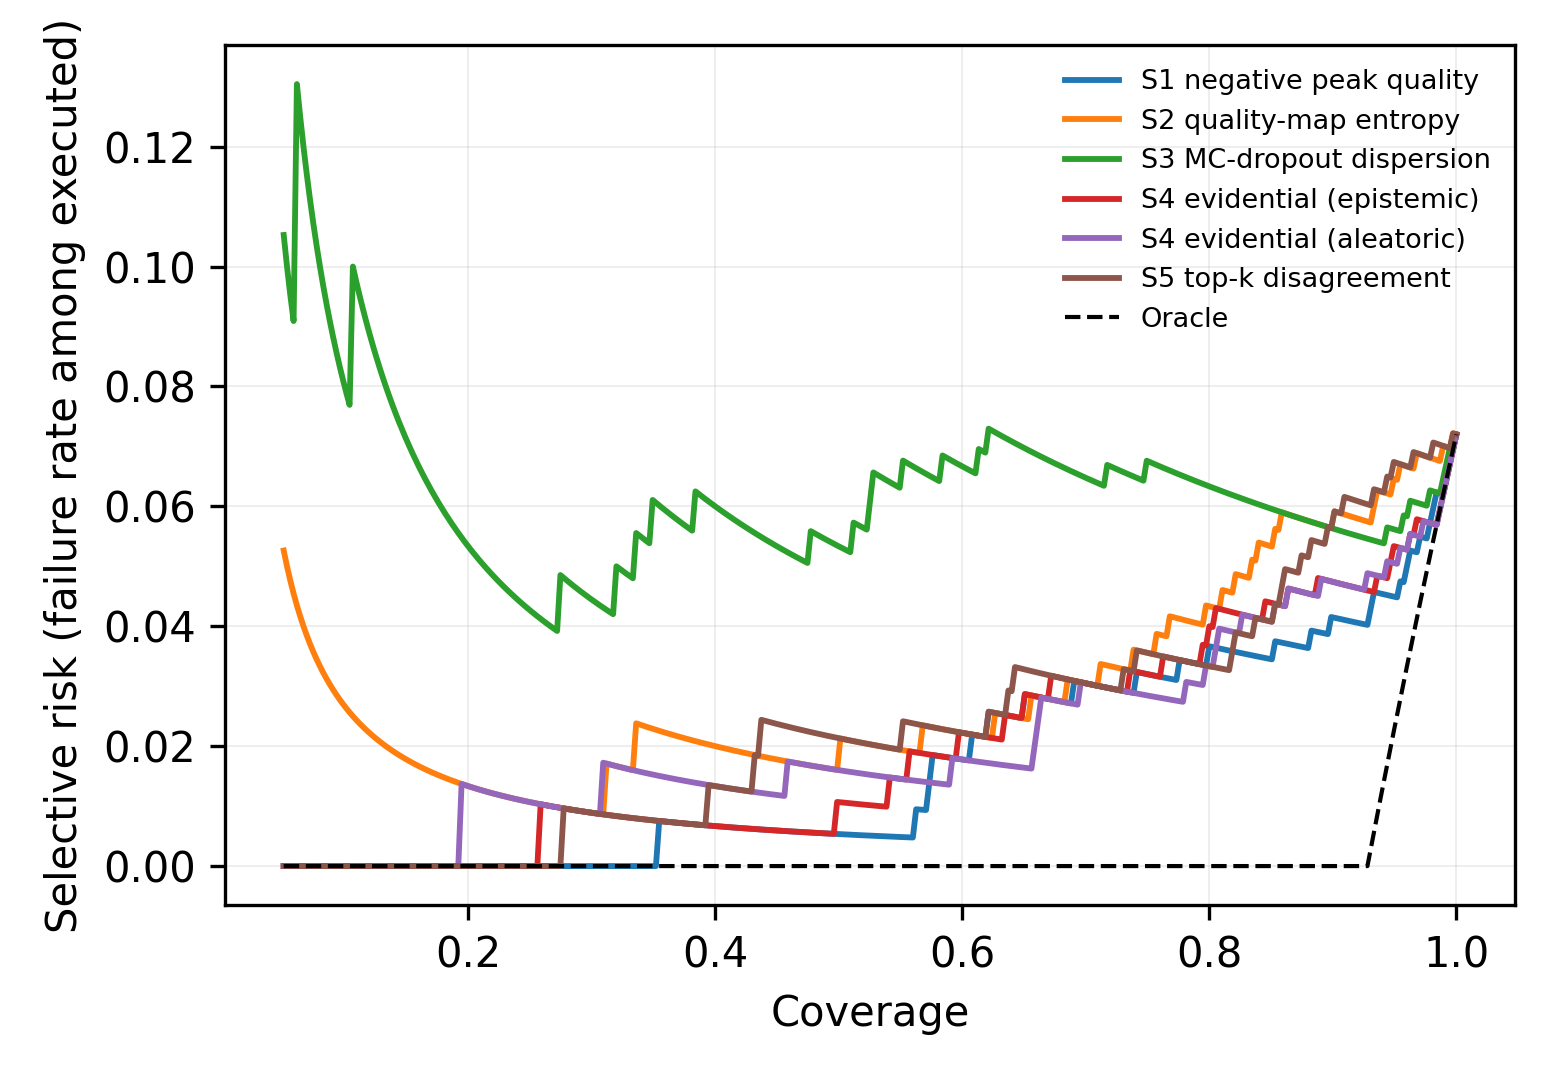

In [43]:
plot_curves(scores, loss, f'{RESULTS}/risk_coverage.png')
from IPython.display import Image, display
display(Image(f'{RESULTS}/risk_coverage.png'))

## 12b. Calibration-size scaling

The headline methodological figure: how certified coverage grows with
calibration size. Jacquard is large enough to trace this out fully, turning
Cornell's limitation into a quantified result.

In [44]:
def coverage_vs_calsize(sc, loss, alphas=(0.02,0.05,0.10),
                       sizes=(100,200,400,800,1600,3200), delta=0.10,
                       reps=30, seed=0):
    rng = np.random.default_rng(seed); n=len(loss); rows=[]
    for m in sizes:
        if m*2 > n: continue
        row={'n_cal':m}
        for a in alphas:
            covs=[]
            for _ in range(reps):
                perm=rng.permutation(n); cal,ev=perm[:m],perm[m:2*m]
                res=sg.ltt_calibrate_single(sc[cal],loss[cal],a,delta)
                tau=res.tau if res.valid else -np.inf
                covs.append(float((sc[ev]<=tau).mean()))
            row[f'cov@a={a}']=float(np.mean(covs))
        rows.append(row)
    return rows

best_s = min(scores, key=lambda k: aurc(scores[k], loss))
print(f"score: {best_s}  N={len(loss)}")
print(to_markdown(coverage_vs_calsize(scores[best_s], loss)))

score: s_conf  N=375
| n_cal | cov@a=0.02 | cov@a=0.05 | cov@a=0.1 |
|---|---|---|---|
| 100 | 0.0000 | 0.4557 | 0.6823 |



## 13. Learned abstention gate

Three-way split (gate-train / calibration / evaluation), image-wise within the
object-disjoint test partition. train_gate requires the gate-train indices, so
calibration and evaluation can't leak in.

In [45]:
def three_way_split(n, fracs=(0.25,0.45,0.30), seed=0):
    rng=np.random.default_rng(seed); idx=rng.permutation(n)
    a=int(fracs[0]*n); b=a+int(fracs[1]*n); return idx[:a],idx[a:b],idx[b:]
FRACS=tuple(cfg['selective'].get('three_way_fracs',[0.25,0.45,0.30]))
gt_idx,cal_idx,ev_idx=three_way_split(len(loss),FRACS,seed=cfg['train']['seed'])
print(f"gate-train={len(gt_idx)} calibration={len(cal_idx)} evaluation={len(ev_idx)}")

cache = np.load('scores.npz')
feats = cache['feat'].astype('float32')
import torch
device='cuda' if torch.cuda.is_available() else 'cpu'
gate=gh.AbstentionGate(in_dim=feats.shape[1], from_map=False)
gate=gh.train_gate(gate, feats, loss, gt_idx,
                   target_coverage=cfg['selective']['target_coverage'],
                   epochs=60, device=device, verbose=True)
scores['s_gate']=gh.gate_scores(gate, feats, device=device)
print("s_gate added")

gate-train=93 calibration=168 evaluation=114


/content/fisat_j/gate_head.py:274: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print(f"  epoch {ep:3d}  train_loss={float(loss):.4f}  "


  epoch   0  train_loss=2.3967  val_loss=2.3767
  epoch  10  train_loss=1.5498  val_loss=1.5478
  epoch  20  train_loss=0.7792  val_loss=0.8517
  epoch  30  train_loss=0.2929  val_loss=0.4169
  epoch  40  train_loss=0.1793  val_loss=0.3508
  epoch  50  train_loss=0.1608  val_loss=0.3594
  epoch  59  train_loss=0.1428  val_loss=0.3715
s_gate added


In [46]:
best_post=min([k for k in scores if k!='s_gate'], key=lambda k: aurc(scores[k],loss))
print(f"gate vs best post-hoc score ({best_post})")
rows=[gh.compare_at_matched_coverage(scores['s_gate'],scores[best_post],loss,coverage=cv)
      for cv in (0.9,0.85,0.8,0.7)]
print(to_markdown(rows))

gate vs best post-hoc score (s_conf)
| coverage | gate_selective_risk | posthoc_selective_risk | gate_wins | margin |
|---|---|---|---|---|
| 0.9000 | 0.0504 | 0.0415 | False | -0.0089 |
| 0.8500 | 0.0377 | 0.0346 | False | -0.0031 |
| 0.8000 | 0.0333 | 0.0367 | True | 0.0033 |
| 0.7000 | 0.0305 | 0.0305 | False | 0.0000 |



## 14. Significance (paired bootstrap + permutation)

In [47]:
print("delta AURC vs cheapest score (negative = better):")
print(to_markdown(significance_table(scores, loss, metric='AURC', n_boot=2000)))

delta AURC vs cheapest score (negative = better):
| score | vs | delta_AURC | ci95_lo | ci95_hi | distinguishable |
|---|---|---|---|---|---|
| s_ent | s_conf | 0.0132 | -0.0030 | 0.0352 | False |
| s_mc | s_conf | 0.0447 | 0.0162 | 0.0791 | True |
| s_ev_ep | s_conf | 0.0026 | -0.0004 | 0.0066 | False |
| s_ev_al | s_conf | 0.0040 | -0.0008 | 0.0102 | False |
| s_topk | s_conf | 0.0061 | 0.0013 | 0.0420 | True |
| s_gate | s_conf | 0.0075 | -0.0015 | 0.0169 | False |



In [48]:
A, B = 's_conf', 's_ev_ep'
for metric, kw in [('AURC', {}), ('C*', dict(alpha=ALPHA))]:
    r = paired_permutation_test(scores[A], scores[B], loss, metric=metric,
                                n_perm=5000, **kw)
    print(f"{A} vs {B} | {metric:4s} diff={r['observed_diff']:+.4f} "
          f"p={r['p_value']:.4f} {'sig' if r['significant'] else 'ns'}")

s_conf vs s_ev_ep | AURC diff=-0.0026 p=0.8138 ns
s_conf vs s_ev_ep | C*   diff=+0.0000 p=1.0000 ns


## 15. Qualitative figures

Four outcome cells including 'accepted but wrong'. Jacquard is synthetic RGB-D,
so caption as *predicted grasp vs annotated grasp set under the rectangle
metric*, not physical execution.

In [49]:
# Per-object qualitative figure is produced in section 15b via
# object_eval.figure_per_object (renders real images with accept/reject).
# The old make_figures.py CLI is superseded and no longer called.
print("Per-object figure: see section 15b (object_eval.figure_per_object).")

Per-object figure: see section 15b (object_eval.figure_per_object).


## 15b. Per-object simulation and evaluation

Three things GR-ConvNet-style papers show, but reframed around THIS paper's
question -- execute vs abstain -- not around raw accuracy.

**Choosing the budget alpha.** The per-object study runs at one budget, and the
right one depends on your detector. If the base failure rate is already below
alpha, "execute all" trivially meets it and the rule sits idle; too strict, and
LTT can't certify a threshold at your calibration size. The sweep below shows,
for each candidate alpha: whether LTT certifies it, the resulting coverage and
executed risk, and how many objects the rule actually discriminates on. Pick
with evidence rather than habit.

### Grid search over (score x alpha)

The single table for choosing the operating point. Every uncertainty score
crossed with every candidate budget: does LTT certify it, what coverage and
executed risk result, is the budget met, and is it trivial (base failure rate
already below alpha). `best_operating_point` picks the highest-coverage cell that
is certified, within budget, and non-trivial -- the honest best place to
operate. Scan the `within_budget=True, trivial=False, ltt_valid=True` rows: those
are the ones where the guarantee holds AND the rule is doing real work.

In [50]:
import object_eval as oe, importlib
importlib.reload(oe)

CANDIDATE_ALPHAS = [0.20, 0.15, 0.10, 0.05, 0.02]    # edit freely
grid = oe.grid_search(scores, loss, cache['obj_id'], CANDIDATE_ALPHAS, delta=DELTA)
print(f"base failure rate = {loss.mean():.4f}")
print()
print(to_markdown(grid))

bop, why = oe.best_operating_point(grid)
print()
if bop is not None:
    print(f"best operating point: score={bop['score']} alpha={bop['alpha']} "
          f"coverage={bop['coverage']} exec_risk={bop['exec_risk']}")
    print(f"  ({why})")
else:
    print("no usable operating point:", why)

base failure rate = 0.0720

| score | alpha | ltt_valid | coverage | exec_risk | within_budget | trivial |
|---|---|---|---|---|---|---|
| s_conf | 0.2000 | True | 1.0000 | 0.0720 | True | True |
| s_conf | 0.1500 | True | 1.0000 | 0.0720 | True | True |
| s_conf | 0.1000 | True | 0.9950 | 0.0670 | True | True |
| s_conf | 0.0500 | True | 0.6190 | 0.0216 | True | False |
| s_conf | 0.0200 | False | 0.0000 | 0.0000 | True | False |
| s_ent | 0.2000 | True | 1.0000 | 0.0720 | True | True |
| s_ent | 0.1500 | True | 1.0000 | 0.0720 | True | True |
| s_ent | 0.1000 | True | 0.9890 | 0.0701 | True | True |
| s_ent | 0.0500 | False | 0.0000 | 0.0000 | True | False |
| s_ent | 0.0200 | False | 0.0000 | 0.0000 | True | False |
| s_mc | 0.2000 | True | 1.0000 | 0.0720 | True | True |
| s_mc | 0.1500 | False | 0.0000 | 0.0000 | True | True |
| s_mc | 0.1000 | False | 0.0000 | 0.0000 | True | True |
| s_mc | 0.0500 | False | 0.0000 | 0.0000 | True | False |
| s_mc | 0.0200 | False | 0.0000 | 0.00

In [51]:
import object_eval as oe, importlib
importlib.reload(oe)

CANDIDATE_ALPHAS = [0.15, 0.10, 0.05, 0.02, 0.01]   # edit freely
best_s = min(scores, key=lambda k: aurc(scores[k], loss))
sweep = oe.alpha_sweep(scores[best_s], loss, cache['obj_id'],
                       CANDIDATE_ALPHAS, delta=DELTA)
print("score=" + best_s + f"   base failure rate={loss.mean():.4f}")
print()
print(to_markdown(sweep))

rec, why = oe.recommend_alpha(sweep)
print()
print("suggested alpha = " + str(rec) + "  (" + why + ")")

score=s_conf   base failure rate=0.0720

| alpha | ltt_valid | coverage | executed_risk | within_budget | objs_discriminating | trivial |
|---|---|---|---|---|---|---|
| 0.1500 | True | 1.0000 | 0.0720 | True | 0/80 | True |
| 0.1000 | True | 0.9950 | 0.0670 | True | 1/80 | True |
| 0.0500 | True | 0.6190 | 0.0216 | True | 30/80 | False |
| 0.0200 | False | 0.0000 | 0.0000 | True | 0/80 | False |
| 0.0100 | False | 0.0000 | 0.0000 | True | 0/80 | False |


suggested alpha = 0.05  (strictest budget that is certifiable and non-trivial)


### Set the budget for the object study

`ALPHA_OBJ` below is yours to set. The default takes the sweep's recommendation
-- the strictest budget that is both certifiable and non-trivial -- but override
it with any value from the table. If you pick an alpha whose `ltt_valid` is
False, the threshold is not certified and the cell says so: report that
honestly rather than presenting an uncertified operating point as guaranteed.

In [52]:
# choose one:
ALPHA_OBJ = rec              # the recommendation, or set a number e.g. 0.05
# ALPHA_OBJ = 0.05

row = next((r for r in sweep if abs(r['alpha'] - ALPHA_OBJ) < 1e-9), None)
if row is None:
    print(f"alpha={ALPHA_OBJ} was not in the sweep; running it directly")
elif not row['ltt_valid']:
    print(f"WARNING: alpha={ALPHA_OBJ} is NOT LTT-certifiable at this "
          f"calibration size. The threshold below is a plain quantile, not a "
          f"guaranteed one. Report it as uncertified, or use more calibration "
          f"data (this is exactly what Jacquard buys over Cornell).")
elif row['trivial']:
    print(f"NOTE: alpha={ALPHA_OBJ} is trivial (base failure rate <= alpha), so "
          f"'execute all' already meets it and the rule is mostly idle. A "
          f"stricter alpha shows the rejection rule doing real work.")
else:
    print(f"alpha={ALPHA_OBJ}: certifiable and non-trivial -- the rule is "
          f"exercised and the guarantee holds.")

alpha=0.05: certifiable and non-trivial -- the rule is exercised and the guarantee holds.


### Calibrate the threshold used for the object study

The per-object analysis needs one operating threshold. We take it from LTT at
the (possibly stricter) object-study alpha, on the best score, so the rule is
certified, not hand-picked.

In [53]:
from selective_grasp import ltt_calibrate_single
best_s = min(scores, key=lambda k: aurc(scores[k], loss))
res = ltt_calibrate_single(scores[best_s], loss, ALPHA_OBJ, DELTA)
tau_obj = res.tau if res.valid else float(np.quantile(scores[best_s], 0.5))
print(f"score={best_s}  LTT valid={res.valid}  tau={tau_obj:.4f}")

score=s_conf  LTT valid=True  tau=0.2152


### (2) Execution simulation — the LTT guarantee, made concrete

Physics-free: on the test set, "executing" an accepted grasp means reading its
metric-based success label. We report the failure rate AMONG executed grasps and
confirm it sits under budget. A physical simulator would add contact/slip and
could raise this risk; that is the honest scope of future closed-loop work.

In [54]:
sim = oe.simulate_execution(1 - loss, scores[best_s], tau_obj, alpha=ALPHA_OBJ)
for k in ['n_total','n_executed','coverage','executed_risk','rejected_risk',
          'risk_reduction','within_budget']:
    print(f"  {k:16s} {sim[k]}")
print()
print("executed_risk should be <= alpha (within_budget True), and")
print("rejected_risk should be HIGHER than executed_risk -- the rule is")
print("pushing the risky grasps into the rejected pile.")

  n_total          375
  n_executed       232
  coverage         0.6186666666666667
  executed_risk    0.021551724137931036
  rejected_risk    0.15384615384615385
  risk_reduction   0.05044827586206896
  within_budget    True

executed_risk should be <= alpha (within_budget True), and
rejected_risk should be HIGHER than executed_risk -- the rule is
pushing the risky grasps into the rejected pile.


### (3) Per-object table

Which objects the rule protects against. An object with low raw success but high
rejection rate is the paper's win: a hard object the rule recognised and
abstained on. Sorted by executed risk so any residual-risk objects surface at
the top.

In [55]:
tbl = oe.per_object_table(cache['obj_id'], 1 - loss, scores[best_s],
                          tau_obj, alpha=ALPHA_OBJ)
print(to_markdown(tbl[:12]))
print()
summ = oe.object_summary(tbl, alpha=ALPHA_OBJ)
print("summary:", {k: (round(v,3) if isinstance(v,float) else v)
                   for k,v in summ.items()})

| obj_id | n | raw_success | rejection_rate | coverage | executed_risk |
|---|---|---|---|---|---|
| 27 | 5 | 0.8000 | 0.6000 | 0.4000 | 0.5000 |
| 57 | 5 | 0.8000 | 0.6000 | 0.4000 | 0.5000 |
| 55 | 5 | 0.6000 | 0.4000 | 0.6000 | 0.3333 |
| 51 | 5 | 0.8000 | 0.2000 | 0.8000 | 0.2500 |
| 34 | 5 | 0.8000 | 0.0000 | 1.0000 | 0.2000 |
| 0 | 5 | 1.0000 | 0.0000 | 1.0000 | 0.0000 |
| 1 | 5 | 1.0000 | 1.0000 | 0.0000 | 0.0000 |
| 2 | 5 | 1.0000 | 0.4000 | 0.6000 | 0.0000 |
| 3 | 5 | 1.0000 | 0.0000 | 1.0000 | 0.0000 |
| 4 | 3 | 1.0000 | 0.3333 | 0.6667 | 0.0000 |
| 5 | 5 | 1.0000 | 0.0000 | 1.0000 | 0.0000 |
| 6 | 5 | 1.0000 | 1.0000 | 0.0000 | 0.0000 |


summary: {'n_objects': 80, 'mean_coverage': 0.588, 'mean_executed_risk': 0.022, 'worst_executed_risk': 0.5, 'objects_fully_rejected': 20, 'objects_over_budget': 5, 'frac_objects_within_budget': 0.938}


### (1) Per-object qualitative figure — actual images

One panel per object: the real image, the detector's predicted grasp, the
annotated grasps, and the accept/reject decision (green border = executed, red =
rejected) crossed with whether it was right. Panels are ordered so the outcomes
that carry the paper -- correct rejections and residual accepted-but-wrong
cases -- come first. This renders the DATASET images, so it needs the loaded
model and dataset from earlier sections.

In [56]:
# bias="none" keeps both executed and rejected grasps available so the figure
# can show BOTH green and red borders (ensure_both in figure_per_object)
recs = oe.per_object_visual_records(cache['idx'], cache['obj_id'],
                                    1 - loss, scores[best_s], tau_obj, bias="none")
print("outcome tally across objects:")
for k, v in oe.outcome_counts(recs).items():
    print(f"  {k:24s} {v}")

outcome tally across objects:
  accepted_correct         47
  accepted_wrong           0
  rejected_would_fail      7
  rejected_would_succeed   26


Rejected 143/375 grasps: 15% would truly have failed (correct rejections), 85% would have succeeded (over-rejection, the cost of caution). Executed 232: 227 correct, 5 wrong.

figure: 6 executed (green), 6 rejected (red)
outcome mix: {'accepted_correct': 6, 'rejected_would_fail': 3, 'rejected_would_succeed': 3}


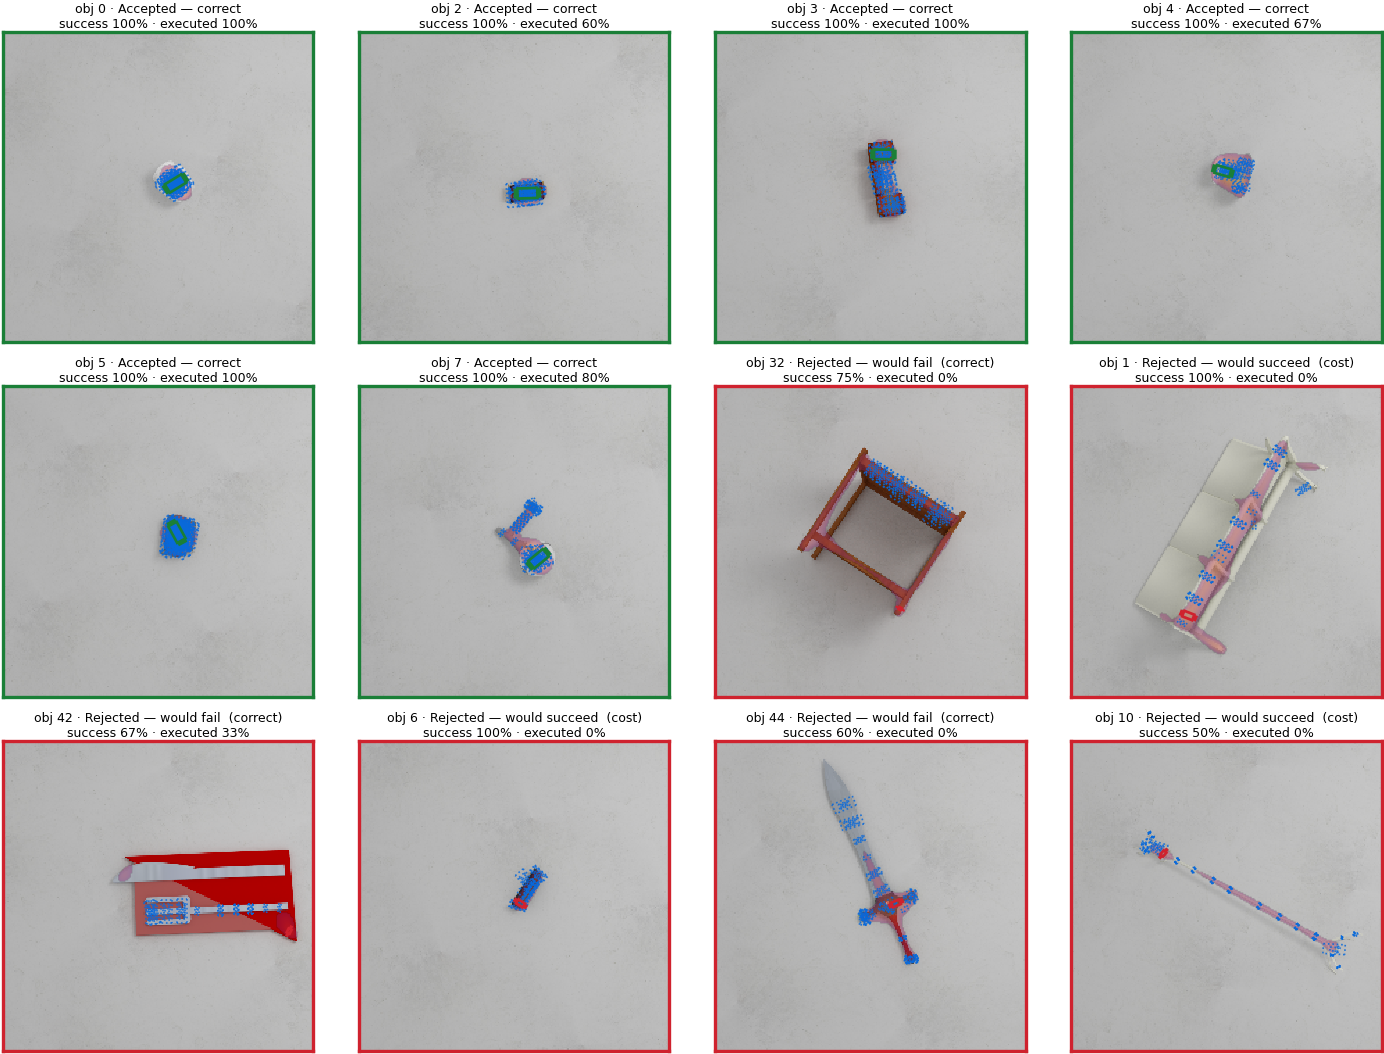

saved: /content/fisat_j/results/per_object.png


In [57]:
# rebuild the detector and dataset to fetch images for the panels
import torch, yaml
from models_grconvnet import GRConvNet
from train import make_dataset_factory

_device = 'cuda' if torch.cuda.is_available() else 'cpu'
_in_ch = 4 if cfg['data'].get('use_depth', True) else 3
_net = GRConvNet(_in_ch, dropout_prob=cfg['train'].get('dropout', 0.1))
_state = torch.load('runs/deterministic/best.pt', map_location=_device)
_net.load_state_dict(_state if 'state_dict' not in _state else _state['state_dict'])
_net.to(_device).eval()
_ds = make_dataset_factory(cfg)('test')

# global over-rejection summary, printed above the figure
print(oe.rejection_summary_line(1 - loss, scores[best_s], tau_obj))
print()

# balanced=True samples a VARIETY of outcomes (accepted-correct, rejected-
# would-fail, accepted-wrong, rejected-would-succeed) instead of filling the
# grid with whichever outcome dominates. At a strict threshold nearly every
# object is rejected, so without this the figure is all-red; balanced sampling
# shows the rule's full behaviour. Set balanced=False for "rejections first".
fig_path = oe.figure_per_object(_ds, _net, recs, f'{RESULTS}/per_object.png',
                                device=_device, max_panels=12, balanced=True)
from IPython.display import Image, display
display(Image(fig_path))
print('saved:', fig_path)

**Reading the over-rejection line.** If most rejected grasps 'would have
succeeded', the threshold is too strict -- it is discarding good grasps to stay
under budget. That is not wrong (the guarantee still holds), but it is a cost,
and the grid search above shows whether a higher alpha or a different score buys
back coverage. On a stronger detector (Jacquard) the uncertainty scores separate
good from bad grasps better, so over-rejection at the same budget is lower.

## 16. Strengthening novelty — three analyses that need no retraining

Beyond the rejection rule itself, three results deepen the contribution. All run
on the cached scores; none needs training.

### (B) The conjunctive rule as a UQ contribution

The conjunction (accept iff BOTH scores pass) isn't just "two thresholds" -- it
helps precisely when the two scores catch DIFFERENT failures. This quantifies
that: low correlation + high complementarity means the second score is buying
real coverage, not repeating the first.

In [58]:
from selective_grasp import (conjunction_complementarity, best_conjunction,
                             coverage_at_risk)
bc = best_conjunction(scores, loss, ALPHA, DELTA)
print(f"best single score : {bc['best_single']} "
      f"(coverage {bc['single_coverage']:.3f})")
print(f"best conjunction  : {bc['best_pair']} "
      f"(coverage {bc['pair_coverage']:.3f})")
print(f"coverage gained by conjoining: {bc['gain']:+.3f}")
print()
if bc['best_pair']:
    ka, kb = bc['best_pair']
    comp = conjunction_complementarity(scores[ka], scores[kb], loss)
    print(f"why it works — {ka} vs {kb}:")
    print(f"  correlation between scores : {comp['corr']:+.3f} (low = independent)")
    print(f"  failures caught only by {ka}: {comp['unique_a']*100:.0f}%")
    print(f"  failures caught only by {kb}: {comp['unique_b']*100:.0f}%")
    print(f"  complementarity (the gain) : {comp['complementarity']*100:.0f}%")

best single score : s_conf (coverage 1.000)
best conjunction  : ('s_conf', 's_ent') (coverage 0.000)
coverage gained by conjoining: -1.000

why it works — s_conf vs s_ent:
  correlation between scores : +0.450 (low = independent)
  failures caught only by s_conf: 15%
  failures caught only by s_ent: 4%
  complementarity (the gain) : 19%


### (C) Calibration-sample-size theory

The closed form behind the empirical curve. Certifying risk <= alpha at
confidence 1-delta needs, in the best case (zero calibration errors),

  n >= ln(1/delta) / (2 alpha^2)

so the required calibration set grows as 1/alpha^2. This is WHY a strict budget
needs far more data, and why Cornell's small calibration set cannot certify what
Jacquard's large one can -- stated as a law, not just observed.

In [59]:
from selective_grasp import calibration_size_table, min_calibration_size
tbl = calibration_size_table([0.15, 0.10, 0.05, 0.02, 0.01], [0.10, 0.05])
print(to_markdown(tbl))
print()
print(f"your calibration set here: ~{int(len(loss)*0.45)} samples")
print("-> budgets requiring more than that cannot be certified on this split,")
print("   which the theory predicts exactly and the LTT rows confirm.")

| alpha | n_min(delta=0.1) | n_min(delta=0.05) |
|---|---|---|
| 0.1500 | 52 | 67 |
| 0.1000 | 116 | 150 |
| 0.0500 | 461 | 600 |
| 0.0200 | 2879 | 3745 |
| 0.0100 | 11513 | 14979 |


your calibration set here: ~168 samples
-> budgets requiring more than that cannot be certified on this split,
   which the theory predicts exactly and the LTT rows confirm.


### (D) Honest negative result: when new UQ scores don't help

Two scores were tried and neither beat the standard ones on this data: GSU
(pose-basin stability) and feature-density (OOD distance). This is not a null
finding to hide -- it is evidence for a claim: the effective uncertainty signal
depends on the dataset's failure structure. Where failures are epistemic (the
detector is undertrained, as on Cornell), weight-space uncertainty (S3) wins and
geometry/OOD scores add nothing. Reporting this sharpens the paper's real
message -- that the rejection framework works with WHATEVER score fits the
dataset, and choosing that score is an empirical question.

In [60]:
# the evidence for the negative result, in one place
print("Correlation of each score with failure (this dataset):")
from numpy import corrcoef
for k in sorted(scores, key=lambda k: -abs(corrcoef(scores[k], loss)[0,1])):
    tag = {'s_mc':'  epistemic — strongest here'}.get(k, '')
    print(f"  {k:10s} {corrcoef(scores[k], loss)[0,1]:+.3f}{tag}")
print()
print("Takeaway for the paper: S3 (epistemic) leads; geometry/OOD scores lag.")
print("The rejection rule is agnostic to which score wins -- that is its point.")

Correlation of each score with failure (this dataset):
  s_ev_al    +0.438
  s_ev_ep    +0.422
  s_conf     +0.397
  s_gate     +0.327
  s_topk     +0.276
  s_mc       +0.270  epistemic — strongest here
  s_ent      +0.247

Takeaway for the paper: S3 (epistemic) leads; geometry/OOD scores lag.
The rejection rule is agnostic to which score wins -- that is its point.


## 16. Save everything to Drive

In [61]:
!mkdir -p "{DRIVE}/results" && rsync -a "{RESULTS}/" "{DRIVE}/results/"
!rsync -a "{WORK}/runs/" "{DRIVE}/runs/" && cp "{WORK}/scores.npz" "{DRIVE}/scores.npz"
import os; print("on Drive:", sorted(os.listdir(DRIVE)))

on Drive: ['JacquardV2_Dataset_0.zip', 'JacquardV2_Dataset_1.zip', 'JacquardV2_Dataset_10.zip', 'JacquardV2_Dataset_11.zip', 'JacquardV2_Dataset_2.zip', 'JacquardV2_Dataset_3.zip', 'JacquardV2_Dataset_4.zip', 'JacquardV2_Dataset_5.zip', 'JacquardV2_Dataset_6.zip', 'JacquardV2_Dataset_7.zip', 'JacquardV2_Dataset_8.zip', 'JacquardV2_Dataset_9.zip', 'results', 'runs', 'scores.npz']


---
### For the paper
- Report the alpha=0.05 (and 0.02 if it certifies) LTT coverage — the result
  Cornell couldn't give. State it as: same method, larger calibration set,
  stricter certifiable budget.
- The calibration-size curve (12b) is the methodological figure.
- State both split boundaries: object-disjoint train/test (exact on Jacquard, via
  the hash), image-wise calibration/evaluation (valid risk bound).
- Detector accuracy is context, not contribution — cite GR-ConvNet ~94.6% RGB-D
  on Jacquard and move on to C*(alpha).